
<div align="center">

<img src="https://capsule-render.vercel.app/api?type=waving&color=0:050B18,50:0B3D91,100:123B60&height=190&section=header&text=Luis%20Barahona&fontSize=42&fontColor=FFFFFF&fontAlignY=38&desc=DATA%20ENGINEERING%20%7C%20ARTIFICIAL%20INTELLIGENCE%20%7C%20DEVELOPER&descAlignY=62&descSize=14" width="50%" alt="Luis Barahona MX- Data Engineering and AI">

<img src="https://readme-typing-svg.demolab.com?font=Fira+Code&weight=500&size=17&duration=3500&pause=1200&color=38BDF8&center=true&vCenter=true&width=600&lines=Python+%7C+SQL+%7C+Data+Engineering;Artificial+Intelligence+%7C+Machine+Learning;Data+Science+%7C+Cloud+Computing;Building+Technology+for+the+Future" alt="Technical expertise">

</div>

---
<div align="center">
### Professional Profile

I am a Mexican Data Engineer and a 2026 graduate of Universidad del Caribe, passionate about technology, innovation, and continuous learning.
Beyond technical expertise, I value communication, teamwork, collaboration, and building meaningful connections with others. I believe that every person offers an opportunity to learn something new, and I am always motivated to share knowledge, explore new ideas, and grow both personally and professionally.

---

<div align="center">

<img src="https://skillicons.dev/icons?i=python,mysql,postgres,git,github,react,firebase,linux,docker,vscode&theme=dark" alt="Technical skills">


<strong>Data Engineering ·  Data Analytics · Data science · Artificial Intelligence · Machine Learning · Data Analytics · Developer</strong>

</div>

---
<div align="center">

| Platform | Contact |
|:---|:---|
| Email | [190300395@ucaribe.edu.mx](mailto:190300395@ucaribe.edu.mx) |
| GitHub | [github.com/LuisBarahonaMX](https://github.com/LuisBarahonaMX) |
| LinkedIn | [linkedin.com/in/luis-barahona-mx](https://www.linkedin.com/in/luis-barahona-mx/) |
| Instagram | [@luisbarahonamx](https://www.instagram.com/luisbarahonamx/) |
| X | [@luisbarahonaMX](https://x.com/luisbarahonaMX) |
| Website | [SIKO AI Platform](https://sikoai.web.app/) |
</div>



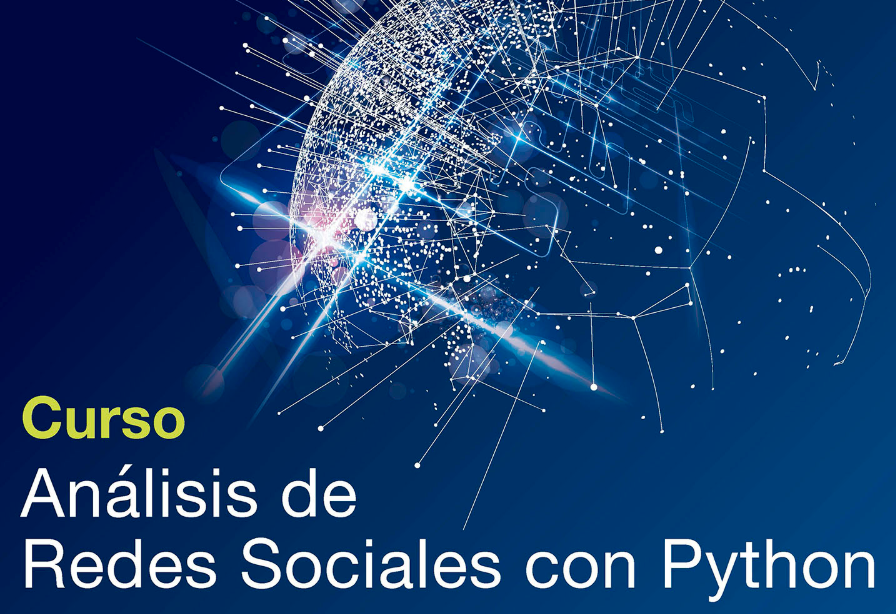

#<font color="red">DESCRIPCIÓN</font>
##las redes sociales en línea como Facebook y Twitter hasta las redes de transporte como los sistemas de bicicletas compartidas. Saber cómo analizarlas le abrirá un nuevo mundo de posibilidades como científico de datos. Este curso le brindará las habilidades para analizar, visualizar y comprender las redes. Aplicará los conceptos que aprenda a datos de redes del mundo real utilizando la poderosa biblioteca NetworkX. Con el conocimiento adquirido en este curso, desarrollará sus habilidades de pensamiento en red y podrá mirar sus datos con una perspectiva nueva.  






#<font color="red">IMPORT</font>

In [ ]:
!pip install nxviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 6.3 MB/s eta 0:00:00


# Descripción de Librerías

- **pathlib**: Manejo de rutas de archivos y directorios.
- **requests**: Realiza solicitudes HTTP.
- **networkx**: Creación y análisis de grafos/redes.
- **nxviz**: Visualización simplificada de redes.
- **annotate**: Agrega anotaciones a gráficos de redes.
- **matplotlib**: Personalización y visualización de gráficos.
- **datetime**: Manipulación de fechas y horas.
- **pprint**: Formato legible para estructuras de datos.
- **itertools**: Generación de combinaciones de elementos.
- **random**: Generación de valores aleatorios.
- **collections**: Herramientas avanzadas para estructuras de datos.
- **pickle**: Serialización y deserialización de objetos.


In [ ]:
from pathlib import Path
import requests
import networkx as nx
import nxviz as nv  # using v0.7.4
from nxviz import annotate
import matplotlib as mpl
import matplotlib.pyplot as plt
from datetime import datetime, date
from pprint import pprint as pp
from itertools import combinations
import random
from collections import Counter, defaultdict
import pickle

/usr/local/lib/python3.10/dist-packages/nxviz/__init__.py:18: UserWarning: 
nxviz has a new API! Version 0.7.4 onwards, the old class-based API is being
deprecated in favour of a new API focused on advancing a grammar of network
graphics. If your plotting code depends on the old API, please consider
pinning nxviz at version 0.7.4, as the new API will break your old code.

To check out the new API, please head over to the docs at
https://ericmjl.github.io/nxviz/ to learn more. We hope you enjoy using it!

(This deprecation message will go away in version 1.0.)

  warnings.warn(


In [ ]:
# Imprime la versión actual de NetworkX
print(f'NetworkX version: {nx.__version__}')

# Imprime la versión actual de Matplotlib
print(f'Matplotlib version: {mpl.__version__}')


NetworkX version: 3.4.2
Matplotlib version: 3.8.0


In [ ]:
def create_dir_save_file(dir_path: Path, url: str):
    """
    Check if the path exists and create it if it does not.
    Check if the file exists and download it if it does not.
    """
    if not dir_path.parents[0].exists():
        dir_path.parents[0].mkdir(parents=True)
        print(f'Directory Created: {dir_path.parents[0]}')
    else:
        print('Directory Exists')

    if not dir_path.exists():
        r = requests.get(url, allow_redirects=True)
        open(dir_path, 'wb').write(r.content)
        print(f'File Created: {dir_path.name}')
    else:
        print('File Exists')

In [ ]:
data_dir = Path('data/2020-05-21_intro_to_network_analysis_in_python')
images_dir = Path('Images/2020-05-21_intro_to_network_analysis_in_python')

#<font color="red">DATASET</font>

In [ ]:
twitter = 'https://assets.datacamp.com/production/repositories/580/datasets/64cf6963a7e8005e3771ef3b256812a5797320f0/ego-twitter.p'
github = 'https://assets.datacamp.com/production/repositories/580/datasets/69ada08d5cce7f35f38ffefe8f2291b7cfcd6000/github_users.p'

In [ ]:
datasets = [twitter, github]
data_paths = list()

for data in datasets:
    file_name = data.split('/')[-1].replace('?raw=true', '')
    data_path = data_dir / file_name
    create_dir_save_file(data_path, data)
    data_paths.append(data_path)

Directory Created: data/2020-05-21_intro_to_network_analysis_in_python
File Created: ego-twitter.p
Directory Exists
File Created: github_users.p


#<font color="red">DATA</font>

In [ ]:
# .read_gpickle is no longer available
# T = nx.read_gpickle(data_paths[0])
# Gh = nx.read_gpickle(data_paths[1])

In [ ]:
with open(data_paths[0], 'rb') as f:
    T = pickle.load(f)

with open(data_paths[1], 'rb') as f:
    Gh = pickle.load(f)

#<font color="red">INTRODUCCIÓN A LAS REDES</font>

IEn este capítulo, se le presentarán conceptos fundamentales en análisis de redes mientras explora un conjunto de datos de la red Twitter del mundo real. También aprenderá sobre [NetworkX][1], una biblioteca que le permite manipular, analizar y modelar datos de gráficos. Aprenderá sobre los diferentes tipos de gráficos y cómo visualizarlos racionalmente.
  [1]: https://networkx.github.io/documentation/stable/index.html

En este capítulo, se le presentarán conceptos fundamentales en análisis de redes mientras explora un conjunto de datos de la red Twitter del mundo real. También aprenderá sobre [NetworkX][1], una biblioteca que le permite manipular, analizar y modelar datos de gráficos. Aprenderá sobre los diferentes tipos de gráficos y cómo visualizarlos racionalmente.

#<font color="red">EXAMPLE TO NETWORKS</font>
##1. Social
- En una red social, estamos modelando la relación entre las personas.
##1. Transporte
- En una red de transporte, estamos modelando la conectividad entre ubicaciones, según lo determinado por las carreteras o rutas de vuelo que las conectan.
- **Las redes son una herramienta útil para modelar relaciones entre entidades**.

## Insights
1. **Entidades importantes**: personas influyentes en las redes sociales
1. **Búsqueda de caminos**: la ruta de transporte más eficiente
1. **Agrupamiento**: búsqueda de comunidades
- Al modelar los datos como una red, puede obtener información sobre qué entidades (o nodos) son importantes, como los locutores o las personas influyentes en una red social.
- Puede comenzar a pensar en optimizar el transporte entre ciudades.
- Aproveche la estructura de la red para encontrar comunidades en la red.

## Estructura de la red

![network_structure][1]

- Las redes se describen mediante dos conjuntos de elementos que forman una "red".
- Nodos
- Aristas
- En términos matemáticos, se trata de un gráfico.
- Los nodos y las aristas pueden tener metadatos asociados.
- Supongamos que hay dos amigos, Hugo y Eric, que se conocieron el 21 de mayo de 2016.
- Los nodos pueden ser "Hugo" y Eric, con metadatos almacenados en un par "clave-valor" como "id" y "age".
- La amistad se representa como una línea entre dos nodos y puede tener metadatos como "fecha", que representa la fecha en la que se conocieron.

![social graph][2]

## NetworkX

- Esta biblioteca de Python nos permite manipular, analizar y modelar datos de grafos.
- Usando `nx.Graph()`, inicializamos un grafo vacío, al cual podemos agregar nodos y aristas
- Los enteros 1, 2 y 3 pueden ser ingresados ​​como nodos, usando el método `add_nodes_from`, pasando la lista `[1, 2, 3]`, como argumento.
- Usa el método `.nodes` para ver los nodos presentes en el grafo.
- De manera similar, usa `.add_edges` y `.edges` para agregar y ver las aristas presentes en el grafo.
- Las aristas entre nodos son representadas como una tupla, en la cual cada tupla muestra los nodos que están presentes en esa arista.

```python
import networkx as nx

G = nx.Graph()
G.add_nodes_from([1, 2, 3])
G.nodes()
>>> [1, 2, 3]
G.add_edge(1, 2)
G.edges()
>>> [(1, 2)]
```

- Los metadatos también se pueden almacenar en el gráfico.
- Por ejemplo, puedo agregar al nodo `1`, una clave `label` con el valor `blue`, tal como asignaría un valor a la clave de un diccionario.
- La lista de nodos se puede recuperar con `G.nodes()` y pasando el parámetro `data=True`.
- Esto devuelve una lista de tuplas, en la que el primer elemento de cada tupla es el nodo, y el segundo elemento es un diccionario, en el que los pares `key-value` corresponden a los metadatos.

```python
G.node[1]['label'] = 'blue'
G.nodes(data=True)
>>>[(1, {'label': 'blue}), (2, {}), (3, {})]
```

- `networkx` proporciona una funcionalidad básica de dibujo, utilizando la función `nx.draw()`, que toma un gráfico `G` como argumento.
- En el shell de IPyhton, también deberá llamar a la función `plt.show()` para mostrar la pantalla del gráfico.
- Con este gráfico, la función `nx.draw()` dibujará en la pantalla lo que llamamos una representación del gráfico en forma de **diagrama de nodos y enlaces**.

```python
import matplotlib.pyplot as plt

nx.draw(G)
plt.show()
```

-- El primer conjunto de ejercicios que realizaremos es esencialmente un análisis exploratorio de datos en gráficos.

### Other Resources
1. [Wikipedia: Network Theory][3]


  [1]: https://raw.githubusercontent.com/trenton3983/DataCamp/master/Images/2020-05-21_intro_to_network_analysis_in_python/network_structure_1.JPG
  [2]: https://raw.githubusercontent.com/trenton3983/DataCamp/master/Images/2020-05-21_intro_to_network_analysis_in_python/network_structure_2.JPG
  [3]: https://en.wikipedia.org/wiki/Network_theory

# ¿Qué es una red?

Pensemos de nuevo en ejemplos de redes. ¿Cuál de los siguientes datos es menos fácil de modelar como una red?

- ~~Transporte aéreo.~~
- **Números de teléfono en una guía telefónica.**
- ~~Coautoría de artículos.~~
- ~~Átomos en una molécula.~~

1. En comparación con las otras opciones, no sería tan fácil modelar números de teléfono en una guía telefónica como una red.

# Conceptos básicos de la API de NetworkX usando una red de Twitter  

Para comenzar con la API de NetworkX, revisaremos algunas funciones básicas que te permitirán consultar una red de Twitter que ha sido precargada y está disponible en el Shell de IPython como `T`.  

La red de Twitter proviene de [KONECT][1] y muestra una instantánea de un subconjunto de usuarios de Twitter. Es una red de Twitter anonimizada con metadatos.

Ahora vas a utilizar la API de NetworkX para explorar algunas propiedades básicas de la red y se te anima a experimentar con los datos en el Shell de IPython.

Espera a que el Shell de IPython indique que el gráfico ha sido precargado bajo el nombre de variable `T` (que representa una red de Twitter) y luego responde la siguiente pregunta:

**¿Cuál es el tamaño del gráfico `T`, el tipo de `T.nodes()` y la estructura de datos del tercer elemento del último borde listado en `T.edges(data=True)`?** Las funciones `len()` y `type()` serán útiles aquí. Para acceder a la última entrada de `T.edges(data=True)`, puedes usar `list(T.edges(data=True))[-1]`.  

- **23369, `networkx.classes.reportviews.NodeView`, `dict`.**
- ~~32369, `tuple`, `datetime`.~~
- ~~23369, `networkx.classes.reportviews.NodeView`, `datetime`.~~
- ~~22339, `dict`, `dict`.~~

  [1]: http://konect.uni-koblenz.de/

In [ ]:
print(len(T))
print(type(T.nodes()))
print(list(T.edges(data=True))[-1])
print(type(list(T.edges(data=True))[-1][2]))

23369
<class 'networkx.classes.reportviews.NodeView'>
(23324, 23336, {'date': datetime.date(2010, 9, 20)})
<class 'dict'>


# Dibujo básico de una red usando NetworkX  

NetworkX proporciona una funcionalidad básica de dibujo que funciona para gráficos pequeños. Hemos seleccionado un subconjunto de nodos del gráfico para que practiques utilizando las herramientas de dibujo de NetworkX. Este subconjunto ha sido precargado como `T_sub`.  

**Instrucciones**  

- Importa `matplotlib.pyplot` como `plt` y `networkx` como `nx`.  
- Dibuja `T_sub` en la pantalla usando la función `nx.draw()` y no olvides usar `plt.show()` para mostrarlo.  

## Creando `T_sub`  
- Usa [DiGraph][1] en lugar de [Graph][2].  
- [¿Por qué los bordes agregados con `G.add_edges_from()` no coinciden con `G.edges()`?][3]  


  [1]: https://networkx.github.io/documentation/networkx-1.10/reference/classes.digraph.html#networkx.DiGraph  
  [2]: https://networkx.github.io/documentation/networkx-1.10/reference/classes.graph.html#networkx.Graph  
  [3]: https://stackoverflow.com/questions/62032404/why-dont-edges-added-with-g-add-edges-from-match-g-edges

In [ ]:
T_sub = nx.DiGraph()  # Crear un grafo dirigido vacío

# Filtrar bordes de T donde el nodo de origen está en la lista especificada
# y el nodo de destino es menor que 50
edges_from_T = [x for x in T.edges(list(range(50)), data=True)
                if x[0] in [1, 16, 18, 19, 28, 36, 37, 39, 42, 43, 45]
                if x[1] < 50]

# Agregar los bordes filtrados al subgrafo T_sub
T_sub.add_edges_from(edges_from_T)


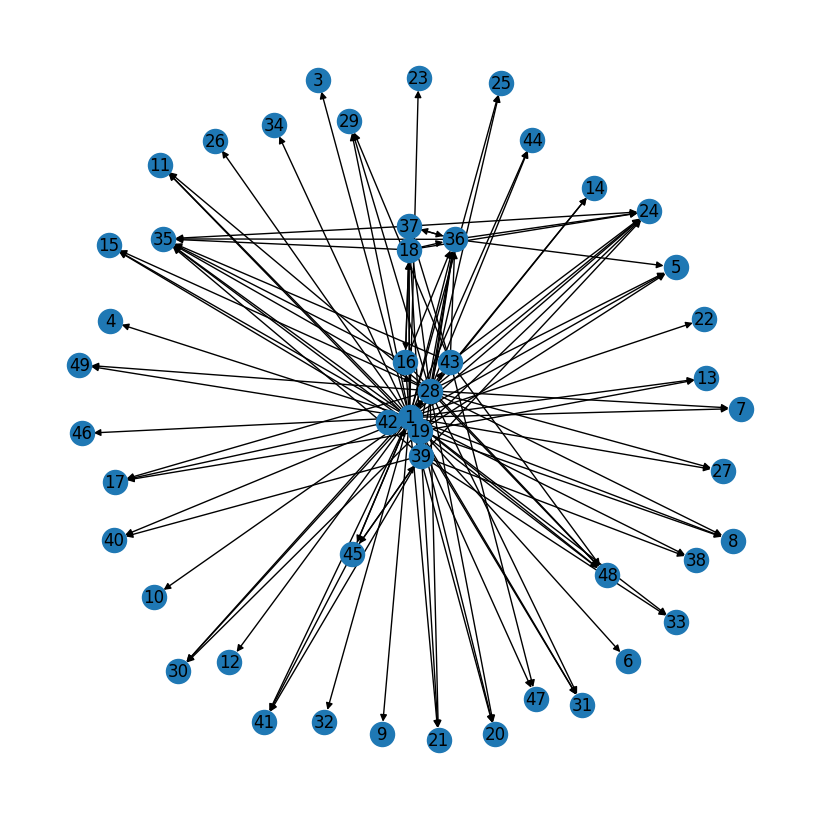

In [ ]:
plt.figure(figsize=(8, 8))  # Crear una figura de tamaño 8x8

# Dibujar el subgrafo T_sub con etiquetas de nodos
nx.draw(T_sub, with_labels=True)

# Mostrar la figura dibujada
plt.show()


# Consultas en un grafo  

Ahora que conoces algunas propiedades básicas del grafo y has practicado utilizando las herramientas de dibujo de NetworkX para visualizar sus componentes, es hora de explorar cómo consultar nodos y bordes. Específicamente, buscarás "nodos de interés" y "bordes de interés". Para ello, usarás los métodos `.nodes()` y `.edges()`.  

- El método `.nodes()` devuelve una lista de nodos.  
- El método `.edges()` devuelve una lista de tuplas, donde cada tupla muestra los nodos presentes en ese borde.  

Si agregas el argumento `data=True`, obtendrás también los metadatos asociados con los nodos y bordes.  

Utilizarás listas por comprensión para realizar consultas de manera eficiente en una sola línea. Aquí está la estructura básica de una lista por comprensión:  

```python
[expresión_de_salida for variable_iteradora in iterable if expresión_condicional]
```

Deberás completar el `_iterable_` y la `_expresión_condicional_`. Si lo prefieres, puedes probar tu respuesta explorando el grafo en la consola de IPython.  

**Instrucciones:**  

1. **Lista de nodos:**  
   - Usa una lista por comprensión para obtener una **lista de nodos** del grafo `T` que tengan la etiqueta `'occupation'` con el valor `'scientist'`.  
   - La _expresión de salida_ `n` y las _variables iteradoras_ `n` y `d` ya están especificadas. Completa el _iterable_ y la _expresión condicional_.  
   - Usa el método `.nodes()` de `T` y especifica `data=True` para obtener los metadatos de los nodos.  
   - La variable iteradora `d` es un diccionario. La clave de interés es `'occupation'` y su valor esperado es `'scientist'`.  

2. **Lista de bordes:**  
   - Usa una lista por comprensión para obtener una **lista de bordes** del grafo `T` que se hayan formado durante al menos 6 años, es decir, desde antes del **1 de enero de 2010**.  
   - Completa el _iterable_ y la _expresión condicional_.  
   - Usa el método `.edges()` de `T` para acceder a sus bordes, asegurándote de incluir los metadatos.  
   - Las fechas están almacenadas como objetos `datetime.date` en el diccionario `d` bajo la clave `'date'`. Para acceder a la fecha 1 de enero de 2009, usarías `date(2009, 1, 1)`.  

[1]: https://www.datacamp.com/courses/python-data-science-toolbox-part-2

In [ ]:
# Utiliza una lista por comprensión para obtener los nodos de interés: noi
noi = [n for n, d in T.nodes(data=True) if d['occupation'] == 'scientist']

# Utiliza una lista por comprensión para obtener los bordes de interés: eoi
eoi = [(u, v) for u, v, d in T.edges(data=True) if d['date'].year < 2010]


In [ ]:
print(noi[:10])
print(eoi[:10])

[5, 9, 13, 15, 17, 19, 20, 22, 23, 27]
[(1, 5), (1, 9), (1, 13), (1, 15), (1, 16), (1, 17), (1, 18), (1, 19), (1, 24), (1, 27)]


Aquí tienes la traducción del markdown al español:

## Tipos de Grafos

1. Grafos no dirigidos
 - Facebook
 - Están compuestos por aristas que no tienen ninguna direccionalidad inherente asociada a ellas.
 - En el caso de Facebook, por ejemplo, cuando un usuario se hace amigo de otro, ambos quedan automáticamente conectados por una arista.
 - Esto comúnmente se dibuja como una línea sin flechas entre dos círculos.
 - Los grafos no dirigidos tienen el tipo `Graph`.

```python
import networkx as nx

G = nx.Graph()
type(G)
>>> networkx.classes.graph.Graph
```

2. Grafos dirigidos
 - Twitter
 - Esto se debe a la naturaleza de cómo los usuarios interactúan entre sí.
 - Por ejemplo, un usuario puede seguir a otro, pero ese otro usuario puede no seguir de vuelta.
 - Como tal, existe una direccionalidad inherente asociada al grafo.
 - Los grafos dirigidos tienen el tipo `DiGraph`.

```python
D = nx.DiGraph()
type(D)
>>> networkx.classes.digraph.DiGraph
```

3. Grafos con múltiples aristas (dirigidos)
 - Grafo en el que se permiten múltiples aristas entre los nodos.
 - Por ejemplo, podríamos querer modelar los viajes entre estaciones de bicicletas compartidas.
 - Cada viaje podría ser una arista entre el par de estaciones.
 - A veces, por razones prácticas, puede ser demasiado intensivo en memoria modelar múltiples aristas por par de nodos, por lo que se podría elegir colapsar las aristas en una sola que contenga un resumen de los metadatos de las originales.
    - Por ejemplo, podríamos querer colapsar estas tres aristas en una sola y darle un metadato de _peso_ con el valor _3_, indicando que originalmente había 3 aristas entre el par de nodos.

![multi-edge][1]

```python
M = nx.MultiGraph
type(M)
>>> networkx.classes.multigraph.MultiGraph

MD = nx.MultiDiGraph
type(MD)
>>> networkx.classes.multidigraph.MultiDiGraph
```

4. Auto-bucles
 - Los auto-bucles se pueden usar en ciertos escenarios, como en los datos de bicicletas compartidas, donde un viaje comienza en una estación y termina en la misma estación.

  [1]: https://raw.githubusercontent.com/trenton3983/DataCamp/master/Images/2020-05-21_intro_to_network_analysis_in_python/multi-edge.JPG

## Comprobando el estado dirigido/no dirigido de un grafo

¿Qué tipo de grafo crees que corresponde a los datos de la red de Twitter con los que has estado trabajando? Usa la función incorporada de Python `type()` en el IPython Shell para averiguarlo. La red, como antes, ha sido precargada como `T`.

De las cuatro opciones a continuación, ¿cuál corresponde al tipo de grafo que es `T`?

- ~~Grafo No Dirigido.~~
- **Grafo Dirigido.**
- ~~Grafo No Dirigido con Múltiples Aristas.~~
- ~~Grafo Dirigido con Múltiples Aristas.~~

## Especificando un peso en las aristas

*   Elemento de lista
*   Elemento de lista

Los pesos pueden agregarse a las aristas de un grafo, generalmente indicando la "fuerza" de una arista. En NetworkX, el peso se indica mediante la clave `'weight'` en el diccionario de metadatos.

Antes de intentar el ejercicio, usa el IPython Shell para acceder al diccionario de metadatos de `T` y explóralo, por ejemplo, ejecutando los comandos `T.edges[1, 10]` y luego `T.edges[10, 1]`. Nota cómo solo hay un campo, y ahora vas a agregar otro campo llamado `'weight'`.

**Instrucciones**

- Establece el atributo `'weight'` de la arista entre el nodo `1` y `10` de `T` igual a `2`. Referencia el siguiente formato para establecer un atributo de una arista: `network_name.edges[node1, node2]['attribute'] = value`. Aquí, el `'attribute'` es `'weight'`.
- Establece el peso de cada arista que involucre el nodo `293` igual a `1.1`. Para hacer esto:
  - Usando un ciclo `for`, itera sobre todas las aristas de `T`, incluyendo los `metadatos`.
  - Si `293` está involucrado en la lista de nodos `[u, v]`:
    - Establece el peso de la arista entre `u` y `v` a `1.1`.

In [ ]:
# Establecer el peso de la arista
T.edges[1, 10]['weight'] = 2

# Iterar sobre todas las aristas (con metadatos)
for u, v, data in T.edges(data=True):

    # Comprobar si el nodo 293 está involucrado
    if 293 in [u, v]:

        # Establecer el peso a 1.1
        T.edges[u, v]['weight'] = 1.1



## Comprobando si hay auto-bucles en el grafo

NetworkX también permite aristas que comienzan y terminan en el mismo nodo; aunque esto no sería intuitivo para un grafo de redes sociales, es útil para modelar datos como redes de viajes, en las que las personas comienzan en una ubicación y terminan en otra.

Es útil comprobar esto antes de proceder con análisis adicionales, y los grafos de NetworkX proporcionan un método para este propósito: `.number_of_selfloops()`.

En este ejercicio, así como en los siguientes, encontrarás útil la instrucción `assert`. Una afirmación `assert` verifica si la declaración que sigue a continuación evalúa a True; de lo contrario, lanzará un `AssertionError`.

Para comenzar, usa el método `.number_of_selfloops()` en `T` en el IPython Shell para obtener el número de aristas que comienzan y terminan en el mismo nodo. Se han agregado de manera sintética varios auto-bucles al grafo. Tu tarea en este ejercicio es escribir una función que devuelva estas aristas.

**Instrucciones**

- Define una función llamada `find_selfloop_nodes()` que tome un argumento: `G`.
  - Usando un ciclo `for`, itera sobre todas las aristas en `G` (excluyendo los metadatos).
  - Si el nodo `u` es igual al nodo `v`:
    - Agrega `u` a la lista `nodes_in_selfloops`.
    - Devuelve la lista `nodes_in_selfloops`.
- Verifica que el número de auto-bucles en el grafo sea igual al número de nodos en los auto-bucles.

In [ ]:
# Definir la función find_selfloop_nodes()
def find_selfloop_nodes(G):
    """
    Encuentra todos los nodos que tienen auto-bucles en el grafo G.
    """
    nodes_in_selfloops = []

    # Iterar sobre todas las aristas de G
    for u, v in G.edges():

        # Comprobar si el nodo u y el nodo v son el mismo
        if u == v:

            # Agregar el nodo u a nodes_in_selfloops
            nodes_in_selfloops.append(u)

    return nodes_in_selfloops

# Comprobar si el número de auto-bucles es igual al número de nodos en los auto-bucles
# number_of_selfloops() está obsoleto
assert len(list(nx.selfloop_edges(T))) == len(find_selfloop_nodes(T))


In [ ]:
# Comprobar si el número de auto-bucles es igual al número de nodos en los auto-bucles
# La función selfloop_edges() obtiene todas las aristas que son auto-bucles en el grafo T
len(list(nx.selfloop_edges(T)))


42

**There are 42 nodes in T that have self-loops.**

Aquí tienes el markdown traducido al español:

# Visualización de Redes

1. **Gráficos de matriz**
   - ![matrix_plots][1]
   - Los nodos son las filas y columnas de una matriz, y las celdas se llenan según si existe una arista entre los pares de nodos.
   - En un grafo no dirigido, la matriz es simétrica alrededor de la diagonal, que se resalta en gris.
   - Figura 3: la arista (A, B) es equivalente a la arista (B, A). Resaltado en amarillo.
   - Figura 4: la arista (A, C) es equivalente a la arista (C, A), porque no hay dirección asociada con esa arista.
   - Con los grafos dirigidos, la representación de la matriz no necesariamente será simétrica.
   - Figura 5: hay una arista bidireccional entre A y C, pero solo una arista de A a B y no de B a A.
       - (A, B) se llenará, pero no (B, A).
   - Si los nodos están ordenados a lo largo de las filas y columnas, de manera que los vecinos estén cerca unos de otros, entonces un gráfico de matriz puede ser usado para visualizar clústeres o comunidades de nodos.

2. **Gráficos de arco**
   - ![arc_plots][2]
   - Son una transformación del diagrama de nodos y enlaces, en la cual los nodos se ordenan a lo largo de un eje del gráfico, y las aristas se dibujan usando arcos circulares de un nodo a otro.
   - Si los nodos están ordenados de acuerdo con alguna regla de ordenación, como la edad en una red social de usuarios, o agrupados por ubicación geográfica en un mapa para una red de transporte, entonces será posible visualizar la relación entre la conectividad y la propiedad ordenada (o agrupada).
   - Los gráficos de arco son un buen punto de partida para visualizar una red, ya que forman la base de los gráficos que veremos más adelante.

3. **Gráficos Circos**
   - ![circo_plot][3]
   - Son una transformación del gráfico de arco, de manera que los dos extremos del gráfico de arco se unen en un círculo.
   - Fueron diseñados originalmente para su uso en genómica, y se pueden ver como una alternativa estética y compacta a los gráficos de arco.
   
- Usarás [nxviz][4] para trazar los gráficos.

```python
import nxviz as nv
import matplotlib.pyplot as plt
ap = nv.ArcPlot(G)
ap.draw()
plt.show()
```

  [1]: https://raw.githubusercontent.com/trenton3983/DataCamp/master/Images/2020-05-21_intro_to_network_analysis_in_python/matrix_plots.JPG
  [2]: https://raw.githubusercontent.com/trenton3983/DataCamp/master/Images/2020-05-21_intro_to_network_analysis_in_python/arc_plots.JPG
  [3]: https://raw.githubusercontent.com/trenton3983/DataCamp/master/Images/2020-05-21_intro_to_network_analysis_in_python/circo_plots.JPG
  [4]: https://github.com/ericmjl/nxviz

Aquí tienes la traducción del markdown al español:

### Visualización usando gráficos de matriz

Es hora de probar tu primer método de visualización de gráficos "avanzado": un gráfico de matriz. Para hacerlo, `nxviz` proporciona un objeto `MatrixPlot`.

`nxviz` es un paquete para visualizar grafos de una manera racional. Bajo el capó, el `MatrixPlot` utiliza `nx.to_numpy_matrix(G)`, que devuelve la forma matricial del grafo. Aquí, cada nodo es una columna y una fila, y una arista entre los dos nodos se indica con el valor 1. Sin embargo, al hacer esto, solo se conserva la metadata de `weight`; toda la otra metadata se pierde, como podrás verificar usando una declaración `assert`.

Un `nx.from_numpy_matrix(A)` correspondiente permite crear rápidamente un grafo a partir de una matriz de NumPy. El tipo de grafo por defecto es `Graph()`; si deseas que sea un `DiGraph()`, debes especificarlo utilizando el argumento `create_using`, por ejemplo, (`nx.from_numpy_matrix(A, create_using=nx.DiGraph)`).

Una última nota, `matplotlib.pyplot` y `networkx` ya han sido importados como `plt` y `nx`, respectivamente, y el grafo `T` ya ha sido pre-cargado. Para simplicidad y rapidez, solo hemos submuestreado 100 aristas de la red.

**Instrucciones**

- Importa `nxviz` como `nv`.
- Dibuja el grafo `T` como un gráfico de matriz. Para hacerlo:
  - Crea el objeto `MatrixPlot` llamado `m` usando la función `nv.MatrixPlot()` con `T` pasado como argumento.
  - Dibuja el `m` en la pantalla usando el método `.draw()`.
  - Muestra el gráfico usando `plt.show()`.
- Convierte el grafo a formato de matriz, y luego convierte el grafo de nuevo a la forma de NetworkX desde la matriz como un grafo dirigido.
- Verifica que el campo de metadata `category` se haya perdido de cada nodo.

In [ ]:
data = [(13829, 1386, {'date': date(2012, 3, 13)}), (3086, 669, {'date': date(2009, 3, 1)}), (3086, 3100, {'date': date(2013, 8, 10)}), (3086, 3117, {'date': date(2007, 12, 20)}), (4111, 4133, {'date': date(2007, 10, 28)}), (4111, 12582, {'date': date(2013, 6, 1)}), (6163, 7331, {'date': date(2013, 2, 3)}), (6163, 7336, {'date': date(2007, 9, 12)}), (6163, 6168, {'date': date(2008, 4, 2)}), (6163, 1326, {'date': date(2009, 2, 16)}), (4636, 4666, {'date': date(2012, 3, 20)}), (543, 12123, {'date': date(2014, 8, 12)}), (36, 24, {'date': date(2009, 4, 23)}), (12836, 12856, {'date': date(2014, 2, 21)}), (10790, 10854, {'date': date(2009, 8, 11)}), (9262, 9338, {'date': date(2007, 11, 11)}), (4160, 4161, {'date': date(2012, 4, 14)}), (4160, 3681, {'date': date(2013, 8, 10)}), (7746, 3396, {'date': date(2007, 2, 23)}), (7746, 543, {'date': date(2011, 7, 14)}), (7746, 5073, {'date': date(2012, 2, 25)}), (7746, 1130, {'date': date(2013, 8, 4)}), (7746, 3265, {'date': date(2008, 11, 8)}), (19013, 21248, {'date': date(2009, 3, 21)}), (19013, 21253, {'date': date(2007, 8, 17)}), (14916, 14930, {'date': date(2012, 4, 10)}), (5717, 5752, {'date': date(2009, 2, 2)}), (3159, 3176, {'date': date(2011, 8, 15)}), (3159, 3177, {'date': date(2008, 2, 1)}), (3159, 3193, {'date': date(2014, 1, 2)}), (1627, 1648, {'date': date(2011, 11, 7)}), (19550, 19570, {'date': date(2009, 11, 13)}), (5215, 5217, {'date': date(2011, 1, 7)}), (4198, 16203, {'date': date(2014, 12, 1)}), (3177, 3159, {'date': date(2010, 6, 2)}), (3177, 3176, {'date': date(2014, 11, 10)}), (1134, 2406, {'date': date(2011, 7, 10)}), (1134, 543, {'date': date(2011, 10, 20)}), (4206, 21962, {'date': date(2014, 4, 17)}), (6770, 2671, {'date': date(2010, 5, 18)}), (11384, 4955, {'date': date(2007, 2, 12)}), (11384, 2406, {'date': date(2007, 10, 13)}), (11384, 11402, {'date': date(2009, 11, 27)}), (10877, 10917, {'date': date(2014, 7, 17)}), (10877, 7886, {'date': date(2009, 1, 4)}), (10877, 36, {'date': date(2008, 10, 25)}), (10877, 10936, {'date': date(2008, 12, 26)}), (10877, 1326, {'date': date(2012, 1, 19)}), (10373, 1386, {'date': date(2011, 4, 21)}), (10373, 2501, {'date': date(2012, 8, 13)}), (3213, 3214, {'date': date(2008, 4, 19)}), (3213, 3265, {'date': date(2007, 8, 8)}), (3213, 3266, {'date': date(2009, 1, 4)}), (5626, 16654, {'date': date(2011, 3, 5)}), (20122, 20177, {'date': date(2014, 12, 21)}), (667, 669, {'date': date(2014, 2, 3)}), (667, 747, {'date': date(2008, 2, 23)}), (161, 18159, {'date': date(2014, 9, 22)}), (7331, 6163, {'date': date(2012, 10, 15)}), (7331, 6168, {'date': date(2012, 3, 17)}), (7331, 7606, {'date': date(2008, 11, 7)}), (7331, 24, {'date': date(2009, 9, 21)}), (7331, 36, {'date': date(2010, 5, 26)}), (10917, 10877, {'date': date(2011, 9, 7)}), (10917, 24, {'date': date(2014, 10, 16)}), (10917, 7886, {'date': date(2011, 7, 13)}), (10917, 36, {'date': date(2013, 8, 8)}), (10917, 1326, {'date': date(2009, 5, 23)}), (22184, 22188, {'date': date(2012, 11, 3)}), (6318, 6301, {'date': date(2011, 4, 3)}), (8367, 8421, {'date': date(2012, 7, 10)}), (21167, 3931, {'date': date(2012, 7, 9)}), (3265, 4955, {'date': date(2012, 6, 6)}), (3265, 4811, {'date': date(2014, 9, 18)}), (3265, 3266, {'date': date(2008, 9, 24)}), (3266, 4811, {'date': date(2007, 2, 16)}), (3266, 1926, {'date': date(2008, 3, 16)}), (3266, 3265, {'date': date(2014, 5, 25)}), (4291, 4306, {'date': date(2014, 9, 9)}), (4291, 4310, {'date': date(2007, 9, 11)}), (4811, 4955, {'date': date(2007, 4, 19)}), (4811, 3265, {'date': date(2013, 8, 23)}), (4811, 3266, {'date': date(2008, 8, 25)}), (7886, 10877, {'date': date(2012, 9, 5)}), (7886, 10917, {'date': date(2008, 9, 19)}), (7886, 24, {'date': date(2014, 8, 17)}), (7886, 36, {'date': date(2012, 9, 21)}), (7886, 1326, {'date': date(2012, 3, 23)}), (6863, 14981, {'date': date(2012, 8, 7)}), (13012, 13017, {'date': date(2012, 3, 4)}), (16597, 24, {'date': date(2012, 5, 2)}), (16597, 36, {'date': date(2011, 4, 19)}), (16597, 16610, {'date': date(2011, 11, 11)}), (12507, 12523, {'date': date(2012, 3, 11)}), (16618, 16619, {'date': date(2013, 3, 3)}), (13036, 15161, {'date': date(2012, 4, 23)}), (3826, 669, {'date': date(2014, 11, 9)}), (3826, 3100, {'date': date(2009, 2, 24)}), (3826, 3860, {'date': date(2013, 7, 27)}), (3826, 3681, {'date': date(2013, 2, 14)}), (7410, 7437, {'date': date(2012, 5, 2)}), (15092, 2148, {'date': date(2014, 11, 11)}), (15092, 20816, {'date': date(2009, 4, 8)}), (2820, 2826, {'date': date(2011, 10, 1)}), (2820, 2871, {'date': date(2010, 3, 26)}), (2311, 2371, {'date': date(2008, 8, 26)}), (11020, 11042, {'date': date(2008, 5, 12)}), (13070, 13079, {'date': date(2009, 10, 15)}), (20755, 24, {'date': date(2010, 11, 26)}), (20755, 1326, {'date': date(2014, 5, 2)}), (20756, 669, {'date': date(2012, 9, 7)}), (20756, 3100, {'date': date(2013, 3, 17)}), (20756, 3681, {'date': date(2010, 12, 9)}), (14613, 14617, {'date': date(2009, 6, 2)}), (10004, 10030, {'date': date(2008, 3, 1)}), (10004, 10111, {'date': date(2011, 7, 15)}), (4892, 1130, {'date': date(2011, 12, 10)}), (4892, 4947, {'date': date(2012, 3, 6)}), (2871, 15372, {'date': date(2014, 4, 27)}), (6968, 669, {'date': date(2010, 2, 6)}), (6968, 1386, {'date': date(2012, 9, 20)}), (6968, 4133, {'date': date(2012, 9, 22)}), (3385, 3396, {'date': date(2008, 3, 4)}), (8001, 23190, {'date': date(2008, 6, 26)}), (19787, 13581, {'date': date(2012, 4, 3)}), (21325, 21371, {'date': date(2009, 8, 2)}), (16720, 16734, {'date': date(2007, 10, 26)}), (16720, 16739, {'date': date(2008, 10, 24)}), (12119, 24, {'date': date(2013, 6, 1)}), (12119, 36, {'date': date(2007, 5, 1)}), (22872, 22918, {'date': date(2014, 7, 15)}), (7519, 16041, {'date': date(2012, 7, 8)}), (12640, 18082, {'date': date(2007, 4, 20)}), (12640, 18086, {'date': date(2008, 7, 8)}), (5987, 4957, {'date': date(2010, 12, 4)}), (5987, 492, {'date': date(2009, 6, 25)}), (19316, 19344, {'date': date(2013, 3, 15)}), (19316, 2501, {'date': date(2011, 11, 15)}), (13690, 4955, {'date': date(2014, 4, 5)}), (12162, 15560, {'date': date(2011, 1, 4)}), (2443, 3564, {'date': date(2014, 1, 9)}), (401, 492, {'date': date(2010, 11, 25)}), (401, 502, {'date': date(2013, 6, 27)}), (9106, 9107, {'date': date(2012, 5, 4)}), (8598, 8616, {'date': date(2011, 2, 6)}), (21919, 4161, {'date': date(2007, 7, 18)}), (21919, 669, {'date': date(2011, 12, 12)}), (21919, 3100, {'date': date(2012, 10, 15)}), (21919, 3681, {'date': date(2011, 1, 14)}), (10143, 4306, {'date': date(2009, 5, 26)}), (4517, 6414, {'date': date(2008, 7, 15)}), (20906, 2406, {'date': date(2012, 9, 5)}), (20906, 492, {'date': date(2013, 8, 12)}), (6059, 20368, {'date': date(2008, 11, 20)}), (2501, 1386, {'date': date(2009, 5, 1)}), (2501, 10373, {'date': date(2012, 7, 15)}), (13257, 13286, {'date': date(2008, 11, 4)}), (1484, 1492, {'date': date(2008, 6, 5)}), (1484, 1499, {'date': date(2013, 8, 9)}), (1996, 6038, {'date': date(2012, 7, 28)}), (20947, 669, {'date': date(2011, 7, 19)}), (20947, 3100, {'date': date(2010, 11, 23)}), (20947, 3681, {'date': date(2008, 6, 20)}), (5590, 5601, {'date': date(2012, 8, 17)}), (5590, 5626, {'date': date(2013, 8, 18)}), (18917, 19012, {'date': date(2013, 12, 15)}), (18917, 19013, {'date': date(2014, 1, 17)}), (10730, 24, {'date': date(2010, 1, 21)}), (10730, 36, {'date': date(2014, 1, 11)}), (10730, 1326, {'date': date(2008, 11, 4)}), (23024, 669, {'date': date(2010, 6, 15)}), (23024, 3100, {'date': date(2012, 6, 1)}), (23024, 23091, {'date': date(2011, 5, 20)}), (5109, 5112, {'date': date(2007, 5, 10)}), (13306, 13334, {'date': date(2014, 5, 18)})]
attr = {13829: {'category': 'D', 'occupation': 'celebrity'}, 15372: {'category': 'D', 'occupation': 'celebrity'}, 3086: {'category': 'P', 'occupation': 'scientist'}, 4111: {'category': 'D', 'occupation': 'scientist'}, 6163: {'category': 'P', 'occupation': 'scientist'}, 13334: {'category': 'P', 'occupation': 'scientist'}, 6168: {'category': 'P', 'occupation': 'celebrity'}, 24: {'category': 'P', 'occupation': 'politician'}, 3100: {'category': 'D', 'occupation': 'scientist'}, 4636: {'category': 'D', 'occupation': 'celebrity'}, 543: {'category': 'D', 'occupation': 'politician'}, 36: {'category': 'D', 'occupation': 'scientist'}, 12836: {'category': 'I', 'occupation': 'celebrity'}, 4133: {'category': 'D', 'occupation': 'scientist'}, 10790: {'category': 'D', 'occupation': 'scientist'}, 3117: {'category': 'P', 'occupation': 'politician'}, 9262: {'category': 'I', 'occupation': 'scientist'}, 23091: {'category': 'P', 'occupation': 'celebrity'}, 12856: {'category': 'D', 'occupation': 'politician'}, 4666: {'category': 'P', 'occupation': 'politician'}, 4160: {'category': 'P', 'occupation': 'politician'}, 4161: {'category': 'I', 'occupation': 'politician'}, 7746: {'category': 'P', 'occupation': 'scientist'}, 19012: {'category': 'D', 'occupation': 'politician'}, 19013: {'category': 'I', 'occupation': 'politician'}, 14916: {'category': 'I', 'occupation': 'politician'}, 14930: {'category': 'P', 'occupation': 'celebrity'}, 5717: {'category': 'P', 'occupation': 'politician'}, 3159: {'category': 'I', 'occupation': 'scientist'}, 1627: {'category': 'I', 'occupation': 'scientist'}, 19550: {'category': 'D', 'occupation': 'politician'}, 5215: {'category': 'P', 'occupation': 'politician'}, 5217: {'category': 'D', 'occupation': 'scientist'}, 3681: {'category': 'I', 'occupation': 'politician'}, 2148: {'category': 'D', 'occupation': 'politician'}, 4198: {'category': 'D', 'occupation': 'celebrity'}, 10854: {'category': 'D', 'occupation': 'politician'}, 3176: {'category': 'D', 'occupation': 'scientist'}, 3177: {'category': 'I', 'occupation': 'scientist'}, 1130: {'category': 'I', 'occupation': 'celebrity'}, 1134: {'category': 'P', 'occupation': 'scientist'}, 4206: {'category': 'I', 'occupation': 'scientist'}, 2671: {'category': 'P', 'occupation': 'scientist'}, 1648: {'category': 'P', 'occupation': 'politician'}, 19570: {'category': 'P', 'occupation': 'scientist'}, 6770: {'category': 'D', 'occupation': 'celebrity'}, 5752: {'category': 'D', 'occupation': 'scientist'}, 11384: {'category': 'D', 'occupation': 'politician'}, 3193: {'category': 'P', 'occupation': 'politician'}, 9338: {'category': 'I', 'occupation': 'politician'}, 10877: {'category': 'P', 'occupation': 'celebrity'}, 10373: {'category': 'I', 'occupation': 'politician'}, 14981: {'category': 'P', 'occupation': 'celebrity'}, 11402: {'category': 'I', 'occupation': 'politician'}, 3213: {'category': 'D', 'occupation': 'politician'}, 3214: {'category': 'P', 'occupation': 'celebrity'}, 5626: {'category': 'P', 'occupation': 'politician'}, 23190: {'category': 'P', 'occupation': 'celebrity'}, 20122: {'category': 'D', 'occupation': 'politician'}, 667: {'category': 'P', 'occupation': 'politician'}, 6301: {'category': 'I', 'occupation': 'scientist'}, 669: {'category': 'I', 'occupation': 'celebrity'}, 161: {'category': 'D', 'occupation': 'politician'}, 18082: {'category': 'I', 'occupation': 'celebrity'}, 7331: {'category': 'I', 'occupation': 'celebrity'}, 10917: {'category': 'P', 'occupation': 'scientist'}, 18086: {'category': 'D', 'occupation': 'scientist'}, 22184: {'category': 'P', 'occupation': 'scientist'}, 7336: {'category': 'D', 'occupation': 'scientist'}, 16041: {'category': 'P', 'occupation': 'scientist'}, 22188: {'category': 'I', 'occupation': 'scientist'}, 6318: {'category': 'P', 'occupation': 'politician'}, 8367: {'category': 'I', 'occupation': 'politician'}, 21167: {'category': 'D', 'occupation': 'celebrity'}, 10936: {'category': 'P', 'occupation': 'scientist'}, 3265: {'category': 'I', 'occupation': 'celebrity'}, 3266: {'category': 'P', 'occupation': 'politician'}, 4291: {'category': 'P', 'occupation': 'politician'}, 15560: {'category': 'P', 'occupation': 'celebrity'}, 4811: {'category': 'P', 'occupation': 'politician'}, 7886: {'category': 'P', 'occupation': 'politician'}, 6863: {'category': 'I', 'occupation': 'scientist'}, 20177: {'category': 'P', 'occupation': 'scientist'}, 4306: {'category': 'P', 'occupation': 'scientist'}, 13012: {'category': 'D', 'occupation': 'celebrity'}, 16597: {'category': 'P', 'occupation': 'celebrity'}, 4310: {'category': 'D', 'occupation': 'scientist'}, 13017: {'category': 'I', 'occupation': 'politician'}, 12507: {'category': 'I', 'occupation': 'politician'}, 16610: {'category': 'I', 'occupation': 'celebrity'}, 8421: {'category': 'I', 'occupation': 'politician'}, 16618: {'category': 'D', 'occupation': 'politician'}, 16619: {'category': 'I', 'occupation': 'celebrity'}, 13036: {'category': 'D', 'occupation': 'politician'}, 12523: {'category': 'P', 'occupation': 'politician'}, 747: {'category': 'D', 'occupation': 'politician'}, 18159: {'category': 'P', 'occupation': 'celebrity'}, 3826: {'category': 'P', 'occupation': 'politician'}, 7410: {'category': 'D', 'occupation': 'scientist'}, 15092: {'category': 'I', 'occupation': 'scientist'}, 21248: {'category': 'I', 'occupation': 'politician'}, 2820: {'category': 'I', 'occupation': 'celebrity'}, 21253: {'category': 'P', 'occupation': 'celebrity'}, 2311: {'category': 'I', 'occupation': 'politician'}, 2826: {'category': 'D', 'occupation': 'celebrity'}, 11020: {'category': 'D', 'occupation': 'politician'}, 7437: {'category': 'P', 'occupation': 'celebrity'}, 16654: {'category': 'I', 'occupation': 'scientist'}, 6414: {'category': 'D', 'occupation': 'scientist'}, 13070: {'category': 'I', 'occupation': 'politician'}, 13581: {'category': 'D', 'occupation': 'politician'}, 20755: {'category': 'D', 'occupation': 'celebrity'}, 20756: {'category': 'I', 'occupation': 'scientist'}, 14613: {'category': 'I', 'occupation': 'celebrity'}, 10004: {'category': 'I', 'occupation': 'politician'}, 3860: {'category': 'D', 'occupation': 'celebrity'}, 13079: {'category': 'D', 'occupation': 'celebrity'}, 14617: {'category': 'P', 'occupation': 'celebrity'}, 4892: {'category': 'P', 'occupation': 'celebrity'}, 11042: {'category': 'I', 'occupation': 'celebrity'}, 12582: {'category': 'P', 'occupation': 'politician'}, 1326: {'category': 'D', 'occupation': 'scientist'}, 10030: {'category': 'I', 'occupation': 'celebrity'}, 2871: {'category': 'P', 'occupation': 'scientist'}, 6968: {'category': 'P', 'occupation': 'celebrity'}, 3385: {'category': 'D', 'occupation': 'scientist'}, 15161: {'category': 'D', 'occupation': 'scientist'}, 8001: {'category': 'P', 'occupation': 'celebrity'}, 2371: {'category': 'D', 'occupation': 'scientist'}, 3396: {'category': 'P', 'occupation': 'scientist'}, 16203: {'category': 'D', 'occupation': 'politician'}, 19787: {'category': 'D', 'occupation': 'politician'}, 21325: {'category': 'P', 'occupation': 'scientist'}, 20816: {'category': 'I', 'occupation': 'scientist'}, 16720: {'category': 'I', 'occupation': 'scientist'}, 4947: {'category': 'I', 'occupation': 'celebrity'}, 12119: {'category': 'D', 'occupation': 'politician'}, 22872: {'category': 'I', 'occupation': 'politician'}, 12123: {'category': 'D', 'occupation': 'celebrity'}, 4955: {'category': 'P', 'occupation': 'celebrity'}, 4957: {'category': 'D', 'occupation': 'celebrity'}, 16734: {'category': 'D', 'occupation': 'politician'}, 7519: {'category': 'I', 'occupation': 'politician'}, 12640: {'category': 'P', 'occupation': 'celebrity'}, 3931: {'category': 'I', 'occupation': 'celebrity'}, 5987: {'category': 'D', 'occupation': 'scientist'}, 16739: {'category': 'I', 'occupation': 'celebrity'}, 2406: {'category': 'I', 'occupation': 'scientist'}, 1386: {'category': 'I', 'occupation': 'politician'}, 19316: {'category': 'I', 'occupation': 'politician'}, 13690: {'category': 'I', 'occupation': 'celebrity'}, 21371: {'category': 'P', 'occupation': 'scientist'}, 10111: {'category': 'I', 'occupation': 'celebrity'}, 12162: {'category': 'I', 'occupation': 'celebrity'}, 22918: {'category': 'I', 'occupation': 'celebrity'}, 1926: {'category': 'D', 'occupation': 'celebrity'}, 2443: {'category': 'I', 'occupation': 'scientist'}, 20368: {'category': 'I', 'occupation': 'politician'}, 19344: {'category': 'D', 'occupation': 'politician'}, 401: {'category': 'P', 'occupation': 'celebrity'}, 9106: {'category': 'P', 'occupation': 'scientist'}, 9107: {'category': 'D', 'occupation': 'celebrity'}, 6038: {'category': 'I', 'occupation': 'celebrity'}, 8598: {'category': 'P', 'occupation': 'politician'}, 21919: {'category': 'I', 'occupation': 'celebrity'}, 10143: {'category': 'P', 'occupation': 'celebrity'}, 4517: {'category': 'D', 'occupation': 'celebrity'}, 8616: {'category': 'D', 'occupation': 'celebrity'}, 20906: {'category': 'D', 'occupation': 'celebrity'}, 6059: {'category': 'D', 'occupation': 'scientist'}, 7606: {'category': 'P', 'occupation': 'scientist'}, 2501: {'category': 'P', 'occupation': 'scientist'}, 13257: {'category': 'D', 'occupation': 'celebrity'}, 21962: {'category': 'D', 'occupation': 'politician'}, 1484: {'category': 'I', 'occupation': 'politician'}, 1996: {'category': 'D', 'occupation': 'celebrity'}, 5073: {'category': 'P', 'occupation': 'celebrity'}, 20947: {'category': 'I', 'occupation': 'celebrity'}, 1492: {'category': 'D', 'occupation': 'celebrity'}, 5590: {'category': 'I', 'occupation': 'politician'}, 1499: {'category': 'P', 'occupation': 'celebrity'}, 5601: {'category': 'P', 'occupation': 'scientist'}, 18917: {'category': 'D', 'occupation': 'celebrity'}, 13286: {'category': 'I', 'occupation': 'scientist'}, 10730: {'category': 'D', 'occupation': 'celebrity'}, 492: {'category': 'I', 'occupation': 'politician'}, 3564: {'category': 'P', 'occupation': 'scientist'}, 23024: {'category': 'P', 'occupation': 'politician'}, 5109: {'category': 'I', 'occupation': 'politician'}, 502: {'category': 'P', 'occupation': 'scientist'}, 5112: {'category': 'I', 'occupation': 'celebrity'}, 13306: {'category': 'D', 'occupation': 'scientist'}}
t_131 = nx.DiGraph()
t_131.add_nodes_from(attr)
t_131.add_edges_from(data)
nx.set_node_attributes(t_131, attr)

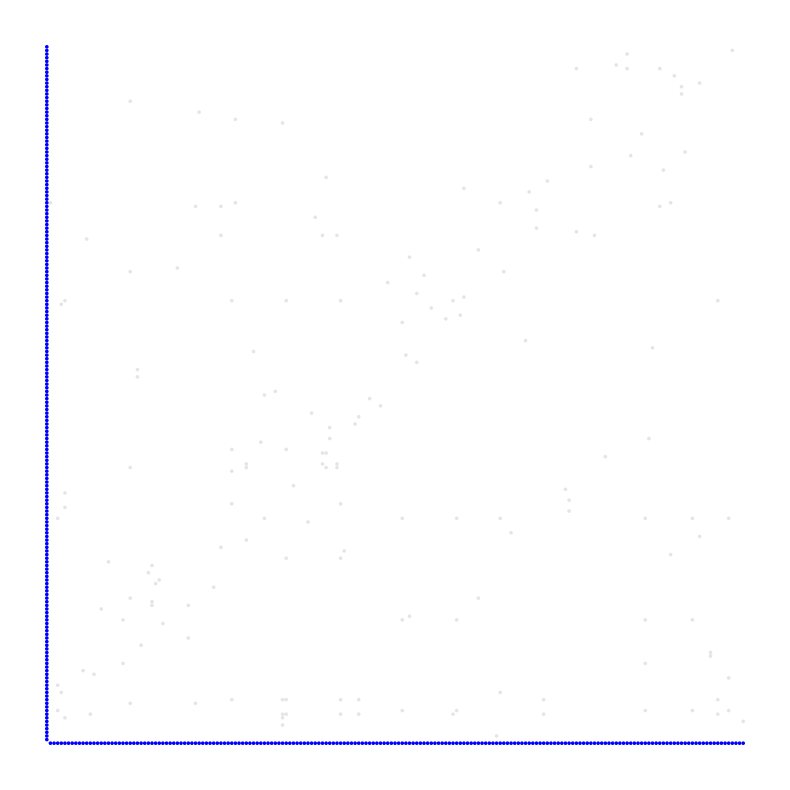

In [ ]:
# Crear el objeto MatrixPlot: m
plt.figure(figsize=(10, 10))
m = nv.matrix(t_131)


In [ ]:
# Convertir T a un formato de matriz: A
A = nx.to_numpy_array(t_131)

# Convertir A nuevamente al formato de NetworkX como un grafo dirigido: T_conv
T_conv = nx.from_numpy_array(A, create_using=nx.DiGraph())

# Verificar que el campo de metadatos `category` se ha perdido de cada nodo
for n, d in T_conv.nodes(data=True):
    assert 'category' not in d.keys()


# Visualización utilizando gráficos Circos

Los gráficos Circos son una forma racional y sin desorden de visualizar datos de grafos, en la cual los nodos se ordenan alrededor de la circunferencia de alguna manera, y los bordes se dibujan dentro del círculo resultante, ofreciendo una visualización tanto hermosa como informativa sobre la estructura de la red.

En este ejercicio, continuarás practicando con la API de `nxviz`, esta vez con el objeto `CircosPlot`. `matplotlib.pyplot` ya ha sido importado como `plt` para ti.

**Instrucciones**

- Importa `CircosPlot` desde `nxviz`.
- Dibuja la red de Twitter `T` como un gráfico Circos sin ningún estilo. Usa la función `CircosPlot()` para esto. No olvides dibujarlo en la pantalla usando `.draw()` y luego mostrarlo con `plt.show()`.

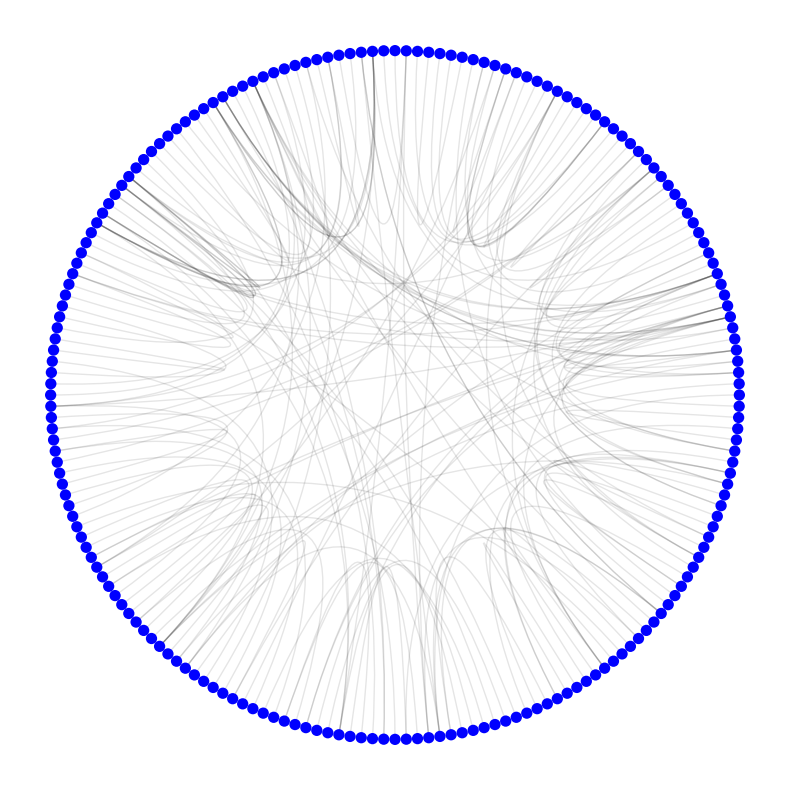

In [ ]:
# Crea el objeto CircosPlot: c
plt.figure(figsize=(10, 10))
ax = nv.circos(t_131)

# Visualización utilizando gráficos de Arco

Siguiendo con lo que has aprendido sobre la API de `nxviz`, ahora intenta crear un gráfico de Arco de la red. Dos argumentos clave que probarás aquí son `node_order='keyX'` y `node_color='keyX'`, en los que especificas una clave en el diccionario de metadatos del nodo para ordenar y colorear los nodos.

`matplotlib.pyplot` ya ha sido importado como `plt` para ti.

**Instrucciones**

- Importa `ArcPlot` desde `nxviz`.
- Crea un gráfico de Arco sin personalizar de `T`. Para hacerlo, usa la función `ArcPlot()` con solo `T` como argumento.
- Crea otro gráfico de Arco de `T` en el que los nodos estén ordenados y coloreados por la clave `'category'`. Deberás especificar los parámetros `node_order` y `node_color` para hacerlo. Para ambos gráficos, asegúrate de dibujarlos en la pantalla y mostrarlos con `plt.show()`.

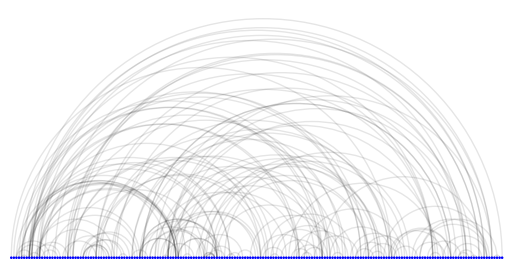

In [ ]:
# Cree el objeto ArcPlot no personalizado: alt.figure(figsize=(10, 10))
a = nv.arc(t_131)

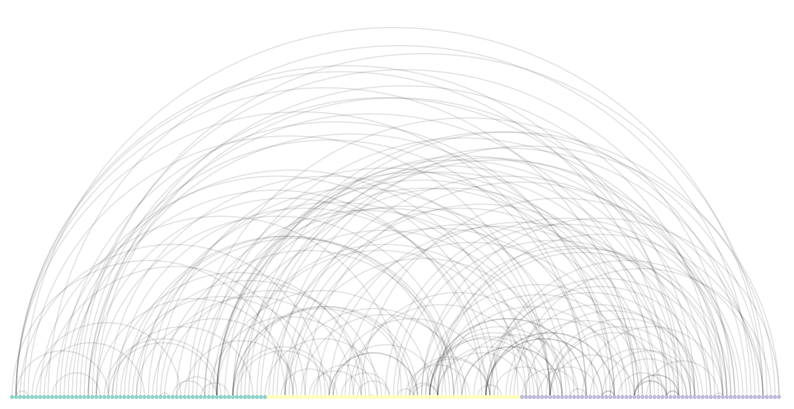

In [ ]:
# Crea el objeto ArcPlot personalizado: a2
plt.figure(figsize=(10, 10))
ax = nv.arc(t_131, node_color_by='category', group_by='category')



###Observa el coloreado de los nodos en el gráfico de Arco personalizado en comparación con la versión sin personalizar. En el gráfico de Arco personalizado, los nodos en cada una de las categorías - `'I'`, `'D'` y `'P'` - tienen su propio color. Si te resulta difícil verlo en tu pantalla, puedes expandir el gráfico en una nueva ventana haciendo clic en el icono de expansión en la parte superior izquierda, junto a 'Plots'.**

# Nodos importantes

Aprenderás sobre las formas de identificar nodos que son importantes en una red. Al hacerlo, serás introducido a conceptos más avanzados en el análisis de redes, así como a los fundamentos de los algoritmos de búsqueda de caminos. El capítulo concluye con un análisis profundo del conjunto de datos de la red de Twitter, lo que reforzará los conceptos que has aprendido, como la centralidad de grado y la centralidad de intermediación.

# Centralidad de Grado

- Cómo determinar qué nodos son importantes.
- ¿Qué nodo central podría ser más importante?
  - ![star_graph][1]
  - El nodo central del gráfico de la izquierda es más importante porque está conectado a más nodos.
  - Estar conectado a otros nodos significa que esos nodos son considerados vecinos de ese nodo.
- A partir del concepto de vecinos, ahora podemos introducir el concepto de _centralidad de grado_.
1. Centralidad de grado
  - Esta es una de las muchas métricas que podemos usar para evaluar la importancia de un nodo, y se define simplemente como el número de vecinos que tiene un nodo dividido por el número total de vecinos que el nodo podría tener: $\frac{\text{Número de vecinos que tengo}}{\text{Número de vecinos que podría tener}}$.
  - Aquí hay dos escenarios posibles:
    - Si se permiten autoenlaces, como en un mapa de red de todos los viajes en bicicleta en un sistema de bicicletas compartidas, entonces el número de vecinos que podría tener es cada nodo en el gráfico, incluyendo a mí mismo.
    - Si no se permiten autoenlaces, como en la red social de Twitter, donde, por definición, mi cuenta no puede seguirse a sí misma, el número de vecinos que podría tener es cada otro nodo en el gráfico, excluyéndome a mí mismo.
  - En la vida real, algunos ejemplos de nodos en un gráfico con alta centralidad de grado podrían ser:
    - Locutores de Twitter, es decir, usuarios que son seguidos por muchos otros usuarios.
    - Centros de transporte de aeropuertos, como Nueva York, Londres o Tokio.
    - Supercontagiadores de enfermedades, quienes son los individuos que los epidemiólogos querrían rastrear para ayudar a detener la propagación de una enfermedad.
1. Centralidad de intermediación

### Número de vecinos

```python
G.edges()
>>> [(1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9)]

G.neighbors(1)
>>> [2, 3, 4, 5, 6, 7, 8, 9]

G.neighbors(8)
>>> [1]

G.neighbors(10)
>>> NetworkXError: The node 10 is not in the graph.
```

### Centralidad de Grado

- No se consideran los autoenlaces.

```python
nx.degree_centrality(G)
>>> {1: 1.0,
     2: 0.125,
     3: 0.125,
     4: 0.125,
     5: 0.125,
     6: 0.125,
     7: 0.125,
     8: 0.125,
     9: 0.125}
```

  [1]: https://raw.githubusercontent.com/trenton3983/DataCamp/master/Images/2020-05-21_intro_to_network_analysis_in_python/star_graphs.JPG

#Aquí tienes la traducción al español del markdown:

## Calcular el número de vecinos de cada nodo

¿Cómo evalúas si un nodo es importante o no? Hay varias maneras de hacerlo, y aquí vamos a ver una métrica: el número de vecinos que tiene un nodo.

Cada gráfico de NetworkX `G` expone un método `.neighbors(n)` que devuelve una lista de nodos que son los vecinos del nodo `n`. Para comenzar, usa este método en el Shell de IPython sobre la red de Twitter `T` para obtener los vecinos del nodo `1`. Esto te familiarizará con cómo funciona la función. Luego, tu tarea en este ejercicio es escribir una función que devuelva todos los nodos que tienen `m` vecinos.

**Instrucciones**

- Escribe una función llamada `nodes_with_m_nbrs()` que tenga dos parámetros: `G` y `m`, y que devuelva todos los nodos que tienen `m` vecinos. Para hacer esto:
  - Itera sobre todos los nodos en `G` (**no** incluyendo los metadatos).
  - Usa las funciones `len()` y `list()` junto con el método `.neighbors()` para calcular el número total de vecinos que el nodo `n` en el gráfico `G` tiene.
    - Si el número de vecinos del nodo `n` es igual a `m`, agrega `n` al conjunto `nodes` usando el método `.add()`.
  - Después de iterar sobre todos los nodos en `G`, devuelve el conjunto `nodes`.
- Usa tu función `nodes_with_m_nbrs()` para recuperar todos los nodos que tienen 6 vecinos en el gráfico `T`.

In [ ]:
# Definir nodes_with_m_nbrs()
def nodes_with_m_nbrs(G, m):
    """
    Devuelve todos los nodos en el grafo G que tienen m vecinos.
    """
    nodos = set()

    # Iterar sobre todos los nodos en G
    for n in G.nodes():

        # Comprobar si el número de vecinos de n coincide con m
        if len(list(G.neighbors(n))) == m:

            # Agregar el nodo n al conjunto
            nodos.add(n)

    # Devolver los nodos con m vecinos
    return nodos

# Calcular e imprimir todos los nodos en T que tienen 6 vecinos
seis_vecinos = nodes_with_m_nbrs(T, 6)
print(seis_vecinos)


{22533, 1803, 11276, 11279, 6161, 4261, 10149, 3880, 16681, 5420, 14898, 64, 14539, 6862, 20430, 9689, 475, 1374, 6112, 9186, 17762, 14956, 2927, 11764, 4725}



[texto del enlace](https://)**El número de vecinos que tiene un nodo es una forma de identificar nodos importantes. Parece que 25 nodos en el grafo `T` tienen 6 vecinos.**

# Calcular la distribución de grados

El número de vecinos que tiene un nodo se llama su "grado", y es posible calcular la distribución de grados a lo largo de todo el grafo. En este ejercicio, tu tarea es calcular la distribución de grados en `T`.

**Instrucciones**

- Utiliza una comprensión de listas junto con el método `.neighbors(n)` para obtener el grado de cada nodo. El resultado debe ser una lista de enteros.
  - Usa `n` como tu _variable iteradora_.
  - La _expresión de salida_ de tu comprensión de listas debe ser el número de vecinos que tiene el nodo `n` — es decir, su grado. Usa las funciones `len()` y `list()` junto con el método `.neighbors()` para calcular esto.
  - El _iterable_ en tu comprensión de listas son todos los nodos en `T`, a los que se accede usando el método `.nodes()`.
- Imprime los grados.

In [ ]:
grados = [len(list(T.neighbors(n))) for n in T.nodes()]
grados[:20]


[47, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 17, 0, 10, 27, 0, 0]

# Distribución de la centralidad de grado

El grado de un nodo es el número de vecinos que tiene. La centralidad de grado es el número de vecinos dividido por todos los vecinos posibles que podría tener. Dependiendo de si se permiten bucles auto-conectados (self-loops), el conjunto de vecinos posibles de un nodo también podría incluir el nodo en sí mismo.

La función `nx.degree_centrality(G)` devuelve un diccionario, donde las claves son los nodos y los valores son sus valores de centralidad de grado.

La distribución de grados `grados` que calculaste en el ejercicio anterior utilizando la comprensión de listas ha sido pre-cargada.

**Instrucciones**

- Calcula la centralidad de grado de la red de Twitter `T`.
- Usando `plt.hist()`, traza un histograma de la distribución de la centralidad de grado de `T`. Esto se puede acceder usando `list(deg_cent.values())`.
- Traza un histograma de la distribución de grados `grados` de `T`. Esta es la misma lista que calculaste en el último ejercicio.
- Crea un gráfico de dispersión con `grados` en el eje x y la distribución de centralidad de grado `list(deg_cent.values())` en el eje y.

In [ ]:
# Calcular la centralidad de grado de la red de Twitter: deg_cent
deg_cent = nx.degree_centrality(T)

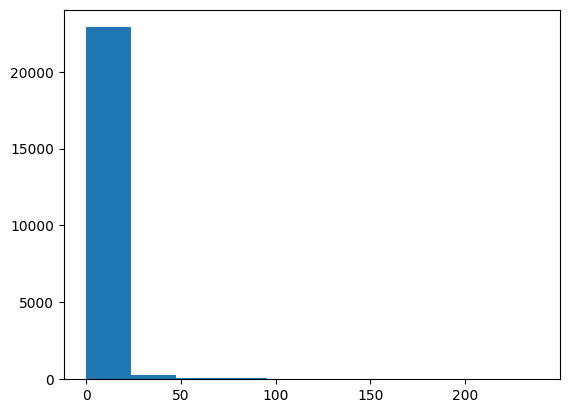

In [ ]:
# Calcula la distribución de grados
degrees = [len(list(T.neighbors(n))) for n in T.nodes()]

# Traza un histograma de la distribución de grados del grafo
plt.figure()
plt.hist(degrees)
plt.show()


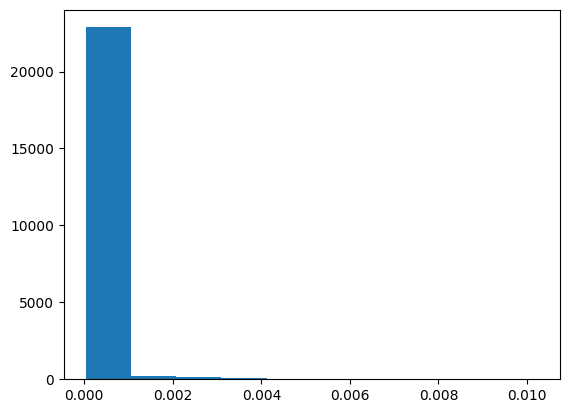

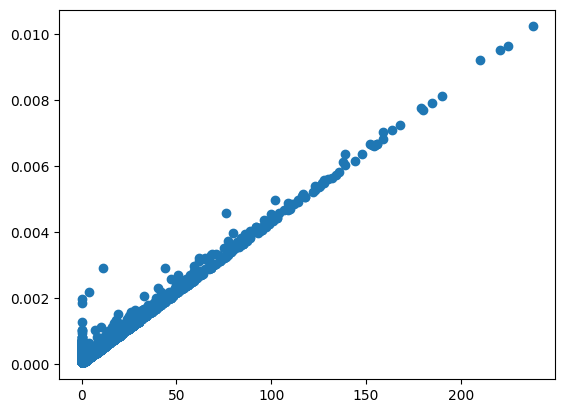

In [ ]:
# Traza un histograma de la distribución de la centralidad de grado del grafo.
plt.figure()
plt.hist(list(deg_cent.values()))
plt.show()


# Traza un gráfico de dispersión de la distribución de centralidad y la distribución de grados
plt.figure()
plt.scatter(degrees, list(deg_cent.values()))
plt.show()


Dadas las similitudes de sus histogramas, no debería sorprenderle ver una correlación perfecta entre la distribución de centralidad y la distribución de grados.

## Algoritmos de Grafos

### Encontrar Caminos
- La búsqueda de caminos es importante para:
  - Optimización:
    - encontrar el camino de transporte más corto entre dos nodos
    - caminos de transporte más cortos
  - Modelado:
    - la propagación de cosas
    - propagación de enfermedades
    - propagación de información en una red social
- ¿Cómo descubrimos si hay un camino entre dos nodos?
- Si hay un camino, ¿cómo descubrimos cuál es el camino más corto?
- Algoritmo: Búsqueda en amplitud (Breadth-first search)
- Desarrollado en la década de 1950 como una forma de encontrar el camino más corto en un laberinto.
- Dado el siguiente grafo compuesto por 11 nodos, queremos encontrar el camino más corto entre el nodo amarillo y el nodo rojo.
- Si comenzamos en el nodo amarillo, primero pedimos los vecinos del nodo amarillo.
- Luego preguntamos si el nodo de destino está presente en el conjunto de vecinos del nodo amarillo.
- Si no es así, seguimos adelante.
- Al salir a un segundo grado de separación, pedimos los vecinos de nuestros vecinos.
- El nodo de destino todavía no está presente, así que seguimos.
- En nuestro tercer grado de separación, vemos que el nodo de destino está presente.
- En este punto, podemos detenernos e ignorar el siguiente grado de separación.
- Nota: había otro camino posible, pero era más largo.
- Así, con el algoritmo de búsqueda en amplitud, hemos alcanzado nuestro objetivo de encontrar el _camino más corto_ entre el par de nodos.
- ![bfs][1]
- Si hacemos `G.neighbors(1)`, obtenemos una lista que contiene los nodos que son vecinos del nodo `1`.
- Vamos a un grado de separación, al primer nodo en la lista de los vecinos del nodo `1`, que es el nodo `10`.
- Verifiquemos los vecinos del nodo `10`: notemos que tenemos `1`, que es correcto, luego `19`, y luego varios otros nodos.
- Dado que `19`, nuestro nodo de destino, está presente en los vecinos del nodo `10`, podemos detenernos allí.
- Si `19` no estuviera, continuaríamos verificando los vecinos del nodo `5`, que es el siguiente nodo en la lista de vecinos del nodo `1`.

```python
G
>>> <networkx.classes.graph.Graph at 0x10cc08828>

len(G.edges())
>>> 57

len(G.nodes())
>>> 20

list(G.neighbors(1))
>>> [10, 5, 14, 7]

list(G.neighbors(10))
>>> [1, 19, 5, 17, 8, 9, 13, 14]
```

- Esto fue una verificación manual, pero en los ejercicios, implementarás una versión automática del algoritmo de búsqueda en amplitud.

  [1]: https://raw.githubusercontent.com/trenton3983/DataCamp/master/Images/2020-05-21_intro_to_network_analysis_in_python/bfs.JPG

### Camino más corto I

Puedes aprovechar lo que sabes sobre encontrar vecinos para intentar encontrar caminos en una red. Un algoritmo para encontrar caminos entre dos nodos es el algoritmo de "búsqueda en amplitud" (BFS, por sus siglas en inglés). En un algoritmo BFS, comienzas desde un nodo particular e iterativamente buscas entre sus vecinos y los vecinos de esos vecinos hasta que encuentras el nodo de destino.

Los algoritmos de búsqueda de caminos son importantes porque proporcionan otra manera de evaluar la importancia de un nodo; lo verás en un ejercicio posterior.

En este conjunto de 3 ejercicios, irás avanzando poco a poco hasta llegar al algoritmo BFS final. El problema se ha dividido en 3 partes que, si las completas en sucesión, te llevarán a una implementación inicial del algoritmo BFS.

**Instrucciones**

- Crea una función llamada `path_exists()` que tenga 3 parámetros: `G`, `node1` y `node2`, y que devuelva si existe o no un camino entre los dos nodos.
- Inicializa la cola de nodos a visitar con el primer nodo, `node1`. `queue` debe ser una lista.
- Itera sobre los nodos en `queue`.
- Obtén los vecinos del nodo usando el método `.neighbors()` del grafo `G`.
- Verifica si el nodo de destino `node2` está en el conjunto de `neighbors`. Si es así, devuelve `True`.

In [ ]:

# Define path_exists()
def path_exists(G, node1, node2):
    """
    Esta función verifica si existe un camino entre dos nodos (node1, node2) en el grafo G.
    """
    visited_nodes = set()

    # Inicializa la cola de nodos a visitar con el primer nodo: queue
    queue = [node1]

    # Itera sobre los nodos en la cola
    for node in queue:

        # Obtén los vecinos del nodo
        neighbors = G.neighbors(node)

        # Verifica si el nodo de destino está en el conjunto de vecinos
        if node2 in neighbors:
            print('Existe un camino entre los nodos {0} y {1}'.format(node1, node2))
            return True
            break

### Camino más corto II

Ahora que tienes el código para verificar si el nodo de destino está presente en los vecinos, el siguiente paso es extender la misma función para escribir el código para el caso en el que el nodo de destino no esté presente en los vecinos.

Todo el código que necesitas escribir está en la condición `else`; es decir, si `node2` no está en `neighbors`.

**Instrucciones**

- Usando el método `.add()`, agrega el nodo actual `node` al conjunto `visited_nodes` para llevar un registro de qué nodos ya han sido visitados.
- Agrega los _vecinos_ del nodo actual `node` que aún no han sido visitados a `queue`. Para hacer esto, necesitarás usar el método `.extend()` de `queue` junto con una comprensión de listas. El método `.extend()` agrega todos los elementos de una lista dada.
  - La _expresión de salida_ y la _variable iteradora_ de la comprensión de listas son ambas `n`. El iterable es la lista `neighbors`, y la condición es si `n` no está en los nodos visitados.

In [ ]:

def path_exists(G, node1, node2):
    """
    Esta función verifica si existe un camino entre dos nodos (node1, node2) en el grafo G.
    """
    visited_nodes = set()
    queue = [node1]

    for node in queue:
        neighbors = G.neighbors(node)
        if node2 in neighbors:
            print('El camino existe entre los nodos {0} y {1}'.format(node1, node2))
            return True

        else:
            # Agregar el nodo actual a los nodos visitados
            visited_nodes.add(node)

            # Agregar los vecinos del nodo actual que no han sido visitados


### Camino más corto III

¡Este es el último ejercicio de este trío! Ahora vas a completar el problema escribiendo el código que devuelva `False` si no hay un camino entre dos nodos.

**Instrucciones**

- Verifica si la cola está vacía. Puedes hacer esto inspeccionando el último elemento de la cola con `[-1]`.
- Coloca la declaración de retorno apropiada para indicar si existe o no un camino entre estos dos nodos.

In [ ]:
def path_exists(G, node1, node2):
    """
    Esta función verifica si existe un camino entre dos nodos (node1, node2) en el grafo G.
    """
    nodos_visitados = set()
    cola = [node1]

    for nodo in cola:
        vecinos = G.neighbors(nodo)
        if node2 in vecinos:
            print('El camino existe entre los nodos {0} y {1}'.format(node1, node2))
            return True
            break

        else:
            nodos_visitados.add(nodo)
            cola.extend([n for n in vecinos if n not in nodos_visitados])

        # Verificar si se ha alcanzado el último elemento de la cola
        if nodo == cola[-1]:
            print('El camino no existe entre los nodos {0} y {1}'.format(node1, node2))

            # Coloca la declaración de retorno apropiada
            return False


In [ ]:
import networkx as nx

# Definir el grafo G
G = nx.Graph()

# Añadir nodos y aristas al grafo
G.add_edges_from([(1, 2), (2, 3), (3, 4), (1, 4), (4, 5)])

# Definir los nodos entre los cuales quieres verificar el camino
node1 = 1
node2 = 5

# Definir la función path_exists
def path_exists(G, node1, node2):
    """
    Esta función verifica si existe un camino entre dos nodos (node1, node2) en el grafo G.
    """
    nodos_visitados = set()
    cola = [node1]

    while cola:
        nodo = cola.pop(0)
        vecinos = G.neighbors(nodo)

        if node2 in vecinos:
            print('El camino existe entre los nodos {0} y {1}'.format(node1, node2))
            return True

        else:
            nodos_visitados.add(nodo)
            cola.extend([n for n in vecinos if n not in nodos_visitados])

        # Verificar si se ha alcanzado el último elemento de la cola
        if not cola:
            print('El camino no existe entre los nodos {0} y {1}'.format(node1, node2))
            return False

# Llamar a la función y capturar el resultado
resultado = path_exists(G, node1, node2)

# Imprimir el resultado final
if resultado is not None:
    print(resultado)


El camino no existe entre los nodos 1 y 5
False


# Centralidad de Intermediación

- Volvamos a revisar nuestra noción de lo que significa ser un _nodo importante_, pero aprovechando lo que sabemos sobre los caminos.
- Ahora vamos a aprender sobre la centralidad de intermediación, pero antes de hablar sobre eso, necesitamos ampliar nuestro conocimiento con un concepto clave: todos los caminos más cortos.

## Todos los Caminos Más Cortos
- En la sección anterior, aprendimos cómo encontrar el camino más corto entre cualquier par de nodos, utilizando el algoritmo de búsqueda en amplitud (BFS).
- Ahora imagina que usamos BFS para encontrar todos los caminos más cortos entre cada par de nodos.
- Lo que obtendríamos sería el **conjunto de _todos los caminos más cortos_** en un grafo.
- En otras palabras, _todos los caminos más cortos_ son el conjunto de caminos en un grafo, tales que **cada camino es el camino más corto entre un par dado de nodos**, hecho **para todos los pares de nodos**.

## Centralidad de Intermediación
- Definición: $\frac{\text{número de caminos más cortos que pasan por el nodo}}{\text{todos los caminos más cortos posibles}}$
  - El número de caminos más cortos en un grafo que pasan por un nodo, dividido por el número de caminos más cortos que existen entre cada par de nodos en un grafo.
  - Esta métrica captura una visión diferente de la importancia: esencialmente, captura los nodos de cuello de botella en un grafo, en lugar de los nodos altamente conectados; esto se aclarará a medida que avancemos.
- ¿Dónde puede ser útil la centralidad de intermediación?
- Aplicación:
  - Un ejemplo serían los individuos que conectan dos comunidades.
    - Un individuo que conecta usuarios de Twitter con inclinaciones liberales y conservadoras.
  - De manera alternativa, considera Internet, donde existen enlaces cruciales que conectan dos redes de computadoras.
  - Si elimináramos esos nodos cruciales en Internet, la información no fluiría (o al menos no tan fácilmente) entre las subredes.

## Ejemplos
- Singapur: Raffles & Jurong East
  - Veamos el sistema de metro de Singapur para hacerlo más concreto.
  - Observemos dos conjuntos de estaciones que han sido rodeadas en color morado.
  - En el sur, hay un conjunto de estaciones en el distrito central de negocios que sirven como conectores entre diferentes líneas, pero también hay otra estación llamada Jurong East, que solo está conectada a tres otras estaciones, pero sirve como un punto de conexión principal entre las líneas roja y verde.
  - ![singapore_map][1]
- Alta centralidad de intermediación, baja centralidad de grado.
- Tenemos un grafo `G` que es un grafo tipo barra, que se puede crear como en las siguientes celdas de código.
- `m1` es el número de nodos en los extremos de la barra, y `m2` es el número de nodos en el puente de la barra.
- Las `keys` son los nodos, y los `values` son las puntuaciones de `centralidad de intermediación`.
- Algunos valores son `0` porque están ubicados en los extremos del grafo de barra, y los nodos dentro de cada extremo están completamente conectados entre sí.
- Con la excepción del nodo puente y los dos nodos a los que está conectado, no hay ningún camino más corto que tenga que pasar por esos nodos para llegar a otros nodos.

  [1]: https://raw.githubusercontent.com/trenton3983/DataCamp/master/Images/2020-05-21_intro_to_network_analysis_in_python/singapore_station_map.jpg

In [ ]:
# Crea un grafo tipo barra con 5 nodos en los extremos (m1=5) y 1 nodo en el puente (m2=1)
G = nx.barbell_graph(m1=5, m2=1)

# Calcula la centralidad de intermediación de cada nodo en el grafo G
# La centralidad de intermediación mide cuántos caminos más cortos pasan por un nodo en relación con todos los posibles caminos más cortos en el grafo
nx.betweenness_centrality(G)


{0: 0.0,
 1: 0.0,
 2: 0.0,
 3: 0.0,
 4: 0.5333333333333333,
 6: 0.5333333333333333,
 7: 0.0,
 8: 0.0,
 9: 0.0,
 10: 0.0,
 5: 0.5555555555555556}

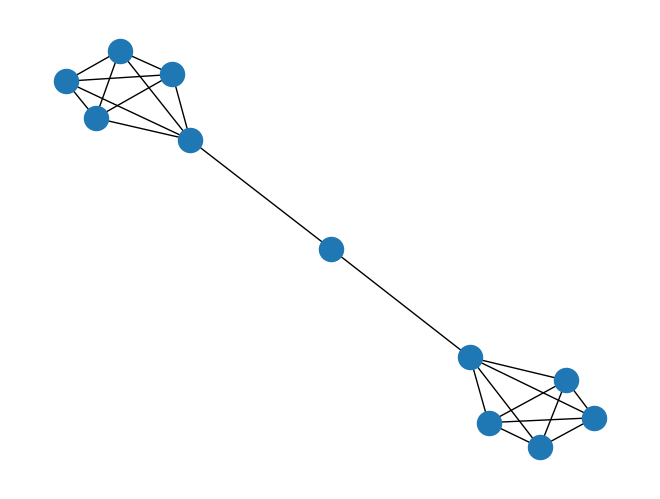

In [ ]:
# Dibuja el grafo G usando la función draw de NetworkX
nx.draw(G)

# Muestra la visualización del grafo usando Matplotlib
plt.show()


# Centralidad de intermediación de NetworkX en una red social

La centralidad de intermediación es una métrica de importancia de nodos que utiliza información sobre los caminos más cortos en una red. Se define como la fracción de todos los posibles caminos más cortos entre cualquier par de nodos que pasan por el nodo.

NetworkX proporciona la función `nx.betweenness_centrality(G)` para calcular la centralidad de intermediación de cada nodo en un grafo, y devuelve un diccionario donde las claves son los nodos y los valores son sus medidas de centralidad de intermediación.

**Instrucciones**

- Calcula la centralidad de intermediación `bet_cen` de los nodos en el grafo `T`.
- Calcula la centralidad de grado `deg_cen` de los nodos en el grafo `T`.
- Compara la centralidad de intermediación con la centralidad de grado creando un gráfico de dispersión de ambos, con `list(bet_cen.values())` en el eje x y `list(deg_cen.values())` en el eje y.

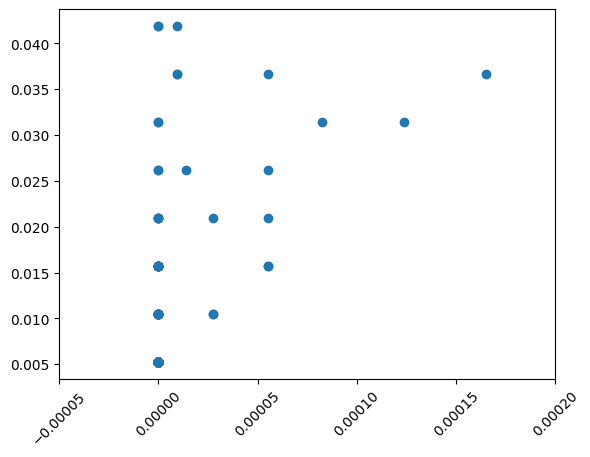

In [ ]:
# Calcular la centralidad de intermediación de T: bet_cen
bet_cen = nx.betweenness_centrality(t_131)

# Calcular la centralidad de grado de T: deg_cen
deg_cen = nx.degree_centrality(t_131)

# Crear un gráfico de dispersión de la centralidad de intermediación y la centralidad de grado
plt.scatter(list(bet_cen.values()), list(deg_cen.values()))

# Mostrar el gráfico
plt.xlim(-0.00005, 0.0002)
plt.xticks(rotation=45)
plt.show()


# Profundización - Red de Twitter

Ahora vas a realizar un análisis detallado de una red de Twitter, lo cual te ayudará a reforzar lo que has aprendido anteriormente. Primero, vas a encontrar los nodos que pueden transmitir mensajes de manera muy eficiente a muchas personas que están a un grado de separación.

NetworkX ya ha sido preimportado para ti como `nx`.

**Instrucciones**

- Escribe una función `find_nodes_with_highest_deg_cent(G)` que devuelva el nodo o los nodos con la mayor centralidad de grado utilizando los siguientes pasos:
  - Calcula la centralidad de grado de `G`.
  - Calcula la centralidad de grado máxima usando la función `max()` en `list(deg_cent.values())`.
  - Itera sobre el diccionario de centralidad de grado, `deg_cent.items()`.
  - Si el valor de centralidad de grado `v` del nodo actual `k` es igual a `max_dc`, añádelo al conjunto de nodos.
- Usa tu función para encontrar el nodo o los nodos con la mayor centralidad de grado en `T`.
- Escribe una instrucción de aserción que verifique que el nodo o los nodos se identificaron correctamente. Esto ya se ha hecho por ti, ¡así que haz clic en 'Enviar respuesta' para ver el resultado!

In [ ]:
# Define la función find_nodes_with_highest_deg_cent()
def find_nodes_with_highest_deg_cent(G):

    # Calcula la centralidad de grado de G: deg_cent
    deg_cent = nx.degree_centrality(G)

    # Calcula la centralidad de grado máxima: max_dc
    max_dc = max(list(deg_cent.values()))

    nodos = set()

    # Itera sobre el diccionario de centralidad de grado
    for k, v in deg_cent.items():

        # Verifica si el valor actual tiene la centralidad de grado máxima
        if v == max_dc:

            # Añade el nodo actual al conjunto de nodos
            nodos.add(k)

    return nodos

# Encuentra el nodo o los nodos con la mayor centralidad de grado en T: top_dc
top_dc = find_nodes_with_highest_deg_cent(T)
print(f'Parece que el nodo {top_dc} tiene la mayor centralidad de grado')

# Escribe la instrucción de aserción
for node in top_dc:
    assert nx.degree_centrality(T)[node] == max(nx.degree_centrality(T).values())


Parece que el nodo {11824} tiene la mayor centralidad de grado


# Profundización - Red de Twitter Parte II

A continuación, vas a realizar una profundización análoga sobre la centralidad de intermediación. Algunos consejos para ayudarte: recuerda que la centralidad de intermediación se calcula utilizando `nx.betweenness_centrality(G)`.

**Instrucciones**

- Escribe una función `find_node_with_highest_bet_cent(G)` que devuelva el nodo o los nodos con la mayor centralidad de intermediación.
  - Calcula la centralidad de intermediación de `G`.
  - Calcula la máxima centralidad de intermediación utilizando la función `max()` sobre `list(bet_cent.values())`.
  - Itera sobre el diccionario de centralidad de intermediación, `bet_cent.items()`.
  - Si el valor de centralidad de intermediación `v` del nodo actual `k` es igual a `max_bc`, añádelo al conjunto de nodos.
- Usa tu función para encontrar el nodo o los nodos con la mayor centralidad de intermediación en `T`.
- Escribe una instrucción de aserción para verificar que has encontrado el nodo correcto. ¡Esto ya se ha hecho por ti, así que haz clic en 'Enviar Respuesta' para ver el resultado!

In [ ]:

# Define la función find_node_with_highest_bet_cent()
def find_node_with_highest_bet_cent(G):

    # Calcula la centralidad de intermediación: bet_cent
    bet_cent = nx.betweenness_centrality(G)

    # Calcula la máxima centralidad de intermediación: max_bc
    max_bc = max(list(bet_cent.values()))

    nodes = set()

    # Itera sobre el diccionario de centralidad de intermediación
    for k, v in bet_cent.items():

        # Verifica si el valor actual tiene la máxima centralidad de intermediación
        if v == max_bc:

            # Agrega el nodo actual al conjunto de nodos
            nodes.add(k)

    return nodes

# Usa la función para encontrar el nodo o los nodos con la mayor centralidad de intermediación en la red: top_bc
top_bc = find_node_with_highest_bet_cent(t_131)
print(f'El nodo {top_bc} tiene la mayor centralidad de intermediación.')

# Escribe una instrucción de aserción que verifique que el nodo o los nodos se identificaron correctamente.
for node in top_bc:
    assert nx.betweenness_centrality(t_131)[node] == max(nx.betweenness_centrality(t_131).values())


El nodo {3265} tiene la mayor centralidad de intermediación.


# Estructuras

Este capítulo trata sobre cómo encontrar estructuras interesantes dentro de los datos de redes. Aprenderás conceptos esenciales como cliques, comunidades y subgrafos, los cuales aprovecharán todas las habilidades que adquiriste en el Capítulo 2. Al final de este capítulo, estarás listo para aplicar los conceptos que has aprendido a un estudio de caso del mundo real.

# Comunidades y Cliques

- Ahora vamos a explorar los conceptos de estructuras y subgrafos, utilizando NetworkX.
- Mucho de esto va a aprovechar lo que aprendiste en el segundo capítulo, particularmente sobre la búsqueda de caminos y el uso de vecinos.
- ¿Alguna vez has estado en un clique?
- ¿Cómo caracterizarías ese clique?
- Probablemente estaba compuesto por personas que conocen a todos los demás en el grupo de una manera bastante fuerte, ¿verdad?
- Ahora imagina que llega una nueva persona, no originalmente parte del clique, pero se une al grupo. Ahora, en este grupo, ya no se sentiría como un _clique_, porque la nueva persona no conoce realmente a todos los demás, y viceversa.
- ![cliques][1]
- En la teoría de redes, un _clique_ se define esencialmente de la versión social de un clique:
  - Un conjunto de nodos que están completamente conectados por un borde con cada otro nodo en el conjunto.
  - Es, entonces, un grafo completamente conectado.
- ¿Cuál podría ser el _clique más simple_?
  - Según la definición de un clique, un borde es el clique más simple posible.
- Ahora, ¿qué sería el _clique complejo más simple_?
  - 3 nodos completamente conectados, un triángulo.
- ¿Cuáles son algunas aplicaciones de encontrar _triángulos_ en una red?
  - Un ejemplo es un sistema de recomendación de amigos.
  - Si `A` conoce a `B` y `A` conoce a `C`, pero `B` y `C` no están conectados, entonces es probable que `B` también conozca a `C` y quiera conectarse en línea, haciendo lo que llamamos cierres de triángulos.

### Código para Cliques
- ¿Cómo escribirías un código que encuentre todos los triángulos en los que un nodo está involucrado?
- Ese será el ejercicio que vas a realizar.
- Supón que tienes un grafo `G` y quieres iterar sobre cada par de nodos, y no solo sobre cada borde.
- En lugar de escribir un bucle anidado, es posible que quieras usar la función `combinations` del módulo `itertools` de Python.
- De esta manera, tu bucle puede iterar sobre cada par de nodos en la red, utilizando el siguiente código.

[1]: https://raw.githubusercontent.com/trenton3983/DataCamp/master/Images/2020-05-21_intro_to_network_analysis_in_python/cliques.JPG

In [ ]:
t_131

In [ ]:
for n in list(combinations(t_131.nodes(), 2))[:10]:
    print(n[0], n[1])

13829 15372
13829 3086
13829 4111
13829 6163
13829 13334
13829 6168
13829 24
13829 3100
13829 4636
13829 543


# Identificación de relaciones de triángulo

Ahora que has aprendido sobre los cliques, es hora de intentar aprovechar lo que sabes para encontrar estructuras en una red. Los triángulos son lo primero que buscarás. Podríamos estar interesados en los triángulos porque son el clique complejo más simple. Vamos a escribir algunas funciones; estos ejercicios te guiarán a través de la lógica fundamental detrás de los algoritmos de redes.

En la red de Twitter, cada nodo tiene una etiqueta de `'ocupación'` asociada, en la que la ocupación laboral del usuario de Twitter se divide en `celebridad`, `político` y `científico`. Una aplicación potencial de los algoritmos para encontrar triángulos es descubrir si los usuarios con ocupaciones similares tienen más probabilidades de estar en un clique entre sí.

**Instrucciones**

- Importa `combinations` de `itertools`.
- Escribe una función `is_in_triangle()` que tenga dos parámetros: `G` y `n`, y verifique si un nodo dado está en una relación de triángulo o no.
  - `combinations(iterable, n)` devuelve combinaciones de tamaño `n` de `iterable`. Esto será útil aquí, ya que deseas combinaciones de tamaño `2` de los vecinos de `G.neighbors(n)`.
  - Para verificar si existe un borde entre dos nodos, usa el método `.has_edge(node1, node2)`. Si existe un borde, entonces el nodo dado está en una relación de triángulo, y deberías devolver `True`.

In [ ]:

# Define is_in_triangle()
def is_in_triangle(G, n):
    """
    Verifica si un nodo `n` en el grafo `G` está en una relación de triángulo o no.

    Devuelve un valor booleano.
    """
    in_triangle = False

    # Itera sobre todas las combinaciones posibles de relaciones de triángulo
    for n1, n2 in combinations(G.neighbors(n), 2):

        # Verifica si existe un borde entre n1 y n2
        if G.has_edge(n1, n2):
            in_triangle = True
            break
    return in_triangle

is_in_triangle(T, 1)


True

In [ ]:
# La función de este código itera sobre los primeros 60 nodos del grafo `T` y verifica si están involucrados en una relación de triángulo.

# Se recorre la lista de nodos del grafo `T`, limitando la iteración a los primeros 60 nodos con `sorted(list(T.nodes())[:60])`.

for node in sorted(list(T.nodes())[:60]):
    # Llama a la función `is_in_triangle()` para verificar si el nodo está en una relación de triángulo.
    x = is_in_triangle(T, node)

    # Si el nodo está en un triángulo (es decir, `x` es `True`), imprime el nodo y el valor `True`.
    if x == True:
        print(f'{node}: {x}')


1: True
16: True
18: True
19: True
28: True
36: True
39: True
43: True
45: True


## Encontrar nodos involucrados en triángulos

NetworkX proporciona una API para contar la cantidad de triángulos en los que cada nodo está involucrado: `nx.triangles(G)`. Esta función devuelve un diccionario de nodos como claves y el número de triángulos como valores. El objetivo de este ejercicio es modificar la función definida anteriormente para extraer todos los nodos involucrados en una relación de triángulo con un nodo dado.

**Instrucciones**

- Escribe una función `nodes_in_triangle()` que tenga dos parámetros: `G` y `n`, y que identifique todos los nodos involucrados en una relación de triángulo con un nodo dado.
  - En el bucle `for`, itera sobre todas las combinaciones posibles de relaciones de triángulo.
  - Verifica si los nodos `n1` y `n2` tienen un borde entre ellos. Si lo tienen, agrega ambos nodos al conjunto `triangle_nodes`.
- Usa tu función en una declaración `assert` para verificar que el número de nodos involucrados en una relación de triángulo con el nodo `1` del grafo `T` sea igual a `35`..

In [ ]:

# Escribe una función que identifica todos los nodos en una relación de triángulo con un nodo dado.
def nodes_in_triangle(G, n):
    """
    Devuelve los nodos en un grafo `G` que están involucrados en una relación de triángulo con el nodo `n`.
    """
    triangle_nodes = set([n])

    # Itera sobre todas las combinaciones posibles de relaciones de triángulo
    for n1, n2 in combinations(G.neighbors(n), 2):

        # Verifica si n1 y n2 tienen un borde entre ellos
        if G.has_edge(n1, n2):

            # Agrega n1 a triangle_nodes
            triangle_nodes.add(n1)

            # Agrega n2 a triangle_nodes
            triangle_nodes.add(n2)
    return triangle_nodes

# Escribe la declaración de aserción
assert len(nodes_in_triangle(T, 1)) == 23


# Encontrando triángulos abiertos

Ahora pasemos a encontrar triángulos abiertos. Recuerda que estos forman la base de los sistemas de recomendación de amigos; si "A" conoce a "B" y "A" conoce a "C", entonces es probable que "B" también conozca a "C".

**Instrucciones**

- Escribe una función `node_in_open_triangle()` que tenga dos parámetros: `G` y `n`, y que identifique si un nodo está presente en un triángulo abierto con sus vecinos.
  - En el ciclo `for`, itera sobre todas las combinaciones posibles de relaciones de triángulo.
  - Si los nodos `n1` y `n2` no tienen un borde entre ellos, establece `in_open_triangle` como `True`, sal de la declaración `if` y devuelve `in_open_triangle`.
- Usa esta función para contar la cantidad de triángulos abiertos que existen en `T`.
  - En el ciclo `for`, itera sobre todos los nodos de `T`.
  - Si el nodo actual `n` está en un triángulo abierto, incrementa `num_open_triangles`.

In [ ]:
# Define node_in_open_triangle()
def node_in_open_triangle(G, n):
    """
    Verifica si los pares de vecinos del nodo `n` en el grafo `G` están en una relación de 'triángulo abierto' con el nodo `n`.
    """
    in_open_triangle = False

    # Itera sobre todas las combinaciones posibles de relaciones de triángulo
    for n1, n2 in combinations(G.neighbors(n), 2):

        # Verifica si n1 y n2 NO tienen un borde entre ellos
        if not G.has_edge(n1, n2):

            in_open_triangle = True

            break

    return in_open_triangle

# Calcular el número de triángulos abiertos en T
num_open_triangles = 0

# Itera sobre todos los nodos en T
for n in T.nodes():

    # Verifica si el nodo actual está en un triángulo abierto
    if node_in_open_triangle(T, n):

        # Incrementa num_open_triangles
        num_open_triangles += 1

print(f'En el grafo T, {num_open_triangles} nodos están en triángulos abiertos.')


En el grafo T, 908 nodos están en triángulos abiertos.


## Cliques Máximas

- ![cliques_máximas][1]
- Son una clique, pero esa clique no puede ser extendida añadiendo otro nodo en el grafo.
- Por ejemplo, la sub-clique de los 3 nodos verdes puede ser extendida con un nodo azul para formar una gran clique.
- Como tal, estos 3 nodos verdes no forman una _clique máxima_ en el grafo.
- Los 4 nodos conectados como una clique juntos no pueden ser extendidos y seguir siendo una clique, ya que el nodo restante no está completamente conectado a los otros cuatro nodos.
- Como tal, estos cuatro nodos constituyen una _clique máxima_.

### Comunidades
- El concepto de _cliques máximas_ tiene aplicaciones en algoritmos de detección de comunidades.
- Sin entrar en los detalles posibles, espero definir, a un nivel básico, qué es una comunidad.
- Las cliques forman un buen punto de partida para encontrar comunidades, ya que son subgrafos completamente conectados dentro de un grafo más grande.
- Al identificar estas _cliques máximas_, una forma ingenua de identificar comunidades podría ser identificar las uniones de cliques máximas que comparten algunos miembros, pero que también tienen un tamaño mínimo.

### API de NetworkX
- NetworkX proporciona una función para encontrar todas las cliques máximas, que es la función `find_cliques`.
  - Funciona para `Graph`, pero no para `DiGraph`.
- `find_cliques` no solo encuentra cualquier clique, sino el conjunto de _cliques máximas_.
- Hay dos _cliques máximas_ de tamaño 5 en el grafo.
- También hay dos _cliques máximas_ de tamaño 2: una es el borde entre los nodos `4` y `5`, y la otra entre los nodos `5` y `6`.
- Recuerda que los bordes también son una clique.

  [1]: https://raw.githubusercontent.com/trenton3983/DataCamp/master/Images/2020-05-21_intro_to_network_analysis_in_python/max_cliques.JPG

In [ ]:
# Crear un grafo de barra de campana con 5 nodos en un grupo y 1 nodo en el otro
G = nx.barbell_graph(m1=5, m2=1)

# Encontrar todas las cliques en el grafo G
nx.find_cliques(G)


<generator object find_cliques at 0x7f48734e1930>

[[4, 0, 1, 2, 3], [4, 5], [6, 5], [6, 7, 8, 9, 10]]


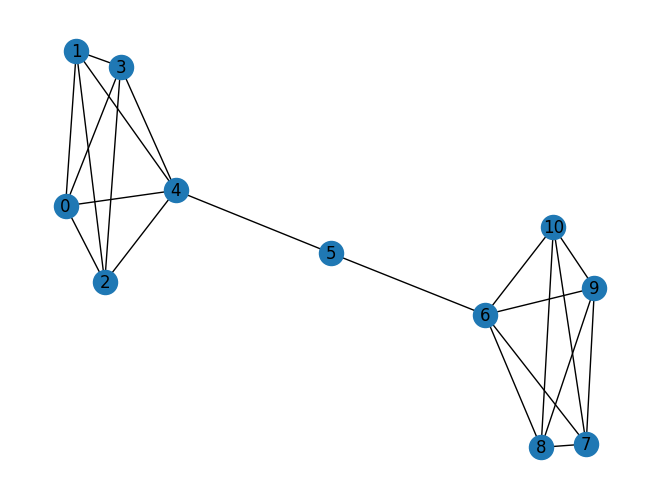

In [ ]:
# Encontrar todas las cliques en el grafo G y convertir el resultado en una lista
gl = list(nx.find_cliques(G))

# Imprimir la lista de cliques
print(gl)

# Dibujar el grafo G con etiquetas en los nodos
nx.draw(G, with_labels=True)


[[4, 0, 1, 2, 3], [4, 5], [6, 5], [6, 7], [7, 8, 9, 10, 11]]


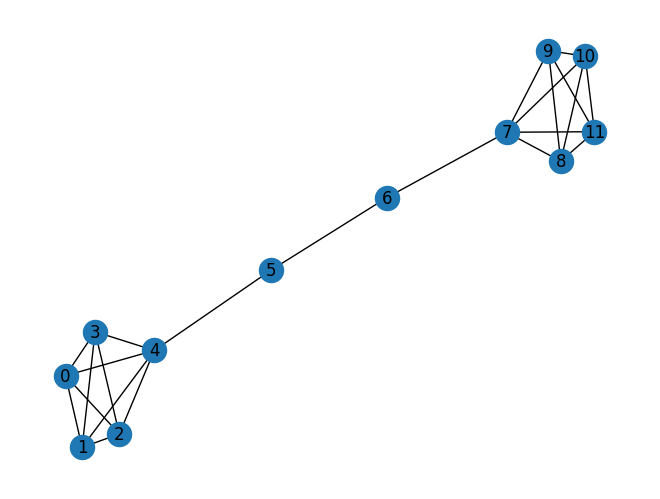

In [ ]:
# Crear un grafo de tipo "barbell" con m1=5 y m2=2
G2 = nx.barbell_graph(m1=5, m2=2)

# Encontrar todas las cliques en el grafo G2 y convertir el resultado en una lista
gl2 = list(nx.find_cliques(G2))

# Imprimir la lista de cliques en el grafo G2
print(gl2)

# Dibujar el grafo G2 con etiquetas en los nodos
nx.draw(G2, with_labels=True)


# Encontrando todas las cliques máximas de tamaño "n"

Ahora que has explorado los triángulos (y los triángulos abiertos), pasemos al concepto de las cliques máximas. Las cliques máximas son cliques que no se pueden extender añadiendo un borde adyacente, y son una propiedad útil del grafo cuando se buscan comunidades. NetworkX proporciona una función que te permite identificar los nodos involucrados en cada clique máxima de un grafo: `nx.find_cliques(G)`. Juega con la función usándola en `T` en el IPython Shell, y luego intenta responder al ejercicio.

**Instrucciones**

- Escribe una función `maximal_cliques()` que tenga dos parámetros: `G` y `size`, y que encuentre todas las cliques máximas de tamaño `n`.
 - En el ciclo `for`, itera sobre todas las cliques en `G` usando la función `nx.find_cliques()`.
 - Si la clique actual tiene un tamaño de `size`, añádela a la lista `mcs`.
- Usa una declaración `assert` y tu función `maximal_cliques()` para verificar que hay `33` cliques máximas de tamaño `3` en el grafo `T`.

In [ ]:
nodes = {1: {'category': 'I', 'occupation': 'politician'}, 3: {'category': 'D', 'occupation': 'celebrity'}, 4: {'category': 'I', 'occupation': 'politician'}, 5: {'category': 'I', 'occupation': 'scientist'}, 6: {'category': 'D', 'occupation': 'politician'}, 7: {'category': 'I', 'occupation': 'politician'}, 8: {'category': 'I', 'occupation': 'celebrity'}, 9: {'category': 'D', 'occupation': 'scientist'}, 10: {'category': 'D', 'occupation': 'celebrity'}, 11: {'category': 'I', 'occupation': 'celebrity'}, 12: {'category': 'I', 'occupation': 'celebrity'}, 13: {'category': 'P', 'occupation': 'scientist'}, 14: {'category': 'D', 'occupation': 'celebrity'}, 15: {'category': 'P', 'occupation': 'scientist'}, 16: {'category': 'P', 'occupation': 'politician'}, 17: {'category': 'I', 'occupation': 'scientist'}, 18: {'category': 'I', 'occupation': 'celebrity'}, 19: {'category': 'I', 'occupation': 'scientist'}, 20: {'category': 'P', 'occupation': 'scientist'}, 21: {'category': 'I', 'occupation': 'celebrity'}, 22: {'category': 'D', 'occupation': 'scientist'}, 23: {'category': 'D', 'occupation': 'scientist'}, 24: {'category': 'P', 'occupation': 'politician'}, 25: {'category': 'I', 'occupation': 'celebrity'}, 26: {'category': 'P', 'occupation': 'celebrity'}, 27: {'category': 'D', 'occupation': 'scientist'}, 28: {'category': 'P', 'occupation': 'celebrity'}, 29: {'category': 'I', 'occupation': 'celebrity'}, 30: {'category': 'P', 'occupation': 'scientist'}, 31: {'category': 'D', 'occupation': 'scientist'}, 32: {'category': 'P', 'occupation': 'politician'}, 33: {'category': 'I', 'occupation': 'politician'}, 34: {'category': 'D', 'occupation': 'celebrity'}, 35: {'category': 'P', 'occupation': 'scientist'}, 36: {'category': 'D', 'occupation': 'scientist'}, 37: {'category': 'I', 'occupation': 'scientist'}, 38: {'category': 'P', 'occupation': 'celebrity'}, 39: {'category': 'D', 'occupation': 'celebrity'}, 40: {'category': 'I', 'occupation': 'celebrity'}, 41: {'category': 'I', 'occupation': 'celebrity'}, 42: {'category': 'P', 'occupation': 'scientist'}, 43: {'category': 'I', 'occupation': 'celebrity'}, 44: {'category': 'I', 'occupation': 'politician'}, 45: {'category': 'D', 'occupation': 'scientist'}, 46: {'category': 'I', 'occupation': 'politician'}, 47: {'category': 'I', 'occupation': 'celebrity'}, 48: {'category': 'P', 'occupation': 'celebrity'}, 49: {'category': 'P', 'occupation': 'politician'}}
edges = [(1, 3, {'date': date(2012, 11, 16)}), (1, 4, {'date': date(2013, 6, 7)}), (1, 5, {'date': date(2009, 7, 27)}), (1, 6, {'date': date(2014, 12, 18)}), (1, 7, {'date': date(2010, 10, 18)}), (1, 8, {'date': date(2012, 4, 18)}), (1, 9, {'date': date(2007, 10, 14)}), (1, 10, {'date': date(2012, 9, 8)}), (1, 11, {'date': date(2010, 1, 6)}), (1, 12, {'date': date(2012, 12, 27)}), (1, 13, {'date': date(2008, 12, 18)}), (1, 14, {'date': date(2014, 5, 25)}), (1, 15, {'date': date(2009, 11, 12)}), (1, 16, {'date': date(2008, 8, 6)}), (1, 17, {'date': date(2007, 8, 11)}), (1, 18, {'date': date(2009, 10, 7)}), (1, 19, {'date': date(2008, 7, 24)}), (1, 20, {'date': date(2013, 11, 18)}), (1, 21, {'date': date(2011, 3, 28)}), (1, 22, {'date': date(2013, 3, 4)}), (1, 23, {'date': date(2012, 4, 20)}), (1, 24, {'date': date(2009, 6, 6)}), (1, 25, {'date': date(2013, 6, 18)}), (1, 26, {'date': date(2014, 11, 20)}), (1, 27, {'date': date(2007, 4, 28)}), (1, 28, {'date': date(2014, 3, 28)}), (1, 29, {'date': date(2014, 1, 23)}), (1, 30, {'date': date(2007, 10, 9)}), (1, 31, {'date': date(2009, 2, 17)}), (1, 32, {'date': date(2009, 10, 14)}), (1, 33, {'date': date(2010, 5, 19)}), (1, 34, {'date': date(2009, 12, 21)}), (1, 35, {'date': date(2014, 11, 16)}), (1, 36, {'date': date(2010, 2, 25)}), (1, 37, {'date': date(2010, 9, 23)}), (1, 38, {'date': date(2007, 4, 28)}), (1, 39, {'date': date(2007, 4, 8)}), (1, 40, {'date': date(2010, 5, 15)}), (1, 41, {'date': date(2009, 8, 12)}), (1, 42, {'date': date(2013, 3, 9)}), (1, 43, {'date': date(2011, 11, 14)}), (1, 44, {'date': date(2013, 4, 6)}), (1, 45, {'date': date(2010, 1, 18)}), (1, 46, {'date': date(2011, 8, 20)}), (1, 47, {'date': date(2014, 8, 3)}), (1, 48, {'date': date(2010, 3, 15)}), (1, 49, {'date': date(2007, 9, 2)}), (5, 19, {'date': date(2013, 6, 12)}), (5, 28, {'date': date(2010, 12, 4)}), (5, 36, {'date': date(2013, 4, 7)}), (7, 28, {'date': date(2011, 11, 21)}), (8, 19, {'date': date(2010, 11, 5)}), (8, 28, {'date': date(2007, 6, 26)}), (11, 19, {'date': date(2012, 4, 16)}), (11, 28, {'date': date(2011, 6, 21)}), (13, 19, {'date': date(2012, 12, 13)}), (14, 28, {'date': date(2013, 12, 18)}), (15, 19, {'date': date(2008, 12, 13)}), (15, 28, {'date': date(2014, 6, 3)}), (16, 18, {'date': date(2008, 8, 5)}), (16, 35, {'date': date(2014, 6, 4)}), (16, 36, {'date': date(2008, 10, 10)}), (16, 48, {'date': date(2014, 1, 27)}), (17, 19, {'date': date(2007, 11, 11)}), (17, 28, {'date': date(2012, 10, 11)}), (18, 24, {'date': date(2009, 2, 4)}), (18, 35, {'date': date(2008, 12, 1)}), (18, 36, {'date': date(2013, 2, 6)}), (19, 20, {'date': date(2008, 11, 9)}), (19, 21, {'date': date(2007, 7, 23)}), (19, 24, {'date': date(2013, 12, 13)}), (19, 30, {'date': date(2012, 6, 6)}), (19, 31, {'date': date(2011, 1, 27)}), (19, 35, {'date': date(2014, 3, 3)}), (19, 36, {'date': date(2007, 10, 22)}), (19, 37, {'date': date(2008, 4, 20)}), (19, 48, {'date': date(2010, 12, 23)}), (20, 28, {'date': date(2012, 4, 15)}), (21, 28, {'date': date(2014, 4, 27)}), (24, 28, {'date': date(2013, 1, 27)}), (24, 36, {'date': date(2009, 4, 23)}), (24, 37, {'date': date(2008, 6, 27)}), (24, 39, {'date': date(2007, 1, 27)}), (24, 43, {'date': date(2014, 2, 12)}), (25, 28, {'date': date(2014, 5, 9)}), (27, 28, {'date': date(2007, 8, 9)}), (28, 29, {'date': date(2012, 4, 3)}), (28, 30, {'date': date(2007, 12, 2)}), (28, 31, {'date': date(2008, 6, 1)}), (28, 35, {'date': date(2012, 11, 16)}), (28, 36, {'date': date(2012, 9, 26)}), (28, 37, {'date': date(2014, 11, 12)}), (28, 44, {'date': date(2007, 11, 18)}), (28, 48, {'date': date(2008, 5, 25)}), (28, 49, {'date': date(2011, 12, 19)}), (29, 43, {'date': date(2014, 6, 4)}), (33, 39, {'date': date(2011, 9, 5)}), (35, 36, {'date': date(2008, 12, 1)}), (35, 37, {'date': date(2014, 5, 7)}), (35, 39, {'date': date(2007, 6, 17)}), (35, 43, {'date': date(2009, 6, 10)}), (36, 37, {'date': date(2014, 5, 13)}), (36, 39, {'date': date(2014, 12, 6)}), (36, 43, {'date': date(2013, 12, 17)}), (37, 43, {'date': date(2012, 1, 22)}), (38, 39, {'date': date(2009, 5, 15)}), (39, 40, {'date': date(2011, 6, 3)}), (39, 41, {'date': date(2009, 10, 5)}), (39, 45, {'date': date(2011, 1, 12)}), (41, 45, {'date': date(2009, 9, 7)}), (43, 47, {'date': date(2014, 12, 21)}), (43, 48, {'date': date(2013, 1, 28)})]

# Crear un objeto de grafo vacío
t_321 = nx.Graph()

# Agregar nodos al grafo
t_321.add_nodes_from(nodes)

# Agregar aristas (conexiones) entre los nodos
t_321.add_edges_from(edges)

# Establecer atributos en los nodos del grafo
nx.set_node_attributes(t_321, nodes)


In [ ]:
# Define maximal_cliques()
def maximal_cliques(G, n):
    """
    Encuentra todos los cliques máximos en el grafo `G` que tienen un tamaño de `n`.
    """
    mcs = []  # Se crea una lista vacía para almacenar los cliques máximos de tamaño n
    for clique in nx.find_cliques(G):  # nx.find_cliques(G) encuentra todos los cliques en el grafo G
        if len(clique) == n:  # Se verifica si el tamaño del clique es igual a `n`
            mcs.append(clique)  # Si es así, se agrega a la lista de cliques máximos
    return mcs  # Devuelve la lista de cliques máximos encontrados

# Verifica que haya 33 cliques máximos de tamaño 3 en el grafo t_321
assert len(maximal_cliques(t_321, 3)) == 33


## Subgrafos

- Cuando tienes un grafo grande y deseas visualizar solo una pequeña porción de él, puede ser útil extraer esos nodos y sus aristas asociadas como un objeto de grafo separado.
- Por ejemplo, podrías querer visualizar un camino particular a través de la red, o quizás quieras visualizar una comunidad o clico en particular.
- Alternativamente, tal vez solo quieras explorar la estructura del grafo alrededor de un nodo a partir de un número determinado de grados de separación.
- En todos estos escenarios, es útil poder "extraer" los nodos y aristas de interés y visualizarlos.

In [ ]:
# Se establece la semilla para la generación de números aleatorios
random.seed(121)

# Se crea un grafo aleatorio de tipo Erdos-Renyi con 20 nodos y probabilidad de conexión entre nodos de 0.2
G = nx.erdos_renyi_graph(n=20, p=0.2)

# Se obtienen los nodos del grafo G
G.nodes()


NodeView((0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19))

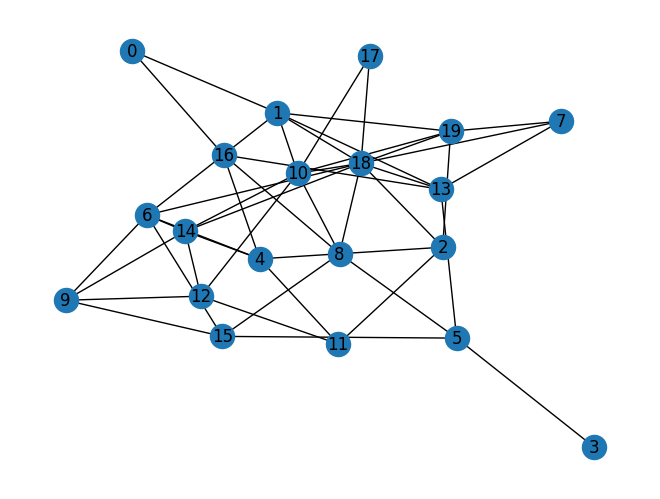

In [ ]:
# Dibuja el grafo G con etiquetas en los nodos
nx.draw(G, with_labels=True)


In [ ]:
# Obtiene los vecinos del nodo 8 y los almacena en una lista
nodes = list(G.neighbors(8))
nodes


[5, 10, 15, 16, 18]

In [ ]:
# Añade el nodo 8 a la lista de nodos
nodes.append(8)

# Crea un subgrafo con los nodos especificados (incluyendo el nodo 8)
G_eight = G.subgraph(nodes)

# Muestra las aristas del subgrafo
G_eight.edges()


EdgeView([(5, 8), (5, 15), (8, 10), (8, 15), (8, 16), (8, 18), (10, 18)])

In [ ]:
# Muestra el subgrafo G_eight
display(G_eight)

# Muestra el grafo completo G
display(G)


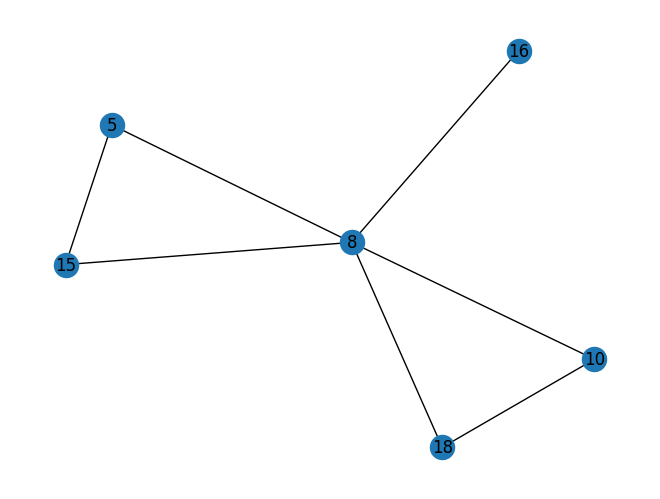

In [ ]:
# Dibuja el subgrafo G_eight con etiquetas en los nodos
nx.draw(G_eight, with_labels=True)


# Subgrafos I

Puede haber ocasiones en las que solo desees analizar un subconjunto de nodos en una red. Para hacerlo, puedes copiarlos a otro objeto de grafo utilizando `G.subgraph(nodes)`, lo cual devuelve un nuevo objeto `graph` (del mismo tipo que el grafo original) que está compuesto por el iterable de `nodes` que se pasó como parámetro.

`matplotlib.pyplot` ha sido importado como `plt`.

**Instrucciones**

- Escribe una función `get_nodes_and_nbrs(G, nodes_of_interest)` que extraiga el subgrafo del grafo `G` compuesto por los `nodes_of_interest` y sus vecinos.
  - En el primer `for`, itera sobre `nodes_of_interest` y agrega el nodo actual `n` a `nodes_to_draw`.
  - En el segundo `for`, itera sobre los vecinos de `n`, y agrega todos los vecinos `nbr` a `nodes_to_draw`.
- Usa la función para extraer el subgrafo de `T` compuesto por los nodos 29, 38 y 42 (contenidos en la lista predefinida `nodes_of_interest`) y sus vecinos. Guarda el resultado como `T_draw`.
- Dibuja el subgrafo `T_draw` en la pantalla.

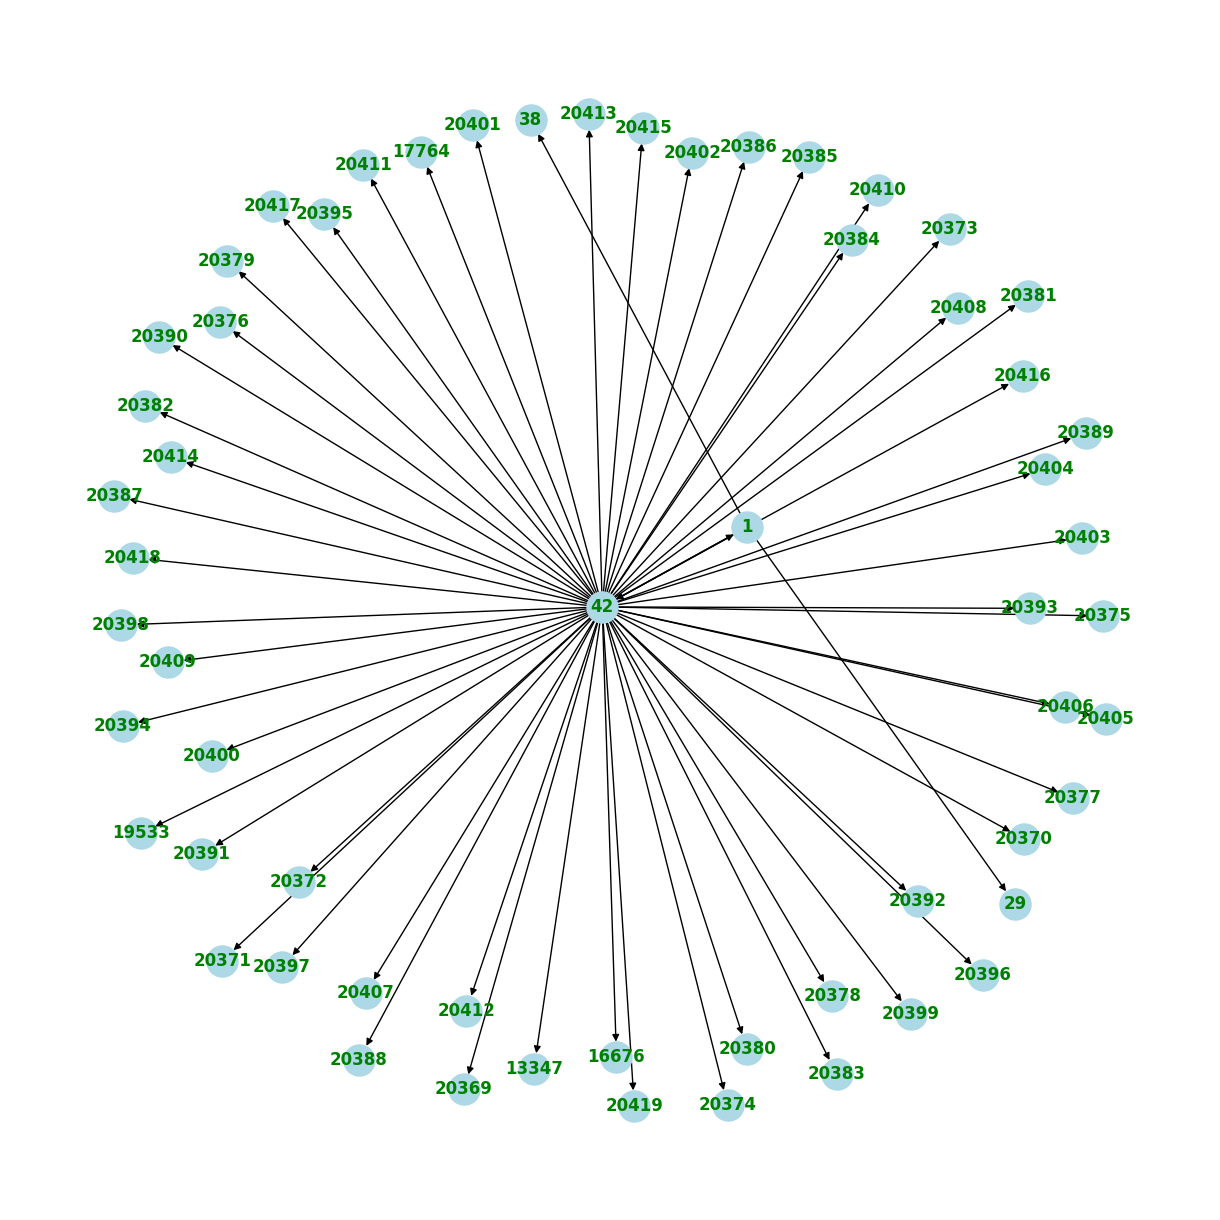

In [ ]:


# Lista de nodos de interés
nodes_of_interest = [29, 38, 42]

# Definir la función get_nodes_and_nbrs()
def get_nodes_and_nbrs(G, nodes_of_interest):
    """
    Devuelve un subgrafo del grafo `G` con solo los `nodes_of_interest` y sus vecinos.
    """
    nodes_to_draw = []

    # Iterar sobre los nodos de interés
    for n in nodes_of_interest:

        # Añadir los nodos de interés a nodes_to_draw
        nodes_to_draw.append(n)

        # Iterar sobre todos los vecinos del nodo n
        for nbr in G.neighbors(n):

            # Añadir los vecinos de n a nodes_to_draw
            nodes_to_draw.append(nbr)

    # Devolver el subgrafo con los nodos a dibujar
    return G.subgraph(nodes_to_draw)

# Extraer el subgrafo con los nodos de interés: T_draw
T_draw = get_nodes_and_nbrs(T, nodes_of_interest)

# Configurar el tamaño de la figura
plt.figure(figsize=(12, 12))

# Dibujar el subgrafo con etiquetas en color verde
nx.draw(T_draw, with_labels=True, node_color='lightblue', font_color='green', node_size=500, font_weight='bold')

# Mostrar el gráfico
plt.show()



# Subgrafos II

En el ejercicio anterior, te proporcionamos una lista de nodos cuyos vecinos te pedimos que extrajeras.

Ahora intentemos otro ejercicio en el que extraerás nodos que tienen una propiedad particular en sus metadatos y sus vecinos. Esto debería hacer referencia a lo que has aprendido sobre el uso de comprensiones de listas para encontrar nodos. El ejercicio también desarrollará tu capacidad para componer funciones que ya has escrito anteriormente.

**Instrucciones**

- Usando una comprensión de lista, extrae los nodos que tienen el metadato `'occupation'` como `'celebrity'` junto con sus vecinos:
  - La _expresión de salida_ de la comprensión de lista es `n`, y hay dos _variables de iterador_: `n` y `d`. El iterable es la lista de nodos de `T` (incluyendo los metadatos, los cuales puedes especificar utilizando `data=True`), y la expresión condicional es si la clave `'occupation'` del diccionario de metadatos `d` es igual a `'celebrity'`.
- Colócalos en un nuevo subgrafo llamado `T_sub`. Para hacerlo:
  - Itera sobre los nodos, calcula los vecinos de cada nodo y añádelos al conjunto de nodos `nodeset` utilizando el método `.union()`. Esta última parte ya está hecha por ti.
  - Usa `nodeset` junto con el método `T.subgraph()` para calcular `T_sub`.
- Dibuja `T_sub` en la pantalla.

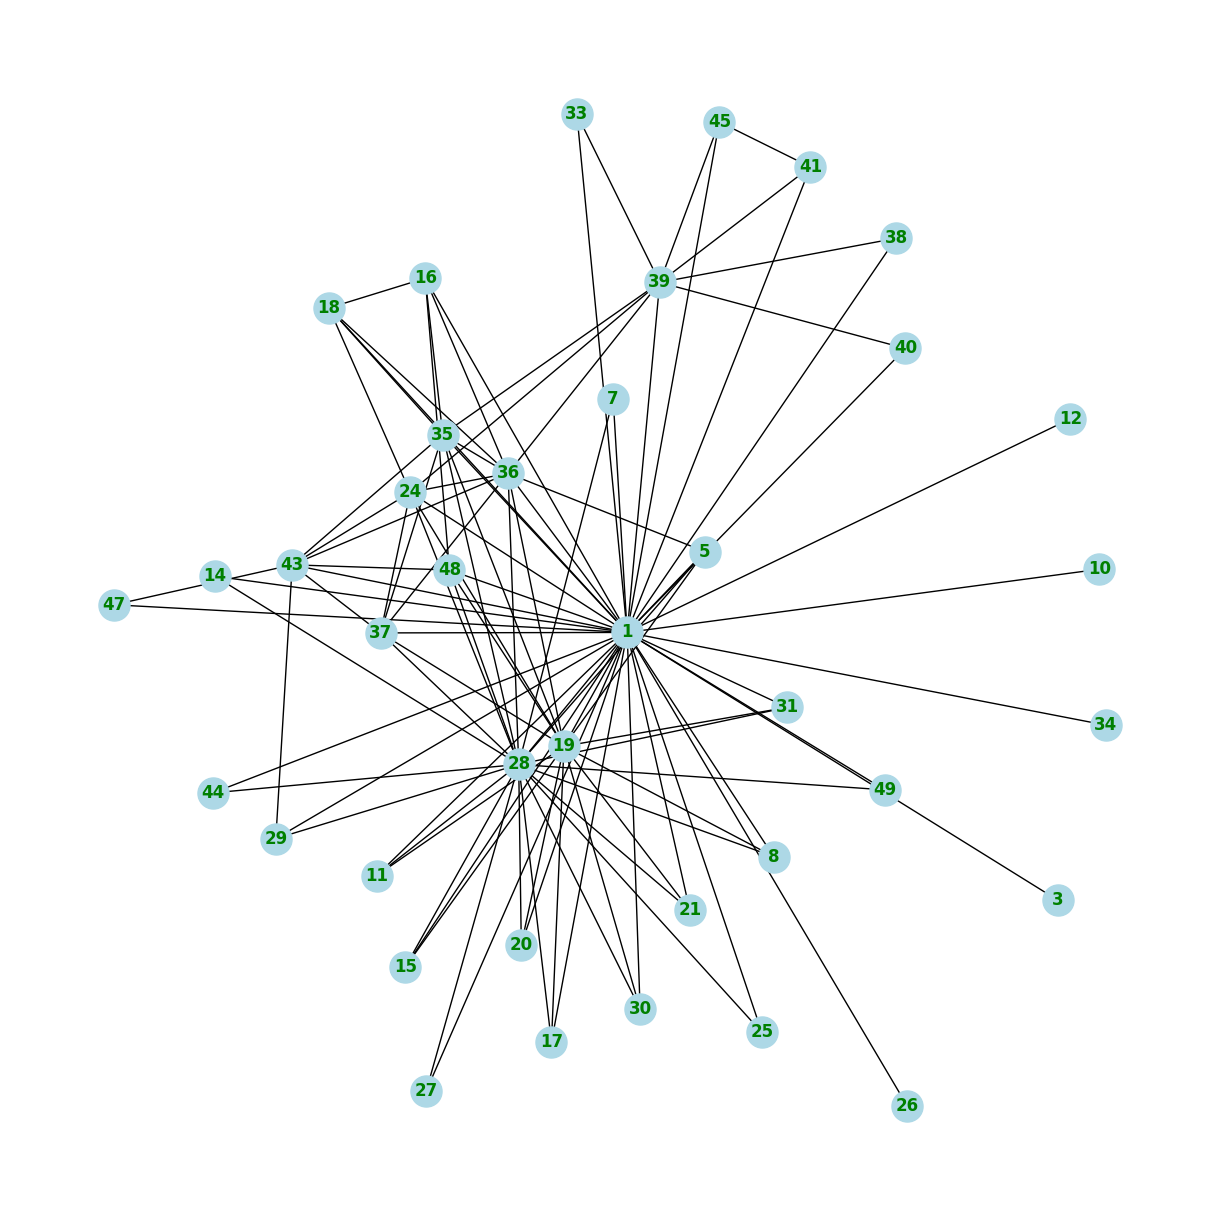

In [ ]:


# Extraer los nodos de interés: nodes
nodes = [n for n, d in t_321.nodes(data=True) if d['occupation'] == 'celebrity']

# Crear el conjunto de nodos: nodeset
nodeset = set(nodes)

# Iterar sobre los nodos
for n in nodes:

    # Calcular los vecinos de n: nbrs
    nbrs = t_321.neighbors(n)

    # Calcular la unión de nodeset y nbrs: nodeset
    nodeset = nodeset.union(nbrs)

# Calcular el subgrafo usando nodeset: T_sub
T_sub = t_321.subgraph(nodeset)

# Configurar el tamaño de la figura
plt.figure(figsize=(12, 12))

# Dibujar T_sub con etiquetas en color verde
nx.draw(T_sub, with_labels=True, node_color='lightblue', font_color='green', node_size=500, font_weight='bold')

# Mostrar el gráfico
plt.show()


# Uniendo todo

En este último capítulo del curso, consolidarás todo lo que has aprendido a través de un estudio de caso detallado de los datos de la red de colaboradores de GitHub. Este es un excelente ejemplo de datos de redes sociales del mundo real, y tus habilidades recién adquiridas serán completamente puestas a prueba. Al final de este capítulo, habrás desarrollado tu propio sistema de recomendaciones para conectar usuarios de GitHub que deberían colaborar juntos.

# Estudio de Caso

### Datos
- Este conjunto de datos es una red de colaboración de usuarios de GitHub.
- GitHub es un sitio de codificación social, donde los usuarios pueden colaborar en repositorios de código.
- En esta red, los nodos son usuarios, y los bordes indican que dos usuarios son colaboradores en al menos un repositorio de GitHub.
- Lo que lograrás al final de los ejercicios es lo siguiente:
  - Habrá analizado la estructura del grafo, incluyendo sus propiedades básicas.
  - Visualizarás el grafo utilizando `nxviz`.
  - Construirás un sistema de recomendación simple.
    - Un sistema de recomendación en redes sociales sugiere a los usuarios que "se conecten" de alguna manera.
    - En el contexto de GitHub, intentaremos escribir un recomendador que sugiera usuarios que deberían colaborar juntos.

### Propiedades del grafo
- Recuerda del primer capítulo algunas funciones básicas para obtener el tamaño de un grafo.

In [ ]:
# Establecer la semilla para obtener resultados reproducibles
random.seed(121)

# Crear un grafo de Erdős–Rényi con 20 nodos y una probabilidad de conexión de 0.2
G = nx.erdos_renyi_graph(n=20, p=0.2)

# Imprimir la cantidad de bordes en el grafo
print(len(G.edges()))  # Cuenta los bordes y los imprime

# Imprimir la cantidad de nodos en el grafo
print(len(G.nodes()))  # Cuenta los nodos y los imprime

45
20


¿Puedes recordar cuáles son los nombres de las funciones para calcular la centralidad de grado y la centralidad de intermediación de cada nodo en el grafo?
  - `nx.degree_centrality(G)`
  - `nx.betweenness_centrality(G)`
  - En ambos casos, la clave es el nombre del nodo y el valor es el puntaje de centralidad.e

In [ ]:
# Calcular la centralidad de grado para cada nodo en el grafo
pp(nx.degree_centrality(G))  # La centralidad de grado mide la importancia de un nodo basado en el número de conexiones directas que tiene

# Imprimir un salto de línea para mejorar la legibilidad
print('\n')

# Calcular la centralidad de intermediación para cada nodo en el grafo
pp(nx.betweenness_centrality(G))  # La centralidad de intermediación mide la importancia de un nodo basado en cuántas veces actúa como intermediario entre otros nodos


{0: 0.10526315789473684,
 1: 0.3157894736842105,
 2: 0.21052631578947367,
 3: 0.05263157894736842,
 4: 0.2631578947368421,
 5: 0.21052631578947367,
 6: 0.3157894736842105,
 7: 0.15789473684210525,
 8: 0.2631578947368421,
 9: 0.21052631578947367,
 10: 0.3684210526315789,
 11: 0.15789473684210525,
 12: 0.21052631578947367,
 13: 0.2631578947368421,
 14: 0.3157894736842105,
 15: 0.21052631578947367,
 16: 0.21052631578947367,
 17: 0.10526315789473684,
 18: 0.5263157894736842,
 19: 0.2631578947368421}


{0: 0.003759398496240601,
 1: 0.08607630186577553,
 2: 0.044040657198551936,
 3: 0.0,
 4: 0.07446393762183234,
 5: 0.11647173489278752,
 6: 0.08880534670008351,
 7: 0.0051239209133945975,
 8: 0.11155666945140628,
 9: 0.024477861319966585,
 10: 0.10698969646338068,
 11: 0.01189083820662768,
 12: 0.0339459760512392,
 13: 0.09337231968810916,
 14: 0.05116959064327485,
 15: 0.05334168755221386,
 16: 0.06688944583681425,
 17: 0.0,
 18: 0.22528543581175156,
 19: 0.02456140350877193}


### Characterizing the network (I)
To start out, let's do some basic characterization of the network, by looking at the number of nodes and number of edges in a network. It has been pre-loaded as `G` and is available for exploration in the IPython Shell. Your job in this exercise is to identify how many nodes and edges are present in the network. You can use the functions `len(G.nodes())` and `len(G.edges())` to calculate the number of nodes and edges respectively.

- ~~72900 nodes, 56519 edges.~~
- **56519 nodes, 72900 edges.**
- ~~47095 nodes, 65789 edges.~~
- ~~63762 nodes, 71318 edges.~~

In [ ]:
# Crear un nuevo grafo G a partir de un grafo Gh existente
G = nx.Graph(Gh)  # Se crea una copia de Gh, un grafo existente, para poder trabajar con él sin modificar el original

# Imprimir el número de nodos en el grafo G
print(len(G.nodes()))  # len(G.nodes()) devuelve la cantidad de nodos en el grafo G

# Imprimir el número de aristas en el grafo G
print(len(G.edges()))  # len(G.edges()) devuelve la cantidad de aristas (conexiones) en el grafo G


56519
72900


Aquí tienes la traducción al español del markdown solicitado:

## Caracterización de la red (II)

Continuemos recordando lo que has aprendido previamente sobre la importancia de los nodos, trazando la distribución de grados de una red. Esta es la distribución de los grados de los nodos calculada a través de todos los nodos en una red.

**Instrucciones**

- Traza la distribución de grados de la red de colaboración de GitHub `G`. Recuerda que hay cuatro pasos involucrados en este proceso:
  - Calcular la centralidad de grado de `G`.
  - Usar el método `.values()` de `G` y convertirlo en una lista.
  - Pasar la lista de distribuciones de grado a `plt.hist()`.
  - Mostrar el histograma con `plt.show()`.

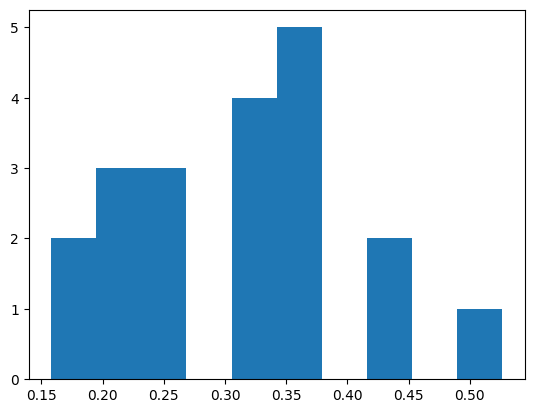

In [ ]:
# Graficar la distribución de grados de la red de colaboración de GitHub
plt.hist(list(nx.degree_centrality(G).values()))
plt.show()


## Caracterización de la red (III)

El último ejercicio trataba sobre la centralidad de grado; ¡esta vez vamos a recordar la centralidad de intermediación!

Una pequeña nota: si se ejecuta correctamente, este ejercicio puede necesitar alrededor de 5 segundos para ejecutarse.

**Instrucciones**

- Grafica la distribución de la centralidad de intermediación de la red de colaboración de GitHub. Debes seguir exactamente los mismos cuatro pasos que en el ejercicio anterior, sustituyendo `nx.betweenness_centrality()` por `nx.degree_centrality()`.

In [ ]:
nodes = {'u41': {'bipartite': 'users', 'grouping': 0}, 'u69': {'bipartite': 'users', 'grouping': 0}, 'u96': {'bipartite': 'users', 'grouping': 0}, 'u156': {'bipartite': 'users', 'grouping': 0}, 'u297': {'bipartite': 'users', 'grouping': 0}, 'u298': {'bipartite': 'users', 'grouping': 0}, 'u315': {'bipartite': 'users', 'grouping': 0}, 'u322': {'bipartite': 'users', 'grouping': 0}, 'u435': {'bipartite': 'users', 'grouping': 0}, 'u440': {'bipartite': 'users', 'grouping': 0}, 'u640': {'bipartite': 'users', 'grouping': 0}, 'u655': {'bipartite': 'users', 'grouping': 0}, 'u698': {'bipartite': 'users', 'grouping': 0}, 'u821': {'bipartite': 'users', 'grouping': 0}, 'u863': {'bipartite': 'users', 'grouping': 0}, 'u901': {'bipartite': 'users', 'grouping': 0}, 'u914': {'bipartite': 'users', 'grouping': 0}, 'u1254': {'bipartite': 'users', 'grouping': 0}, 'u1407': {'bipartite': 'users', 'grouping': 0}, 'u1468': {'bipartite': 'users', 'grouping': 0}, 'u1908': {'bipartite': 'users', 'grouping': 0}, 'u2022': {'bipartite': 'users', 'grouping': 0}, 'u2066': {'bipartite': 'users', 'grouping': 0}, 'u2137': {'bipartite': 'users', 'grouping': 0}, 'u2289': {'bipartite': 'users', 'grouping': 0}, 'u2482': {'bipartite': 'users', 'grouping': 0}, 'u2552': {'bipartite': 'users', 'grouping': 0}, 'u2643': {'bipartite': 'users', 'grouping': 0}, 'u2737': {'bipartite': 'users', 'grouping': 0}, 'u2906': {'bipartite': 'users', 'grouping': 0}, 'u3083': {'bipartite': 'users', 'grouping': 0}, 'u3174': {'bipartite': 'users', 'grouping': 0}, 'u3231': {'bipartite': 'users', 'grouping': 0}, 'u3243': {'bipartite': 'users', 'grouping': 0}, 'u3271': {'bipartite': 'users', 'grouping': 0}, 'u3658': {'bipartite': 'users', 'grouping': 0}, 'u3974': {'bipartite': 'users', 'grouping': 0}, 'u3979': {'bipartite': 'users', 'grouping': 0}, 'u4159': {'bipartite': 'users', 'grouping': 0}, 'u4199': {'bipartite': 'users', 'grouping': 0}, 'u4329': {'bipartite': 'users', 'grouping': 0}, 'u4412': {'bipartite': 'users', 'grouping': 0}, 'u4513': {'bipartite': 'users', 'grouping': 0}, 'u4710': {'bipartite': 'users', 'grouping': 0}, 'u4761': {'bipartite': 'users', 'grouping': 0}, 'u4953': {'bipartite': 'users', 'grouping': 0}, 'u5082': {'bipartite': 'users', 'grouping': 0}, 'u5337': {'bipartite': 'users', 'grouping': 0}, 'u5693': {'bipartite': 'users', 'grouping': 0}, 'u5993': {'bipartite': 'users', 'grouping': 0}, 'u6081': {'bipartite': 'users', 'grouping': 0}, 'u7418': {'bipartite': 'users', 'grouping': 0}, 'u7623': {'bipartite': 'users', 'grouping': 0}, 'u7963': {'bipartite': 'users', 'grouping': 0}, 'u8135': {'bipartite': 'users', 'grouping': 0}, 'u9866': {'bipartite': 'users', 'grouping': 0}, 'u9869': {'bipartite': 'users', 'grouping': 0}, 'u9997': {'bipartite': 'users', 'grouping': 0}, 'u10090': {'bipartite': 'users', 'grouping': 0}, 'u10340': {'bipartite': 'users', 'grouping': 0}, 'u10500': {'bipartite': 'users', 'grouping': 0}, 'u10603': {'bipartite': 'users', 'grouping': 0}, 'u14964': {'bipartite': 'users', 'grouping': 1}}
edges = [('u41', 'u2022', {}), ('u41', 'u69', {}), ('u41', 'u5082', {}), ('u41', 'u298', {}), ('u41', 'u901', {}), ('u69', 'u315', {}), ('u69', 'u4513', {}), ('u69', 'u5082', {}), ('u69', 'u901', {}), ('u69', 'u298', {}), ('u69', 'u2022', {}), ('u96', 'u315', {}), ('u96', 'u2482', {}), ('u96', 'u10500', {}), ('u96', 'u2022', {}), ('u96', 'u863', {}), ('u96', 'u9997', {}), ('u96', 'u297', {}), ('u96', 'u698', {}), ('u96', 'u2066', {}), ('u96', 'u7963', {}), ('u96', 'u156', {}), ('u96', 'u2906', {}), ('u96', 'u2552', {}), ('u156', 'u315', {}), ('u156', 'u2482', {}), ('u156', 'u10500', {}), ('u156', 'u863', {}), ('u156', 'u2022', {}), ('u156', 'u297', {}), ('u156', 'u9997', {}), ('u156', 'u698', {}), ('u156', 'u2066', {}), ('u156', 'u7963', {}), ('u156', 'u2906', {}), ('u156', 'u2552', {}), ('u297', 'u315', {}), ('u297', 'u2482', {}), ('u297', 'u863', {}), ('u297', 'u2022', {}), ('u297', 'u9997', {}), ('u297', 'u698', {}), ('u297', 'u10500', {}), ('u297', 'u2066', {}), ('u297', 'u7963', {}), ('u297', 'u2906', {}), ('u297', 'u2552', {}), ('u298', 'u5082', {}), ('u298', 'u901', {}), ('u298', 'u2022', {}), ('u315', 'u2482', {}), ('u315', 'u10500', {}), ('u315', 'u2022', {}), ('u315', 'u863', {}), ('u315', 'u9997', {}), ('u315', 'u698', {}), ('u315', 'u2066', {}), ('u315', 'u7963', {}), ('u315', 'u2906', {}), ('u315', 'u4513', {}), ('u315', 'u2552', {}), ('u322', 'u3174', {}), ('u322', 'u3974', {}), ('u322', 'u7623', {}), ('u322', 'u8135', {}), ('u322', 'u2022', {}), ('u322', 'u4953', {}), ('u322', 'u640', {}), ('u322', 'u4412', {}), ('u322', 'u10340', {}), ('u322', 'u4159', {}), ('u322', 'u1908', {}), ('u322', 'u3979', {}), ('u322', 'u435', {}), ('u322', 'u821', {}), ('u322', 'u9869', {}), ('u322', 'u9866', {}), ('u322', 'u10603', {}), ('u322', 'u3083', {}), ('u322', 'u4710', {}), ('u435', 'u7623', {}), ('u435', 'u8135', {}), ('u435', 'u2022', {}), ('u435', 'u10603', {}), ('u435', 'u10340', {}), ('u435', 'u9866', {}), ('u440', 'u5693', {}), ('u440', 'u2643', {}), ('u440', 'u10090', {}), ('u440', 'u3271', {}), ('u640', 'u1908', {}), ('u640', 'u3174', {}), ('u640', 'u3979', {}), ('u640', 'u3974', {}), ('u640', 'u821', {}), ('u640', 'u4953', {}), ('u640', 'u4412', {}), ('u640', 'u9869', {}), ('u640', 'u4159', {}), ('u640', 'u4710', {}), ('u640', 'u3083', {}), ('u655', 'u2643', {}), ('u655', 'u2906', {}), ('u655', 'u2137', {}), ('u655', 'u914', {}), ('u655', 'u4513', {}), ('u698', 'u10500', {}), ('u698', 'u2066', {}), ('u698', 'u2906', {}), ('u698', 'u2552', {}), ('u698', 'u9997', {}), ('u698', 'u7963', {}), ('u698', 'u2482', {}), ('u698', 'u863', {}), ('u698', 'u2022', {}), ('u821', 'u3174', {}), ('u821', 'u3974', {}), ('u821', 'u4953', {}), ('u821', 'u4412', {}), ('u821', 'u4159', {}), ('u821', 'u1908', {}), ('u821', 'u3979', {}), ('u821', 'u9869', {}), ('u821', 'u4710', {}), ('u821', 'u3083', {}), ('u863', 'u10500', {}), ('u863', 'u2022', {}), ('u863', 'u7963', {}), ('u863', 'u2906', {}), ('u863', 'u2482', {}), ('u863', 'u9997', {}), ('u863', 'u2552', {}), ('u863', 'u2066', {}), ('u901', 'u2022', {}), ('u901', 'u5082', {}), ('u914', 'u2022', {}), ('u914', 'u3231', {}), ('u1254', 'u2737', {}), ('u1254', 'u2289', {}), ('u1254', 'u2643', {}), ('u1254', 'u4329', {}), ('u1254', 'u4761', {}), ('u1407', 'u2643', {}), ('u1407', 'u6081', {}), ('u1407', 'u3658', {}), ('u1468', 'u5993', {}), ('u1468', 'u2643', {}), ('u1468', 'u2022', {}), ('u1468', 'u7418', {}), ('u1468', 'u5337', {}), ('u1468', 'u9869', {}), ('u1908', 'u3174', {}), ('u1908', 'u3979', {}), ('u1908', 'u3974', {}), ('u1908', 'u4953', {}), ('u1908', 'u4412', {}), ('u1908', 'u9869', {}), ('u1908', 'u4159', {}), ('u1908', 'u4710', {}), ('u1908', 'u3083', {}), ('u2022', 'u2482', {}), ('u2022', 'u5993', {}), ('u2022', 'u7623', {}), ('u2022', 'u8135', {}), ('u2022', 'u10500', {}), ('u2022', 'u10340', {}), ('u2022', 'u9997', {}), ('u2022', 'u3231', {}), ('u2022', 'u2643', {}), ('u2022', 'u2906', {}), ('u2022', 'u5082', {}), ('u2022', 'u4199', {}), ('u2022', 'u9869', {}), ('u2022', 'u2066', {}), ('u2022', 'u9866', {}), ('u2022', 'u7418', {}), ('u2022', 'u7963', {}), ('u2022', 'u5337', {}), ('u2022', 'u10603', {}), ('u2022', 'u2552', {}), ('u2066', 'u10500', {}), ('u2066', 'u7963', {}), ('u2066', 'u2906', {}), ('u2066', 'u2482', {}), ('u2066', 'u9997', {}), ('u2066', 'u2552', {}), ('u2137', 'u2643', {}), ('u2137', 'u4513', {}), ('u2289', 'u4329', {}), ('u2289', 'u4761', {}), ('u2289', 'u2643', {}), ('u2289', 'u2737', {}), ('u2482', 'u10500', {}), ('u2482', 'u7963', {}), ('u2482', 'u2906', {}), ('u2482', 'u9997', {}), ('u2482', 'u2552', {}), ('u2552', 'u10500', {}), ('u2552', 'u9997', {}), ('u2552', 'u2906', {}), ('u2552', 'u7963', {}), ('u2643', 'u10090', {}), ('u2643', 'u5993', {}), ('u2643', 'u5693', {}), ('u2643', 'u4329', {}), ('u2643', 'u4761', {}), ('u2643', 'u9869', {}), ('u2643', 'u6081', {}), ('u2643', 'u2737', {}), ('u2643', 'u3658', {}), ('u2643', 'u3243', {}), ('u2643', 'u7418', {}), ('u2643', 'u5337', {}), ('u2643', 'u4513', {}), ('u2643', 'u3271', {}), ('u2737', 'u4329', {}), ('u2737', 'u4761', {}), ('u2906', 'u10500', {}), ('u2906', 'u9997', {}), ('u2906', 'u7963', {}), ('u3083', 'u3174', {}), ('u3083', 'u3974', {}), ('u3083', 'u4953', {}), ('u3083', 'u4412', {}), ('u3083', 'u4159', {}), ('u3083', 'u3979', {}), ('u3083', 'u9869', {}), ('u3083', 'u4710', {}), ('u3174', 'u3974', {}), ('u3174', 'u4953', {}), ('u3174', 'u4412', {}), ('u3174', 'u4159', {}), ('u3174', 'u3979', {}), ('u3174', 'u9869', {}), ('u3174', 'u4710', {}), ('u3231', 'u4159', {}), ('u3243', 'u3271', {}), ('u3271', 'u10090', {}), ('u3271', 'u5693', {}), ('u3658', 'u6081', {}), ('u3974', 'u4953', {}), ('u3974', 'u4412', {}), ('u3974', 'u4159', {}), ('u3974', 'u3979', {}), ('u3974', 'u9869', {}), ('u3974', 'u4710', {}), ('u3979', 'u4953', {}), ('u3979', 'u4412', {}), ('u3979', 'u4159', {}), ('u3979', 'u9869', {}), ('u3979', 'u4710', {}), ('u4159', 'u4412', {}), ('u4159', 'u9869', {}), ('u4159', 'u4710', {}), ('u4159', 'u4953', {}), ('u4329', 'u4761', {}), ('u4412', 'u4953', {}), ('u4412', 'u9869', {}), ('u4412', 'u4710', {}), ('u4710', 'u4953', {}), ('u4710', 'u9869', {}), ('u4953', 'u9869', {}), ('u5337', 'u5993', {}), ('u5337', 'u7418', {}), ('u5337', 'u9869', {}), ('u5693', 'u10090', {}), ('u5993', 'u7418', {}), ('u5993', 'u9869', {}), ('u7418', 'u9869', {}), ('u7623', 'u8135', {}), ('u7623', 'u10603', {}), ('u7623', 'u10340', {}), ('u7623', 'u9866', {}), ('u7963', 'u10500', {}), ('u7963', 'u9997', {}), ('u8135', 'u10603', {}), ('u8135', 'u10340', {}), ('u8135', 'u9866', {}), ('u9866', 'u10603', {}), ('u9866', 'u10340', {}), ('u9997', 'u10500', {}), ('u10340', 'u10603', {})]

# Crear un grafo vacío
g_413 = nx.Graph()

# Agregar nodos al grafo
g_413.add_nodes_from(nodes)

# Agregar aristas (conexiones) al grafo
g_413.add_edges_from(edges)

# Establecer atributos de nodo en el grafo (por ejemplo, para asignar atributos a los nodos)
nx.set_node_attributes(g_413, nodes)

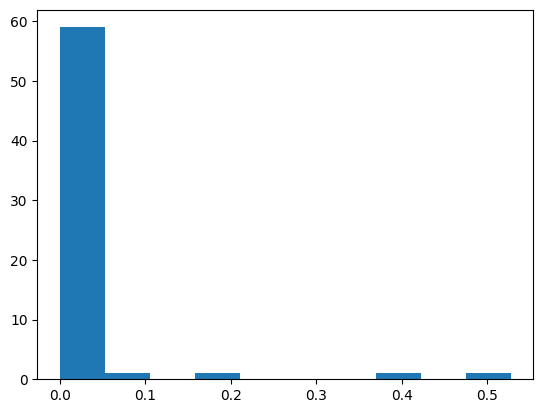

In [ ]:
# Graficar la distribución de la centralidad de intermediación de la red de colaboración de GitHub
plt.hist(list(nx.betweenness_centrality(g_413).values()))
plt.show()


# Estudio de caso: Visualización

- Practicando la creación de gráficos Circos, Hive y Arc

## Subgrafos de componentes conexas
- La siguiente figura contiene dos subgrafos de componentes conexas.
- El de la izquierda, que contiene el nodo amarillo, y el de la derecha, que contiene el nodo morado.
- No hay aristas que conecten el grafo de la izquierda con el grafo de la derecha.
- Un subgrafo de componente conexa es un conjunto de nodos conectados entre sí por algún camino en el subgrafo, y no conectados con otros nodos en el grafo más grande.
- ![subgrafo_de_componente_conexa][1]

  [1]: https://raw.githubusercontent.com/trenton3983/DataCamp/master/Images/2020-05-21_intro_to_network_analysis_in_python/con_com_sub.JPG

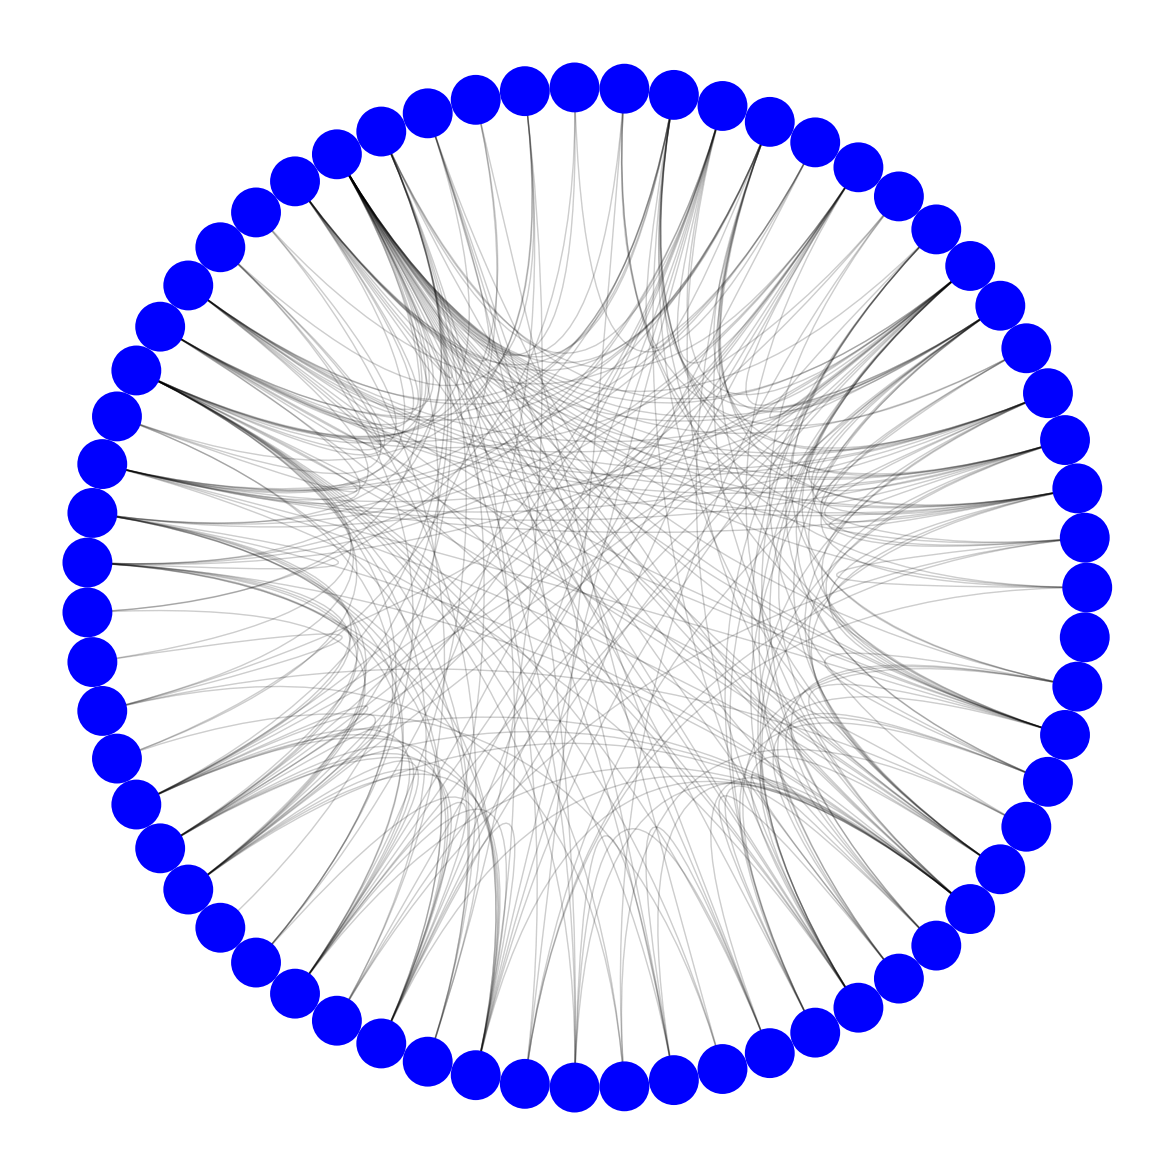

In [ ]:
# Establece la semilla para el generador de números aleatorios
random.seed(121)

# Genera un grafo aleatorio de tipo Erdős-Rényi con 20 nodos y probabilidad de 0.3 para las aristas
G = nx.erdos_renyi_graph(n=20, p=0.3)

# Crea la figura con un tamaño mayor
plt.figure(figsize=(15, 15))  # Ajusta el tamaño de la figura para hacerla más grande

# Visualiza el grafo usando el diseño Circos
ax = nv.circos(g_413)  # node_color_by='key', group_by='key')


In [ ]:
# Establece la semilla para el generador de números aleatorios
random.seed(60)

# Genera un grafo aleatorio de tipo Erdős-Rényi con 100 nodos y probabilidad de 0.03 para las aristas
G = nx.erdos_renyi_graph(n=100, p=0.03)

# Calcula los componentes conexos del grafo
nx.connected_components(G)  # connected_componet_subgraphs() está obsoleto


<generator object connected_components at 0x7f48715b8c80>

In [ ]:
# Obtiene los componentes conexos del grafo
subgraphs = [G.subgraph(c) for c in nx.connected_components(G)]

# Muestra los subgrafos obtenidos
subgraphs


Subgraph has 96 nodes


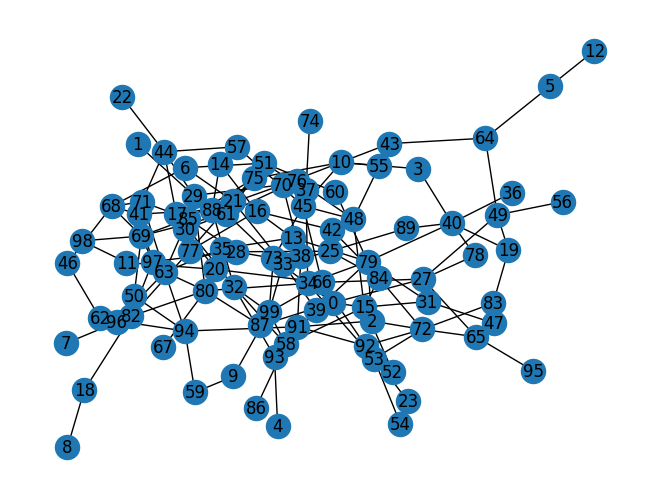

Subgraph has 1 nodes


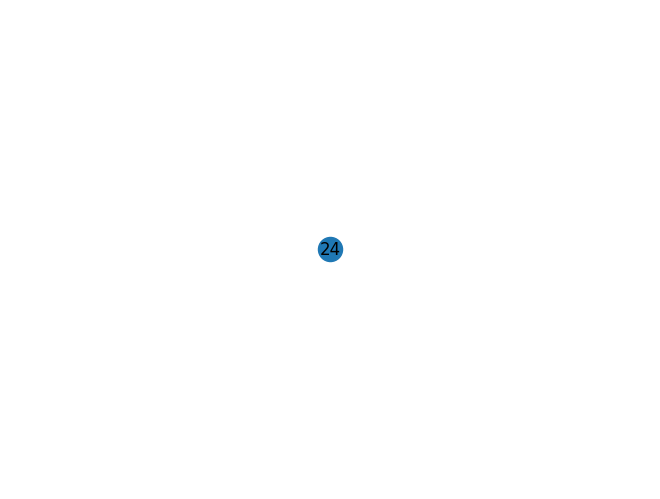

Subgraph has 1 nodes


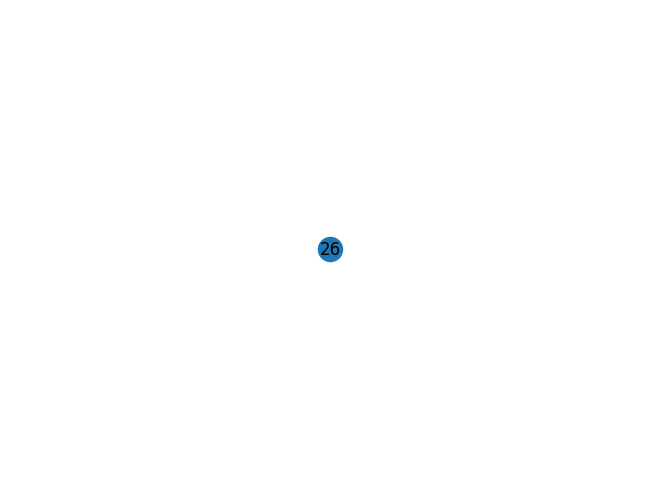

Subgraph has 1 nodes


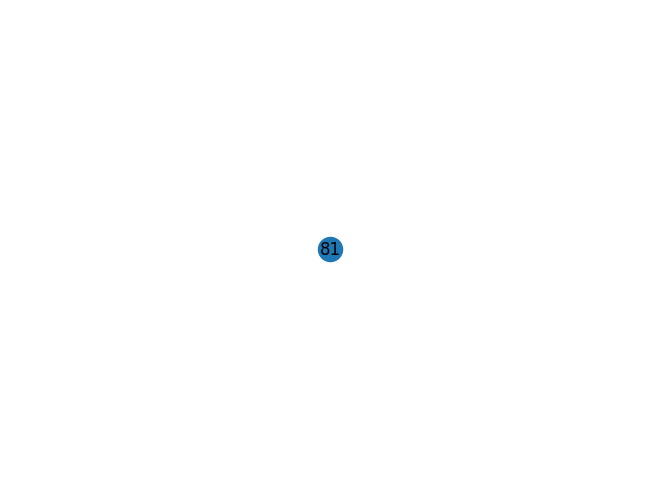

Subgraph has 1 nodes


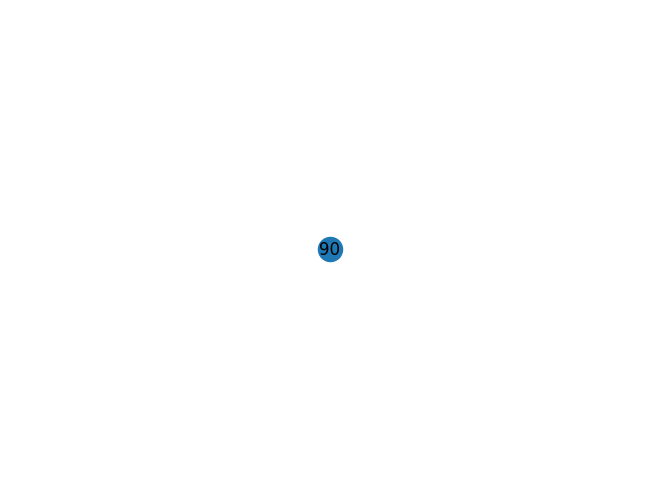

In [ ]:
# Itera sobre cada subgrafo en la lista de subgrafos
for sg in subgraphs:
    # Muestra cuántos nodos tiene el subgrafo
    print(f'Subgraph has {len(sg.nodes())} nodes')

    # Dibuja el subgrafo con etiquetas para los nodos
    nx.draw(sg, with_labels=True)

    # Muestra el grafo
    plt.show()


# MatrixPlot

Ahora vamos a practicar creando algunas visualizaciones. La primera será el MatrixPlot. En un MatrixPlot, la matriz es la representación de las aristas.

**Instrucciones**

- Realiza una visualización MatrixPlot del subgrafo de la componente conexa más grande, con los autores agrupados por su número de grupo de usuario.
  - Primero, calcula el subgrafo de la componente conexa más grande usando `nx.connected_component_subgraphs(G)` dentro de la función `sorted()` proporcionada. La función incorporada de Python [sorted()][1] toma un iterable y devuelve una lista ordenada (por defecto en orden ascendente). Por lo tanto, para acceder al subgrafo de la componente conexa más grande, se utiliza el índice `[-1]`.
  - Crea el objeto `MatrixPlot` llamado `h`. Debes especificar los parámetros `graph` y `node_grouping` como el subgrafo de la componente conexa más grande y `'grouping'`, respectivamente.
  - Dibuja el objeto `MatrixPlot` en la pantalla y muestra la gráfica.

[1]: https://docs.python.org/2/library/functions.html#sorted

In [ ]:
# Crear una lista de subgrafos, uno para cada componente conectada en el grafo
subgraphs = [g_413.subgraph(c) for c in nx.connected_components(g_413)]

# Mostrar la lista de subgrafos
subgraphs


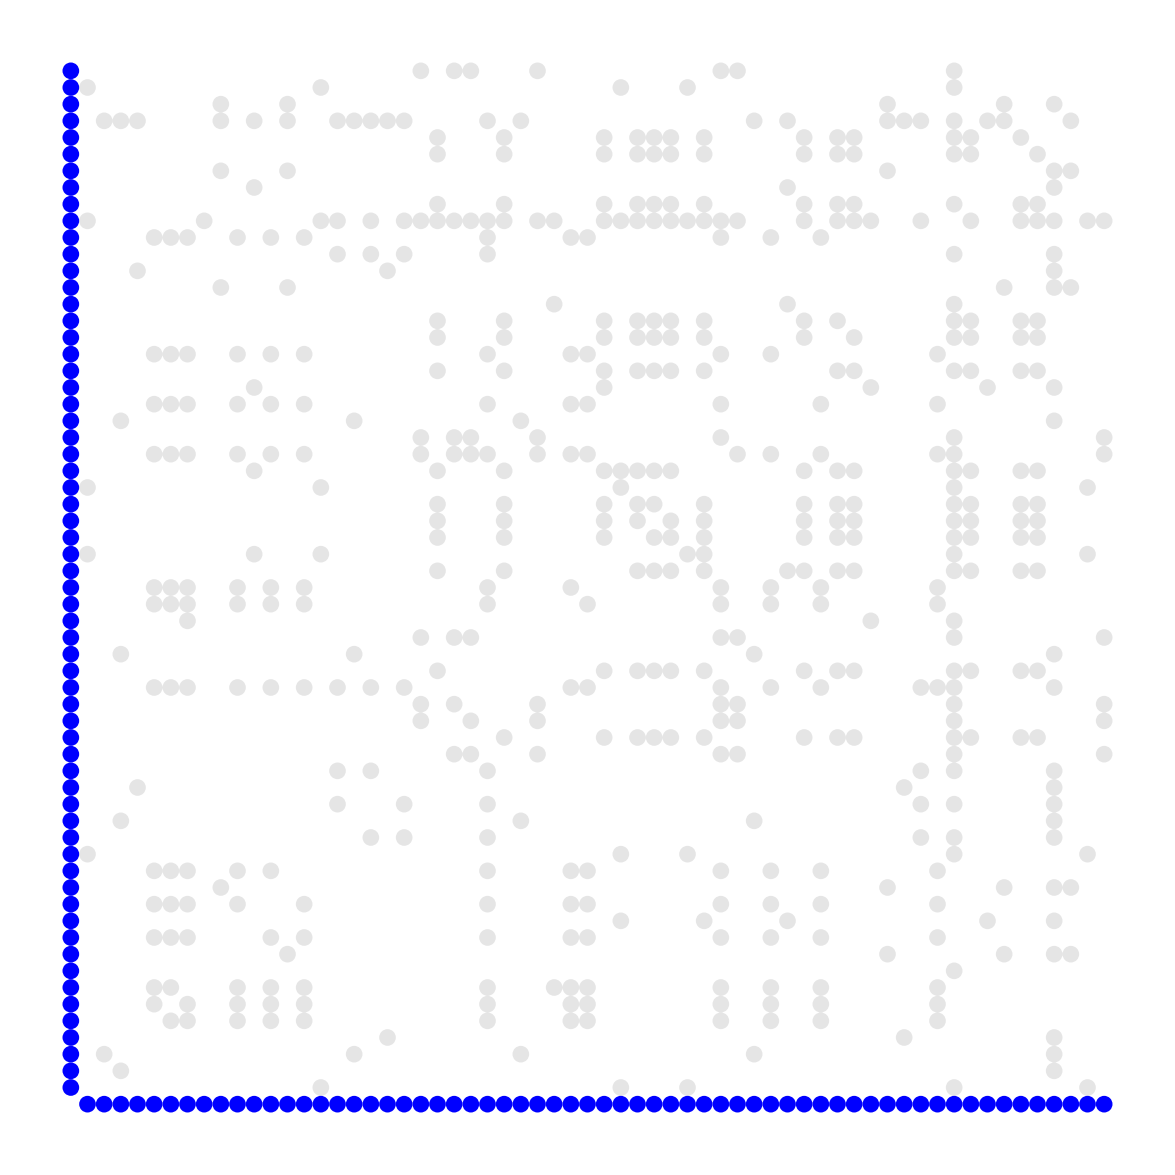

In [ ]:
## Calcula el subgrafo de la componente conexa más grande: largest_ccs
largest_ccs = sorted(subgraphs, key=lambda x: len(x))[-1]  # Ordena las subgráficas por su tamaño y selecciona la más grande

# Crea la figura con un tamaño mayor
plt.figure(figsize=(15, 15))  # Ajusta el tamaño de la figura para hacerla más grande

# Crea el objeto MatrixPlot personalizado: h
ax = nv.matrix(largest_ccs, group_by='grouping')  # Crea el gráfico tipo matriz, agrupando por 'grouping'


**Recuerda que en un MatrixPlot, los nodos son las filas y columnas de la matriz, y las celdas se rellenan según si existe una arista entre los pares de nodos.**

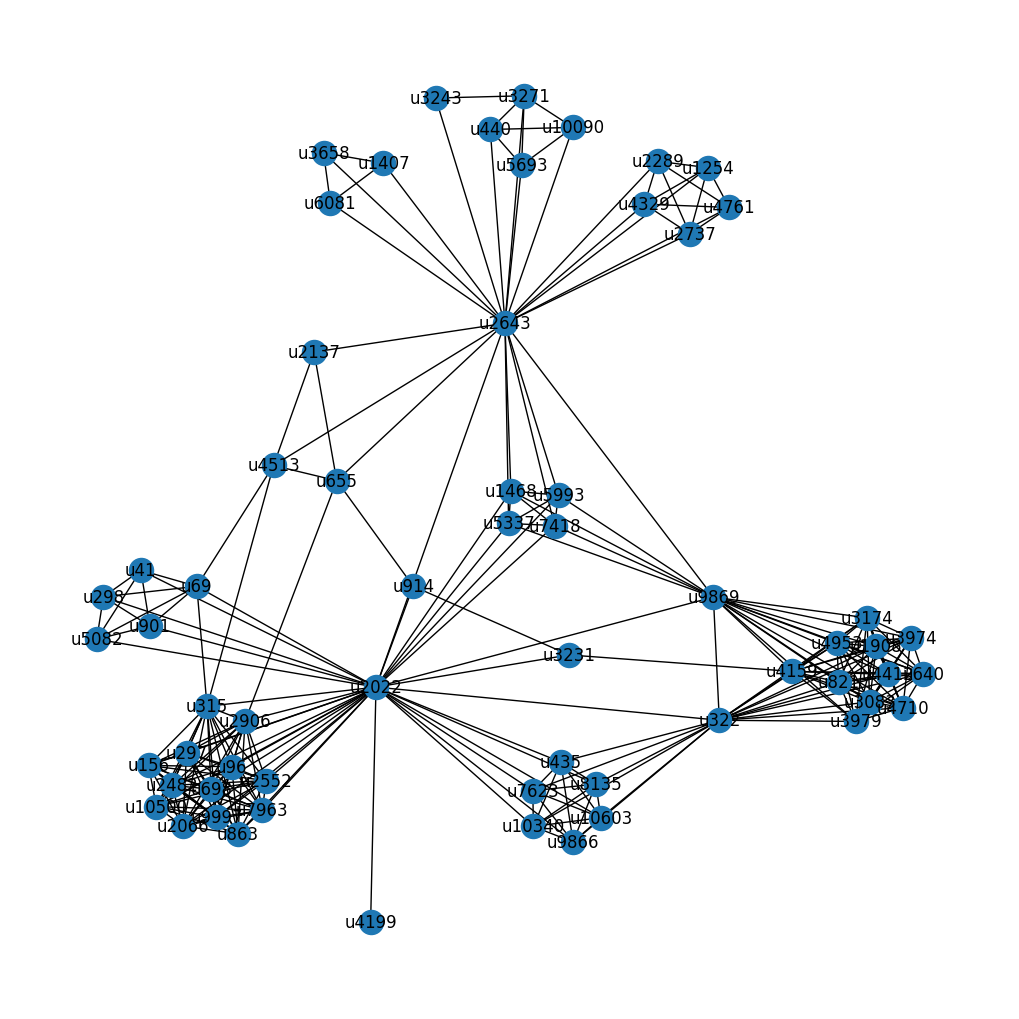

In [ ]:
# Ajusta el tamaño de la figura antes de dibujar el grafo
plt.figure(figsize=(10, 10))

# Dibuja el subgrafo de la componente conectada más grande, mostrando las etiquetas de los nodos
nx.draw(largest_ccs, with_labels=True)

# Muestra el grafo
plt.show()


## ArcPlot

A continuación, vamos a utilizar el ArcPlot para visualizar la red. Practicarás también cómo ordenar los nodos del grafo.

Nota: este ejercicio puede tardar entre 4 y 7 segundos en ejecutarse si se hace correctamente.

**Instrucciones**

- Crea un ArcPlot de la red de colaboración de GitHub, con los autores ordenados por su grado. Para ello:
  - Itera sobre todos los nodos en `G`, incluyendo los metadatos (especificando `data=True`).
  - En cada iteración del bucle, calcula el grado de cada nodo `n` con `nx.degree()` y establece su atributo `'degree'`. `nx.degree()` acepta dos argumentos: un grafo y un nodo.
  - Crea el objeto `ArcPlot` llamado `a`, especificando dos parámetros: el `graph`, que es `G`, y el `node_order`, que es `'degree'`, para que los nodos estén ordenados.
  - Dibuja el objeto `ArcPlot` en la pantalla.

In [ ]:
# Itera sobre todos los nodos en g_413, incluyendo los metadatos
for n, d in g_413.nodes(data=True):

    # Calcula el grado de cada nodo y lo almacena en el atributo 'degree' del nodo
    g_413.nodes[n]['degree'] = nx.degree(g_413, n)

# Crea el objeto ArcPlot con los parámetros indicados
plt.figure(figsize=(10, 10))  # Establece el tamaño de la figura
ax = nv.arc(g_413, sort_by='degree', group_by='grouping', node_color_by='grouping')  # Dibuja el ArcPlot


## CircosPlot

¡Finalmente, vas a crear un CircosPlot de la red!

**Instrucciones**

- Crea un CircosPlot de la red, nuevamente con los usuarios de GitHub ordenados por su grado, y agrupados y coloreados según su clave `'grouping'`. Para ello:
  - Itera sobre todos los nodos en `G`, incluyendo los metadatos (especificando `data=True`).
  - En cada iteración del bucle, calcula el grado de cada nodo `n` con `nx.degree()` y establece su atributo `'degree'`.
  - Crea el objeto `CircosPlot` llamado `c`, especificando tres parámetros además del grafo `G`: el `node_order`, que es `'degree'`, el `node_grouping` y el `node_color`, que ambos son `'grouping'`.
  - Dibuja el objeto `CircosPlot` en la pantalla.

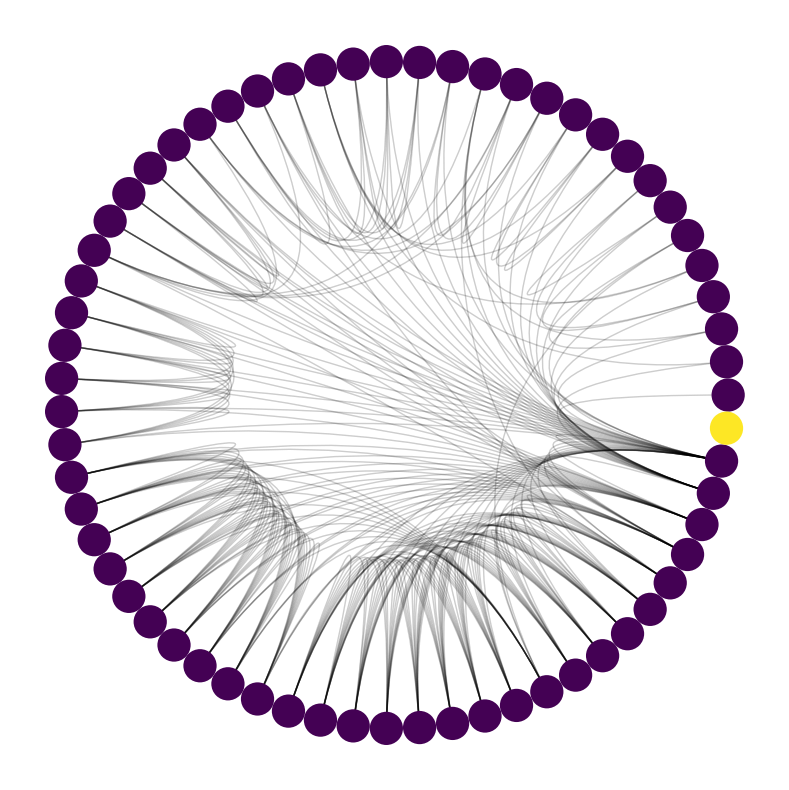

In [ ]:
# Itera sobre todos los nodos en g_413, incluyendo los metadatos
for n, d in g_413.nodes(data=True):

    # Calcula el grado de cada nodo y lo almacena en el atributo 'degree' del nodo
    g_413.nodes[n]['degree'] = nx.degree(g_413, n)

# Crea el objeto Circos con los parámetros indicados
plt.figure(figsize=(10, 10))  # Establece el tamaño de la figura
a = nv.circos(g_413, sort_by='degree', group_by='grouping', node_color_by='grouping')  # Dibuja el Circos Plot


**Este CircosPlot ofrece una alternativa compacta al ArcPlot. Es fácil ver en este gráfico que la mayoría de los usuarios pertenecen a un solo grupo.**

## Estudio de Caso: Cliques

- Un grupo de nodos que están completamente conectados entre sí.
- El clique más simple es un borde y el clique "complejo" más sencillo es un triángulo.
- Un clique máximo es un clique que no se puede extender agregando otro nodo en el grafo.

In [ ]:
## Genera un grafo aleatorio de tipo Erdős-Rényi con 100 nodos y una probabilidad de 0.15 para las aristas
G = nx.erdos_renyi_graph(n=100, p=0.15)

# Encuentra todos los cliques en el grafo G
print(nx.find_cliques(G))

# Cuenta la longitud de cada clico encontrado
clique_lens = Counter([len(clique) for clique in nx.find_cliques(G)])

# Muestra la cantidad de cliques de cada tamaño
clique_lens


<generator object find_cliques at 0x7f48715b8cf0>


Counter({3: 413, 2: 82, 4: 49, 5: 2})

## Encontrar cliques (I)

Ahora vas a practicar encontrar cliques en `G`. Recuerda que los cliques son "grupos de nodos que están completamente conectados entre sí", mientras que un clique máximo es un clique que no se puede extender agregando otro nodo en el grafo.

**Instrucciones**

- Cuenta el número de cliques máximos presentes en el grafo y imprímelo.
  - Usa la función `nx.find_cliques()` de `G` para encontrar los cliques máximos.
  - La función `nx.find_cliques()` devuelve un objeto generador. Para contar el número de cliques máximos, primero debes convertirlo en una lista con `list()` y luego usar la función `len()`. Coloca esto dentro de una función `print()` para imprimirlo.

In [ ]:
# Encuentra los cliques en el grafo g_413 y calcula la longitud de cada clique
cliques = sorted([len(cl) for cl in nx.find_cliques(g_413)], reverse=True)

# Imprime los tamaños de los cliques en orden descendente
print(cliques)

# Muestra la cantidad total de cliques encontrados
print(f'There are {len(cliques)} cliques.')


[14, 13, 8, 7, 6, 6, 5, 4, 4, 3, 3, 3, 3, 3, 2, 2, 2, 2, 1]
There are 19 cliques.


## Encontrar cliques (I)

Ahora vas a practicar encontrar cliques en `G`. Recuerda que los cliques son "grupos de nodos que están completamente conectados entre sí", mientras que un clique máximo es un clique que no se puede extender agregando otro nodo en el grafo.

**Instrucciones**

- Cuenta el número de cliques máximos presentes en el grafo y imprímelo.
  - Usa la función `nx.find_cliques()` de `G` para encontrar los cliques máximos.
  - La función `nx.find_cliques()` devuelve un objeto generador. Para contar el número de cliques máximos, primero debes convertirlo en una lista con `list()` y luego usar la función `len()`. Coloca esto dentro de una función `print()` para imprimirlo.

In [ ]:
# Encuentra el clique máximo más grande en el grafo g_413
largest_clique = sorted(nx.find_cliques(g_413), key=lambda x: len(x))[-1]

# Crea el subgrafo correspondiente al clique más grande
G_lc = g_413.subgraph(largest_clique)

# Itera sobre los nodos del subgrafo y agrega el nodo como un par clave-valor
for n, d in G_lc.nodes(data=True):
    G_lc.nodes[n]['node'] = n  # Agrega el nodo como un valor en el diccionario de datos
    print(n, d)  # Imprime el nodo y sus datos asociados


u7963 {'bipartite': 'users', 'grouping': 0, 'degree': 13, 'node': 'u7963'}
u2482 {'bipartite': 'users', 'grouping': 0, 'degree': 13, 'node': 'u2482'}
u698 {'bipartite': 'users', 'grouping': 0, 'degree': 13, 'node': 'u698'}
u156 {'bipartite': 'users', 'grouping': 0, 'degree': 13, 'node': 'u156'}
u2552 {'bipartite': 'users', 'grouping': 0, 'degree': 13, 'node': 'u2552'}
u2022 {'bipartite': 'users', 'grouping': 0, 'degree': 34, 'node': 'u2022'}
u315 {'bipartite': 'users', 'grouping': 0, 'degree': 15, 'node': 'u315'}
u297 {'bipartite': 'users', 'grouping': 0, 'degree': 13, 'node': 'u297'}
u96 {'bipartite': 'users', 'grouping': 0, 'degree': 13, 'node': 'u96'}
u2906 {'bipartite': 'users', 'grouping': 0, 'degree': 14, 'node': 'u2906'}
u2066 {'bipartite': 'users', 'grouping': 0, 'degree': 13, 'node': 'u2066'}
u9997 {'bipartite': 'users', 'grouping': 0, 'degree': 13, 'node': 'u9997'}
u10500 {'bipartite': 'users', 'grouping': 0, 'degree': 13, 'node': 'u10500'}
u863 {'bipartite': 'users', 'groupi

The largest maximal clique consists of 14 users


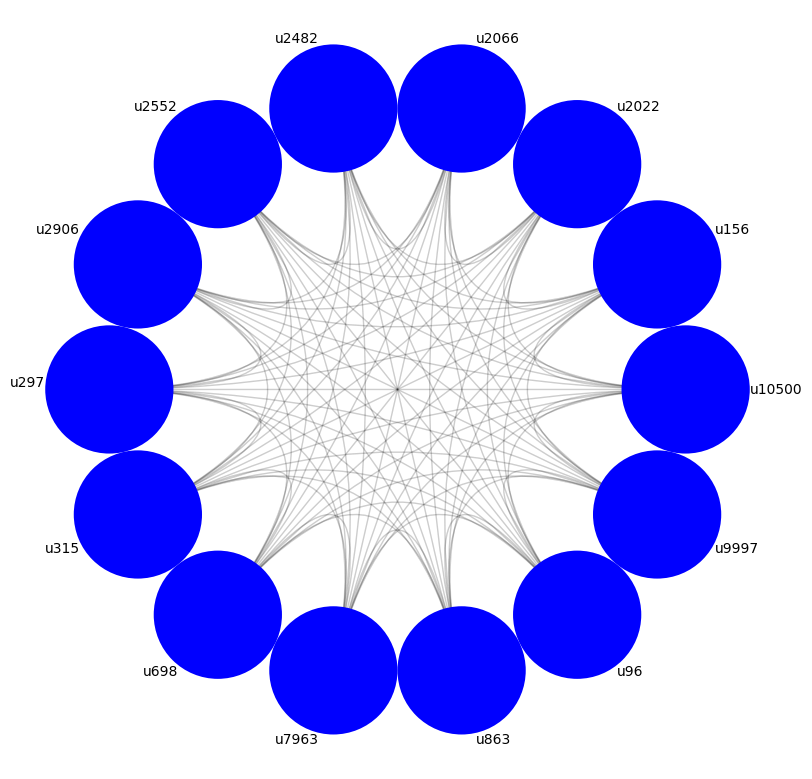

In [ ]:
# Crea el objeto CircosPlot: c
plt.figure(figsize=(10, 10))
c = nv.circos(G_lc)  # Genera el gráfico Circos para el subgrafo G_lc

# Anota los nodos en el gráfico utilizando la función 'annotate.circos_group'
annotate.circos_group(G_lc, group_by='node', radius_offset=1, midpoint=False)

# Dibuja el CircosPlot en la pantalla
print(f'The largest maximal clique consists of {len(largest_clique)} users')  # Imprime el número de usuarios en el clique


## Estudio de Caso: Tareas Finales

- Encontrar usuarios importantes de GitHub basados en sus relaciones de colaboración
  - Busca usuarios de GitHub que compartan colaboraciones con el mayor número de otros usuarios.
  - _centralidad de grado_
- Encontrar las comunidades más grandes de colaboradores.
  - Estarás buscando las comunidades más grandes de colaboradores.
  - _clique maximal_
- Crear un sistema de recomendaciones para usuarios de GitHub basado en el concepto de triángulos abiertos.
  - _triángulos abiertos_: Estoy conectado a dos personas que no están conectadas entre sí.

## Encontrando colaboradores importantes

Ahora mirarás de nuevo los nodos importantes. Aquí, utilizarás las funciones `degree_centrality()` y `betweenness_centrality()` de NetworkX para calcular los puntajes de centralidad respectivos y luego usar esa información para encontrar los "nodos importantes". En otras palabras, tu tarea en este ejercicio es encontrar el/los usuario(s) que han colaborado con la mayor cantidad de usuarios.

**Instrucciones**

- Calcula las centralidades de grado de `G`. Almacena el resultado como `deg_cent`.
- Calcula la centralidad de grado máxima. Dado que `deg_cent` es un diccionario, deberás usar el método `.values()` para obtener una lista de sus valores antes de calcular la centralidad de grado máxima con `max()`.
- Identifica los colaboradores más prolíficos usando una comprensión de lista:
  - Itera sobre el diccionario de centralidad de grado `deg_cent` que se calculó anteriormente utilizando su método `.items()`. ¿Qué condición debe cumplirse si deseas encontrar el/los usuario(s) que han colaborado con la mayor cantidad de usuarios? _Sugerencia_: Tiene que ver con la centralidad de grado máxima.
- ¡Haz clic en "Enviar Respuesta" para ver quién es/son el/los colaborador(es) más prolífico(s)!

In [ ]:
# Calcula las centralidades de grado de G: deg_cent
deg_cent = nx.degree_centrality(g_413)  # Calcula la centralidad de grado de cada nodo en el grafo

# Ordena el diccionario de centralidad de grado
deg_cent = {k: v for k, v in sorted(deg_cent.items(), key=lambda item: item[1], reverse=True)}

# Calcula la máxima centralidad de grado: max_dc
max_dc = max(list(deg_cent.values()))  # Encuentra el valor más alto de centralidad de grado

# Encuentra el/los usuario(s) que más han colaborado: prolific_collaborators
prolific_collaborators = [n for n, dc in deg_cent.items() if dc == max_dc]  # Encuentra los nodos con la máxima centralidad de grado

# Imprime el/los colaborador(es) más prolífico(s)
print(f'The most prolific collaborator(s): {prolific_collaborators}')  # Muestra el/los colaborador(es) más prolífico(s)


The most prolific collaborator(s): ['u2022']


In [ ]:
# Calcula el valor máximo de la centralidad de grado: max_dc
max_dc = max(list(deg_cent.values()))  # Encuentra el valor máximo dentro del diccionario de centralidad de grado


In [ ]:
# Calcula las centralidades de grado de G: deg_cent
deg_cent = nx.degree_centrality(g_413)  # Utiliza nx.degree_centrality para calcular la centralidad de grado de cada nodo en el grafo

# Ordena el diccionario de mayor a menor centralidad de grado
deg_cent = {k: v for k, v in sorted(deg_cent.items(), key=lambda item: item[1], reverse=True)}  # Ordena el diccionario por valor


## Caracterización de comunidades de edición

Ahora vas a combinar lo que has aprendido sobre el algoritmo BFS y el concepto de cliques máximos para visualizar la red con un ArcPlot.

El mayor clique máximo en la red de colaboración de usuarios de GitHub se ha asignado al subgrafo `G_lmc`. Ten en cuenta que para la versión 2.x y posteriores de `NetworkX`, `G.subgraph(nodelist)` solo devuelve una vista inmutable del grafo original. Debemos pedir explícitamente una `.copy()` del grafo para obtener una versión mutable.

**Instrucciones**

- Sal 1 grado de separación del clique y agrega esos usuarios al subgrafo. Dentro del primer bucle `for`:
  - Agrega nodos a `G_lmc` desde los vecinos de `G` utilizando los métodos `.add_nodes_from()` y `.neighbors()`.
  - Usando el método `.add_edges_from()`, agrega aristas a `G_lmc` entre el nodo actual y todos sus vecinos. Para hacerlo, tendrás que crear una lista de tuplas utilizando la función `zip()` que consista en el nodo actual y cada uno de sus vecinos. El primer argumento de `zip()` debe ser `[node]*len(list(G.neighbors(node)))`, y el segundo argumento debe ser los vecinos de `node`.
  - Registra la puntuación de centralidad de grado de cada nodo en sus metadatos de nodo.
  - Haz esto asignando `nx.degree_centrality(G_lmc)[n]` a `G_lmc.node[n]['degree centrality']` en el segundo bucle `for`.
  - Visualiza esta red con un ArcPlot ordenando los nodos por la centralidad de grado (puedes hacerlo usando el argumento de palabra clave `node_order='degree centrality'`).


{'u7963', 'u2482', 'u698', 'u156', 'u2552', 'u2022', 'u315', 'u297', 'u96', 'u2906', 'u2066', 'u9997', 'u10500', 'u863'}


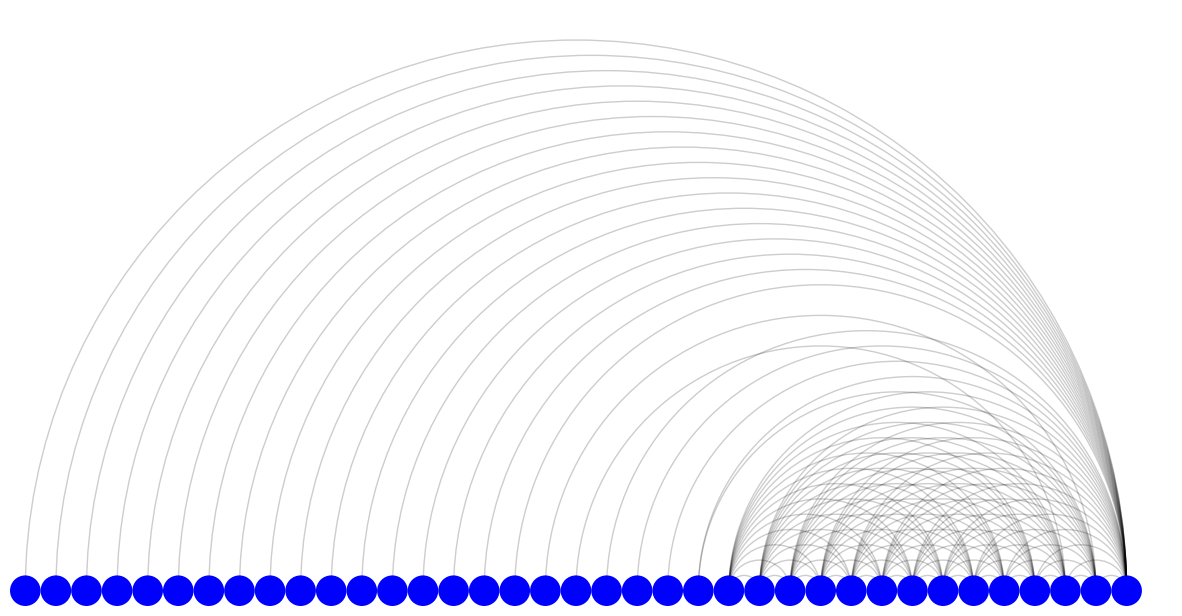

In [ ]:
# Identifica la cliqueta maximal más grande: largest_max_clique
largest_max_clique = set(sorted(nx.find_cliques(g_413), key=lambda x: len(x))[-1])  # Encuentra todas las cliquetas y selecciona la más grande por su longitud
print(largest_max_clique)

# Crea un subgrafo a partir de la largest_max_clique: G_lmc
G_lmc = g_413.subgraph(largest_max_clique).copy()  # Crea una copia del subgrafo que contiene solo la cliqueta más grande
display(G_lmc)

# Añade nodos a un grado de separación de distancia
for node in list(G_lmc.nodes()):  # Itera sobre todos los nodos del subgrafo
    G_lmc.add_nodes_from(g_413.neighbors(node))  # Añade los nodos vecinos de cada nodo
    G_lmc.add_edges_from(zip([node]*len(list(g_413.neighbors(node))), g_413.neighbors(node)))  # Añade los bordes entre los nodos y sus vecinos

# Registra la puntuación de centralidad de grado de cada nodo
for n in G_lmc.nodes():  # Itera sobre todos los nodos en el subgrafo G_lmc
    G_lmc.nodes[n]['degree centrality'] = nx.degree_centrality(G_lmc)[n]  # Calcula y asigna la centralidad de grado de cada nodo

# Crea la figura con un tamaño mayor
plt.figure(figsize=(15, 15))  # Ajusta el tamaño de la figura para hacerla más grande

# Crea el objeto ArcPlot: a
a = nv.arc(G_lmc, sort_by='degree centrality')  # Crea un gráfico ArcPlot ordenado por la centralidad de grado


## Recomendando coautores que aún no han editado juntos

Finalmente, vas a aprovechar el concepto de triángulos abiertos para recomendar usuarios de GitHub para colaborar.

**Instrucciones**

- Compila una lista de usuarios de GitHub que deberían ser recomendados para colaborar entre sí. Para hacerlo:
  - En el primer bucle `for`, itera sobre todos los nodos en `G`, incluyendo los metadatos (especificando `data=True`).
  - En el segundo bucle `for`, itera sobre todas las posibles combinaciones de triángulos, que pueden ser identificadas utilizando la función `combinations()` con un `size` de `2`.
  - Si `n1` y `n2` **no tienen** una arista entre ellos, se **debería** recomendar una colaboración entre estos dos nodos (usuarios), por lo que incrementa el valor `(n1), (n2)` en el diccionario `recommended` en este caso. Puedes verificar si `n1` y `n2` tienen o no una arista entre ellos usando el método `.has_edge()`.
- Usando una lista por comprensión, identifica los 10 principales pares de usuarios que deberían ser recomendados para colaborar. El _iterable_ debe ser los pares clave-valor del diccionario `recommended` (que se puede acceder con el método `.items()`), mientras que la condición debe cumplirse si `count` es _mayor_ que los 10 principales en `all_counts`. Ten en cuenta que `all_counts` está ordenado en orden ascendente, por lo que puedes acceder a los 10 principales con `all_counts[-10]`.

In [ ]:
# Crea un nuevo grafo G a partir del grafo Gh
G = nx.Graph(Gh)


In [ ]:
# Inicializa el defaultdict: recomendado
recomendado = defaultdict(int)

# Itera sobre todos los nodos en G
for n, d in g_413.nodes(data=True):

    # Itera sobre todas las combinaciones posibles de relaciones de triángulo
    for n1, n2 in combinations(g_413.neighbors(n), 2):

        # Verifica si n1 y n2 no tienen una arista entre ellos
        if not g_413.has_edge(n1, n2):

            # Incrementa recomendado
            recomendado[((n1), (n2))] += 1

# Identifica los 10 principales pares de usuarios
todos_los_contadores = sorted(recomendado.values())
pares_top10 = [par for par, contador in recomendado.items() if contador > todos_los_contadores[-10]]
print(f'Pares de usuarios que deberían colaborar: {pares_top10}')


Pares de usuarios que deberían colaborar: [('u2022', 'u4159'), ('u655', 'u2022')]


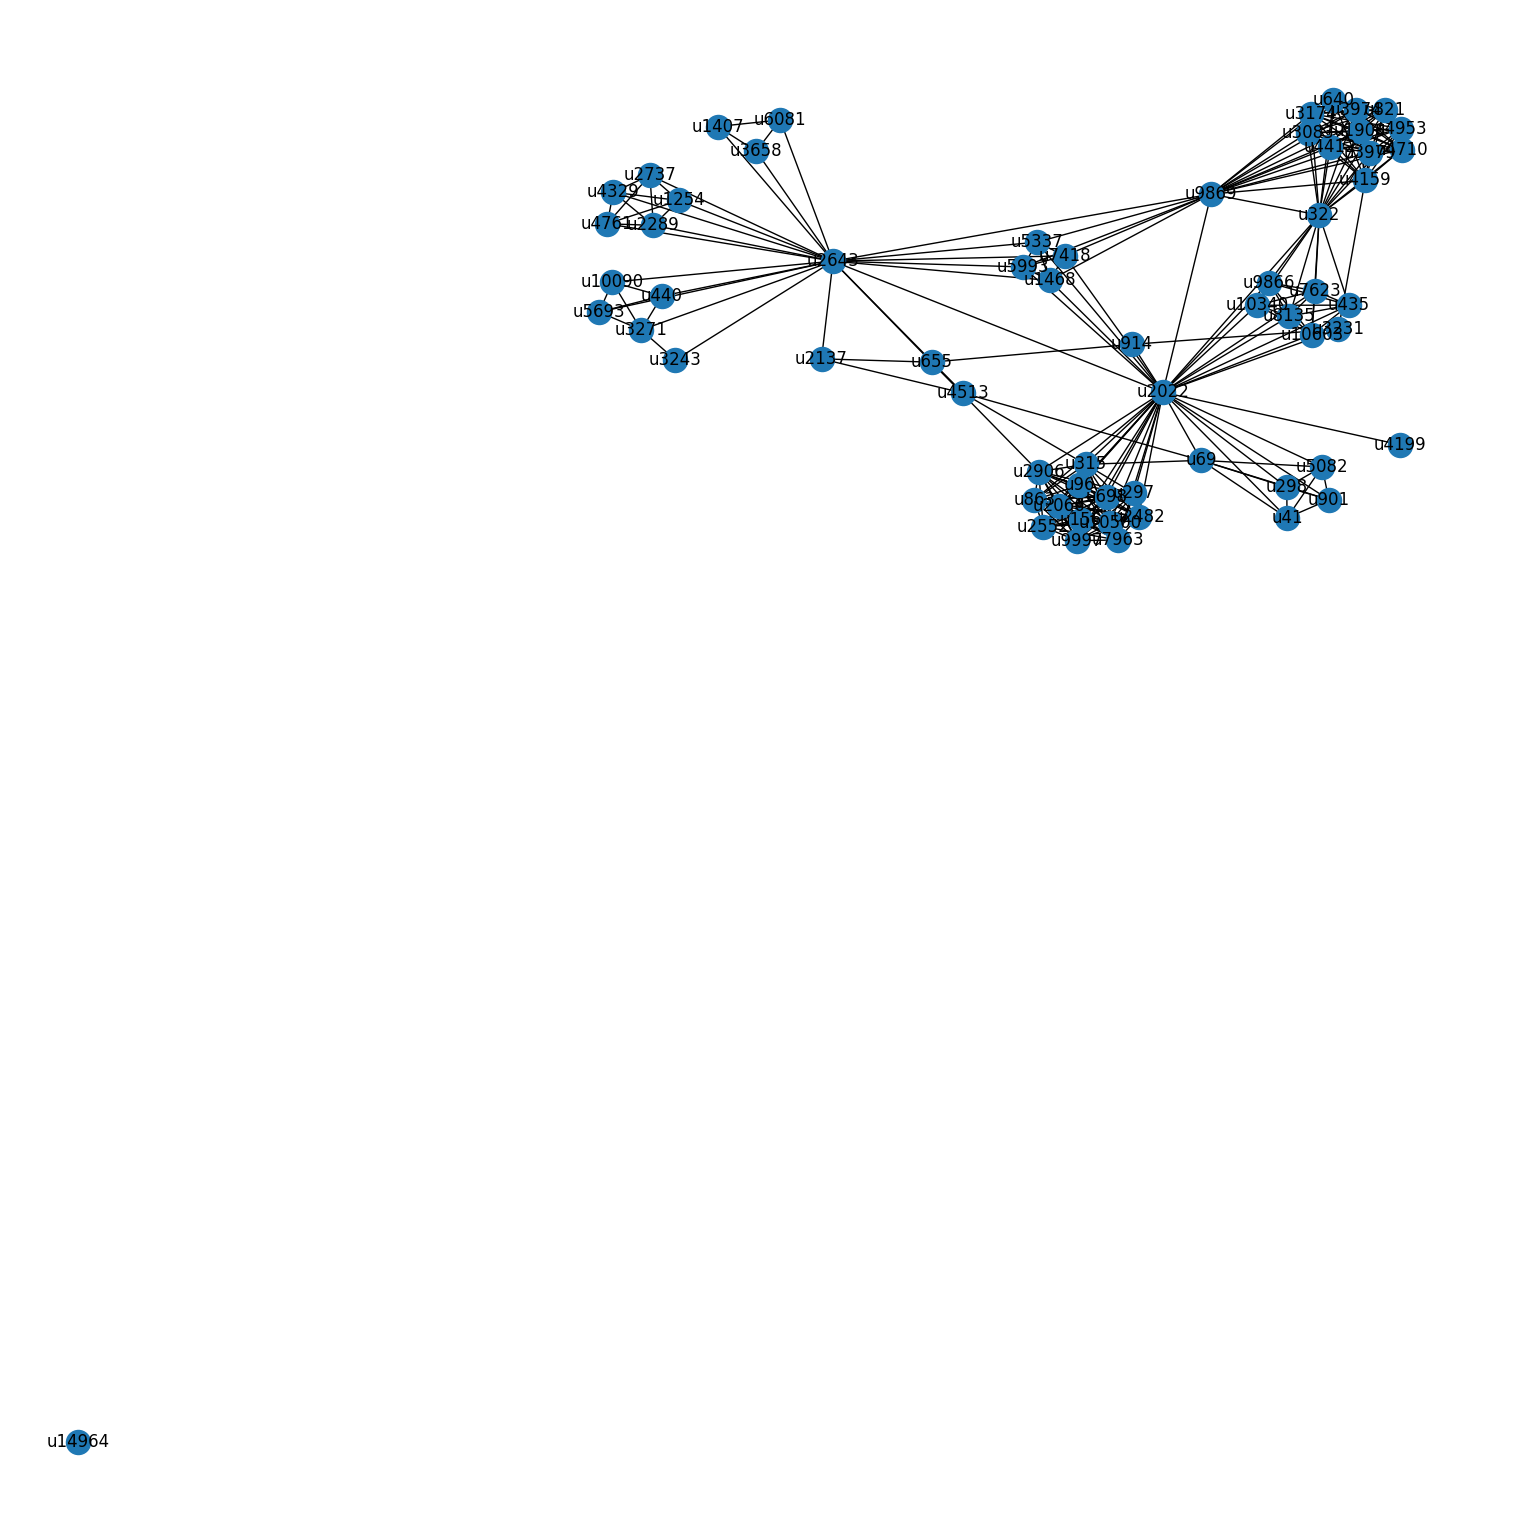

In [ ]:
# Establece el tamaño de la figura de la gráfica
plt.figure(figsize=(15, 15))

# Dibuja el grafo g_413 con etiquetas en los nodos
nx.draw(g_413, with_labels=True)

# Muestra la gráfica en pantalla
plt.show()


# Lo que has aprendido

- Los fundamentos de las redes y el análisis de redes.
- Cómo encontrar nodos importantes.
- Cómo identificar comunidades de nodos.
- Cómo aplicar estos conceptos en estudios de caso.
- Cómo usar los paquetes NetworkX y nxviz para modelar, analizar y visualizar datos de redes.
- Cómo escribir algoritmos que operen sobre redes para hacer cosas útiles, como encontrar rutas.
- Has visto la aplicación práctica del análisis de redes e incluso has intentado implementarlas.

# Certificate

![certificate](https://raw.githubusercontent.com/trenton3983/DataCamp/master/Images/2020-05-21_intro_to_network_analysis_in_python/2020-05-31_DataCamp_intro_to_network_analysis_in_python.jpg)